# COMBINED

In [1]:
import sys
from pathlib import Path
import numpy as np

# Adjust the project root if your notebook is in a different directory level
project_root = r"C:\Users\shresth.shankhdhar\OneDrive - hertshtengroup.com\Documents"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# Import the v2 analysis runner
from market_analysis.finding_threshold.absorption_v2_threshold import run_absorption_v2_threshold_analysis


Fetching and pre-computing labels for 10 instruments. Please wait...


c:\Users\shresth.shankhdhar\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


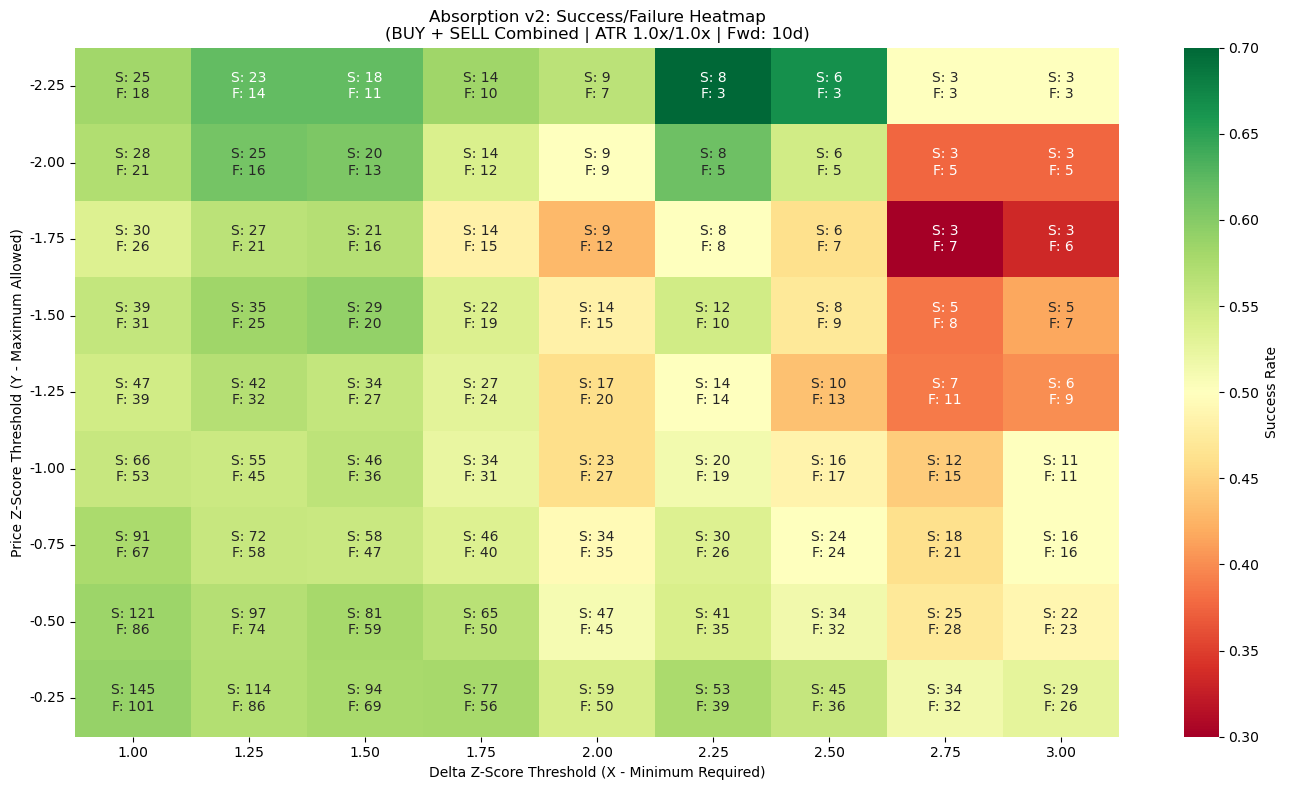

In [2]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the necessary modules from your project
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr

# ------------------------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------------------------
product_code = "SM"     # Change as needed
months_back = 8
front_n = 5

# Define the grids for the heatmap
delta_z_grid = np.arange(1.0, 3.25, 0.25)   # X-axis (e.g. 1.0 to 3.0)
price_z_grid = np.arange(-0.25, -2.5, -0.25)  # Y-axis (e.g. 0.25 to 1.5)

# Scorer parameters (z-score rolling window sizes)
v2_params = {
    "volume_window": 5,
    "atr_window": 5,
    "baseline_window": 15,
}

# ATR labeling parameters
atr_period = 14
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10

# ------------------------------------------------------------------------------
# 2. FETCH DATA & VECTORISED LABELING (Pre-computing outcomes)
# ------------------------------------------------------------------------------
start_date = (pd.Timestamp.now() - pd.DateOffset(months=months_back)).strftime("%Y-%m-%d")
end_date = pd.Timestamp.now().strftime("%Y-%m-%d")

# Gather all instruments
instruments = []
# EXPLICITLY pass reference_date=None and front_n=front_n to avoid the positional argument error
for insts in get_all_front_instruments(product_code, reference_date=None, front_n=front_n).values():
    instruments.extend(insts)

all_results = []
print(f"Fetching and pre-computing labels for {len(instruments)} instruments. Please wait...")

for inst in instruments:
    # 1. Fetch OHLC
    df = fetch_ohlc_1d(inst, product_code, getData_OHLC_v2, start_date, end_date)
    if df is None or len(df) < 30:
        continue
    
    # 2. Calculate z-scores (we pass dummy thresholds of 0 because we only need raw z_delta & z_price)
    df = calculate_absorption_v2(
        df, 
        volume_window=v2_params["volume_window"], 
        atr_window=v2_params["atr_window"], 
        baseline_window=v2_params["baseline_window"],
        delta_z_threshold=0, price_z_threshold=0
    )
    
    # 3. Trick the labeler: Evaluate EVERY bar as a potential BUY
    df["absorption_direction"] = "BUY"
    df_buy = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )
    
    # 4. Trick the labeler: Evaluate EVERY bar as a potential SELL
    df["absorption_direction"] = "SELL"
    df_sell = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )
    
    # 5. Extract only what we need for the heatmap to save memory
    res = pd.DataFrame({
        "z_delta": df["z_delta"],
        "z_price": df["z_price"],
        "buy_success": df_buy["sl_success"],
        "sell_success": df_sell["sl_success"]
    })
    
    all_results.append(res)

if not all_results:
    raise ValueError("No data found for the given parameters.")

# ------------------------------------------------------------------------------
# 3. COMPUTE HEATMAP MATRICES
# ------------------------------------------------------------------------------
pooled_df = pd.concat(all_results, ignore_index=True)

n_price = len(price_z_grid)
n_delta = len(delta_z_grid)

# Matrices for the heatmap
heat_rate = np.zeros((n_price, n_delta))
annot_labels = np.empty((n_price, n_delta), dtype=object)

for i, pz in enumerate(price_z_grid):
    for j, dz in enumerate(delta_z_grid):
        
        # BUY condition: delta is extreme (>= dz) AND price response is muted (<= pz)
        buy_mask = (pooled_df["z_delta"] >= dz) & (pooled_df["z_price"] <= pz)
        buy_succ = (pooled_df.loc[buy_mask, "buy_success"] == 1.0).sum()
        buy_fail = (pooled_df.loc[buy_mask, "buy_success"] == 0.0).sum()
        
        # SELL condition: delta is extreme (<= -dz) AND price response is muted (>= -pz)
        sell_mask = (pooled_df["z_delta"] <= -dz) & (pooled_df["z_price"] >= -pz)
        sell_succ = (pooled_df.loc[sell_mask, "sell_success"] == 1.0).sum()
        sell_fail = (pooled_df.loc[sell_mask, "sell_success"] == 0.0).sum()
        
        # Combined totals (BUY + SELL)
        tot_succ = buy_succ + sell_succ
        tot_fail = buy_fail + sell_fail
        tot_valid = tot_succ + tot_fail
        
        if tot_valid > 0:
            heat_rate[i, j] = tot_succ / tot_valid
            annot_labels[i, j] = f"S: {tot_succ}\nF: {tot_fail}"
        else:
            heat_rate[i, j] = np.nan
            annot_labels[i, j] = "N/A"

# ------------------------------------------------------------------------------
# 4. PLOT HEATMAP
# ------------------------------------------------------------------------------
plt.figure(figsize=(14, 8))

# Plot heatmap using Success Rate for the color map (RdYlGn = Red -> Yellow -> Green)
ax = sns.heatmap(
    heat_rate, 
    annot=annot_labels, 
    fmt="",                # Disables formatting so our custom 'S: X \n F: Y' string works
    cmap="RdYlGn", 
    vmin=0.3, vmax=0.7,    # Lock color scale (30% to 70% success rate)
    cbar_kws={'label': 'Success Rate'}
)

# Set axes labels matching the grid values
ax.set_xticklabels([f"{dz:.2f}" for dz in delta_z_grid])
ax.set_yticklabels([f"{pz:.2f}" for pz in price_z_grid], rotation=0)

# Invert Y-axis so smaller (stricter) price_z thresholds are at the bottom of the chart
ax.invert_yaxis()

plt.xlabel("Delta Z-Score Threshold (X - Minimum Required)")
plt.ylabel("Price Z-Score Threshold (Y - Maximum Allowed)")
plt.title(f"Absorption v2: Success/Failure Heatmap\n(BUY + SELL Combined | ATR {target_atr_mult}x/{stop_atr_mult}x | Fwd: {forward_days}d)")

plt.tight_layout()
plt.show()


# SPREAD JUMBO SEPARATE


Processing Structure: SPREAD (5 instruments)


c:\Users\shresth.shankhdhar\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


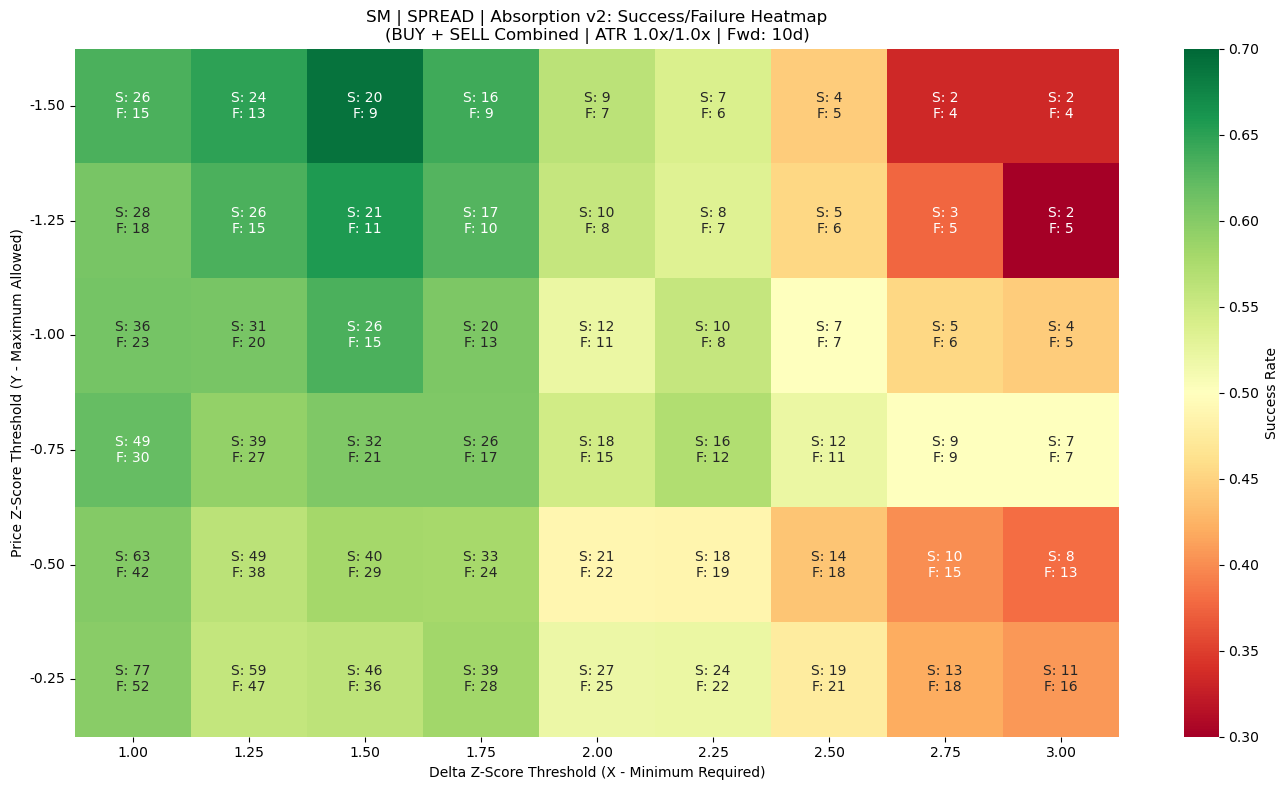


Processing Structure: JUMBO (5 instruments)


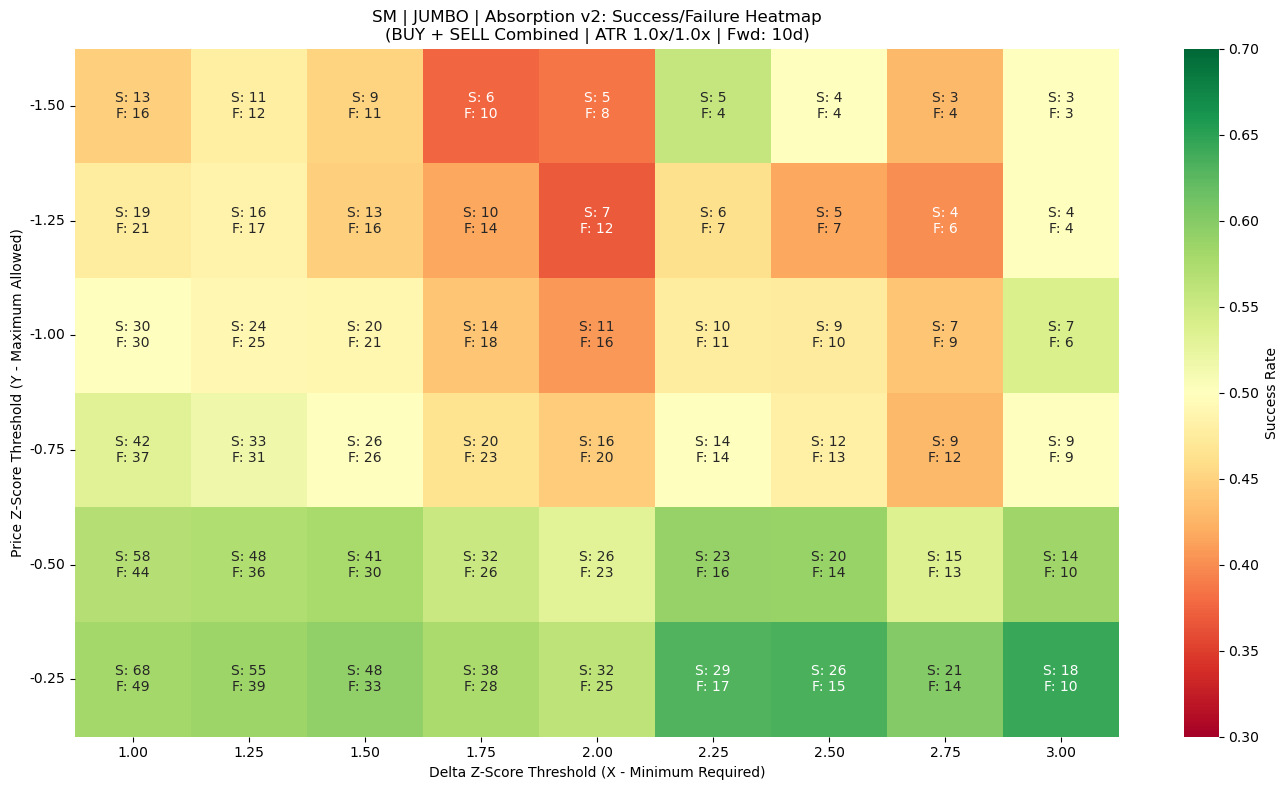

In [3]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the necessary modules from your project
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr

# ------------------------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------------------------
product_code = "SM"     # Change as needed
months_back = 8
front_n = 5

# Define the grids for the heatmap
delta_z_grid = np.arange(1.0, 3.25, 0.25)   # X-axis (e.g. 1.0 to 3.0)
price_z_grid = np.arange(-0.25, -1.75,- 0.25)  # Y-axis (e.g. 0.25 to 1.5)

# Scorer parameters (z-score rolling window sizes)
v2_params = {
    "volume_window": 5,
    "atr_window": 5,
    "baseline_window": 15,
}

# ATR labeling parameters
atr_period = 14
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10

# ------------------------------------------------------------------------------
# 2. FETCH DATA & VECTORISED LABELING PER STRUCTURE
# ------------------------------------------------------------------------------
start_date = (pd.Timestamp.now() - pd.DateOffset(months=months_back)).strftime("%Y-%m-%d")
end_date = pd.Timestamp.now().strftime("%Y-%m-%d")

# Get structures dictionary: e.g. {"spread": ["BO...", ...], "jumbo": ["BO...", ...]}
structures_dict = get_all_front_instruments(product_code, reference_date=None, front_n=front_n)

for structure_name, instruments in structures_dict.items():
    print(f"\n{'='*70}")
    print(f"Processing Structure: {structure_name.upper()} ({len(instruments)} instruments)")
    print(f"{'='*70}")
    
    all_results = []
    
    for inst in instruments:
        # 1. Fetch OHLC
        df = fetch_ohlc_1d(inst, product_code, getData_OHLC_v2, start_date, end_date)
        if df is None or len(df) < 30:
            continue
        
        # 2. Calculate z-scores (we pass dummy thresholds of 0 because we only need raw z_delta & z_price)
        df = calculate_absorption_v2(
            df, 
            volume_window=v2_params["volume_window"], 
            atr_window=v2_params["atr_window"], 
            baseline_window=v2_params["baseline_window"],
            delta_z_threshold=0, price_z_threshold=0
        )
        
        # 3. Trick the labeler: Evaluate EVERY bar as a potential BUY
        df["absorption_direction"] = "BUY"
        df_buy = label_absorption_atr(
            df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
            stop_atr_mult=stop_atr_mult, forward_days=forward_days
        )
        
        # 4. Trick the labeler: Evaluate EVERY bar as a potential SELL
        df["absorption_direction"] = "SELL"
        df_sell = label_absorption_atr(
            df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
            stop_atr_mult=stop_atr_mult, forward_days=forward_days
        )
        
        # 5. Extract only what we need for the heatmap to save memory
        res = pd.DataFrame({
            "z_delta": df["z_delta"],
            "z_price": df["z_price"],
            "buy_success": df_buy["sl_success"],
            "sell_success": df_sell["sl_success"]
        })
        
        all_results.append(res)
    
    if not all_results:
        print(f"No valid data found for {structure_name}. Skipping heatmap.")
        continue

    # ------------------------------------------------------------------------------
    # 3. COMPUTE HEATMAP MATRICES FOR THIS STRUCTURE
    # ------------------------------------------------------------------------------
    pooled_df = pd.concat(all_results, ignore_index=True)

    n_price = len(price_z_grid)
    n_delta = len(delta_z_grid)

    heat_rate = np.zeros((n_price, n_delta))
    annot_labels = np.empty((n_price, n_delta), dtype=object)

    for i, pz in enumerate(price_z_grid):
        for j, dz in enumerate(delta_z_grid):
            
            # BUY condition: delta is extreme (>= dz) AND price response is muted (<= pz)
            buy_mask = (pooled_df["z_delta"] >= dz) & (pooled_df["z_price"] <= pz)
            buy_succ = (pooled_df.loc[buy_mask, "buy_success"] == 1.0).sum()
            buy_fail = (pooled_df.loc[buy_mask, "buy_success"] == 0.0).sum()
            
            # SELL condition: delta is extreme (<= -dz) AND price response is muted (>= -pz)
            sell_mask = (pooled_df["z_delta"] <= -dz) & (pooled_df["z_price"] >= -pz)
            sell_succ = (pooled_df.loc[sell_mask, "sell_success"] == 1.0).sum()
            sell_fail = (pooled_df.loc[sell_mask, "sell_success"] == 0.0).sum()
            
            # Combined totals (BUY + SELL)
            tot_succ = buy_succ + sell_succ
            tot_fail = buy_fail + sell_fail
            tot_valid = tot_succ + tot_fail
            
            if tot_valid > 0:
                heat_rate[i, j] = tot_succ / tot_valid
                annot_labels[i, j] = f"S: {tot_succ}\nF: {tot_fail}"
            else:
                heat_rate[i, j] = np.nan
                annot_labels[i, j] = "N/A"

    # ------------------------------------------------------------------------------
    # 4. PLOT HEATMAP FOR THIS STRUCTURE
    # ------------------------------------------------------------------------------
    plt.figure(figsize=(14, 8))

    # Plot heatmap using Success Rate for the color map (RdYlGn = Red -> Yellow -> Green)
    ax = sns.heatmap(
        heat_rate, 
        annot=annot_labels, 
        fmt="",                # Disables formatting so our custom 'S: X \n F: Y' string works
        cmap="RdYlGn", 
        vmin=0.3, vmax=0.7,    # Lock color scale (30% to 70% success rate)
        cbar_kws={'label': 'Success Rate'}
    )

    # Set axes labels matching the grid values
    ax.set_xticklabels([f"{dz:.2f}" for dz in delta_z_grid])
    ax.set_yticklabels([f"{pz:.2f}" for pz in price_z_grid], rotation=0)

    # Invert Y-axis so smaller (stricter) price_z thresholds are at the bottom of the chart
    ax.invert_yaxis()

    plt.xlabel("Delta Z-Score Threshold (X - Minimum Required)")
    plt.ylabel("Price Z-Score Threshold (Y - Maximum Allowed)")
    plt.title(f"{product_code} | {structure_name.upper()} | Absorption v2: Success/Failure Heatmap\n(BUY + SELL Combined | ATR {target_atr_mult}x/{stop_atr_mult}x | Fwd: {forward_days}d)")

    plt.tight_layout()
    plt.show()


# EACH SPREAD AND JUMBO SEPARATE

Generating independent heatmaps for 10 instruments. Please wait...



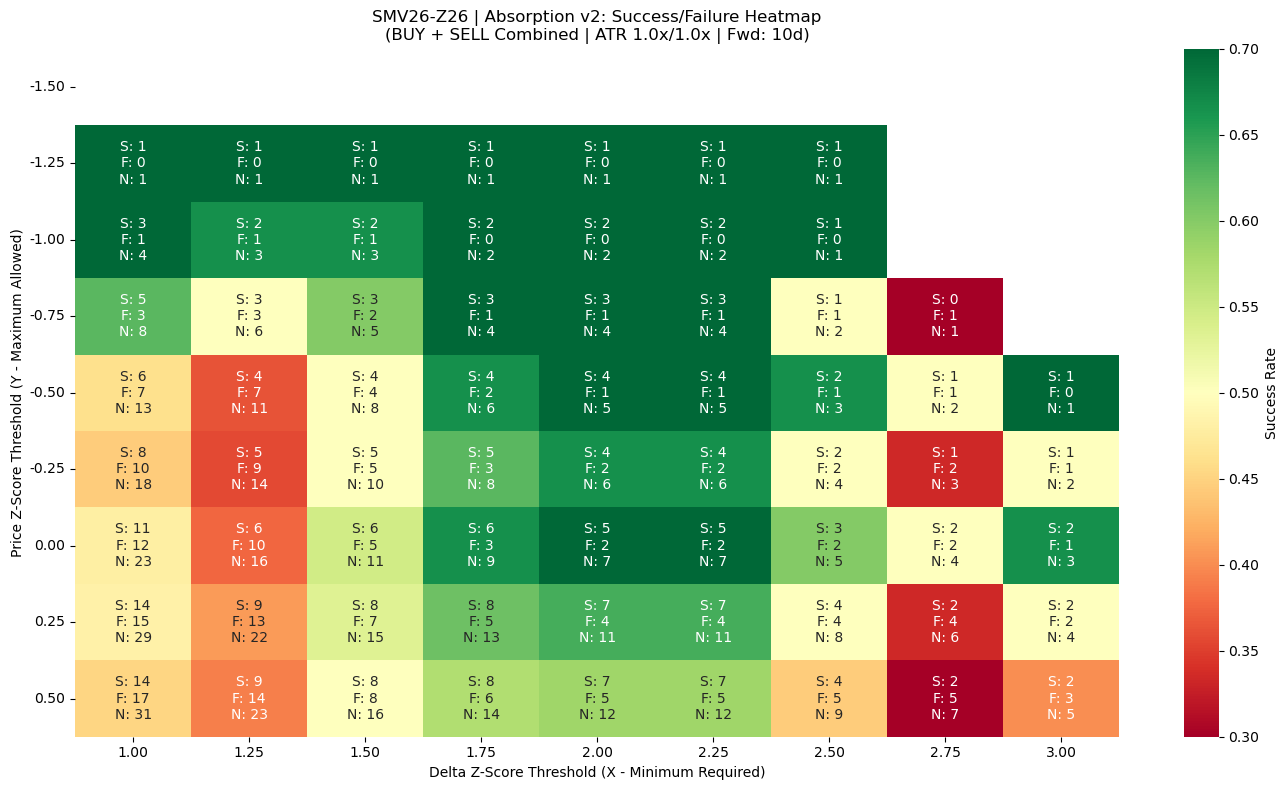

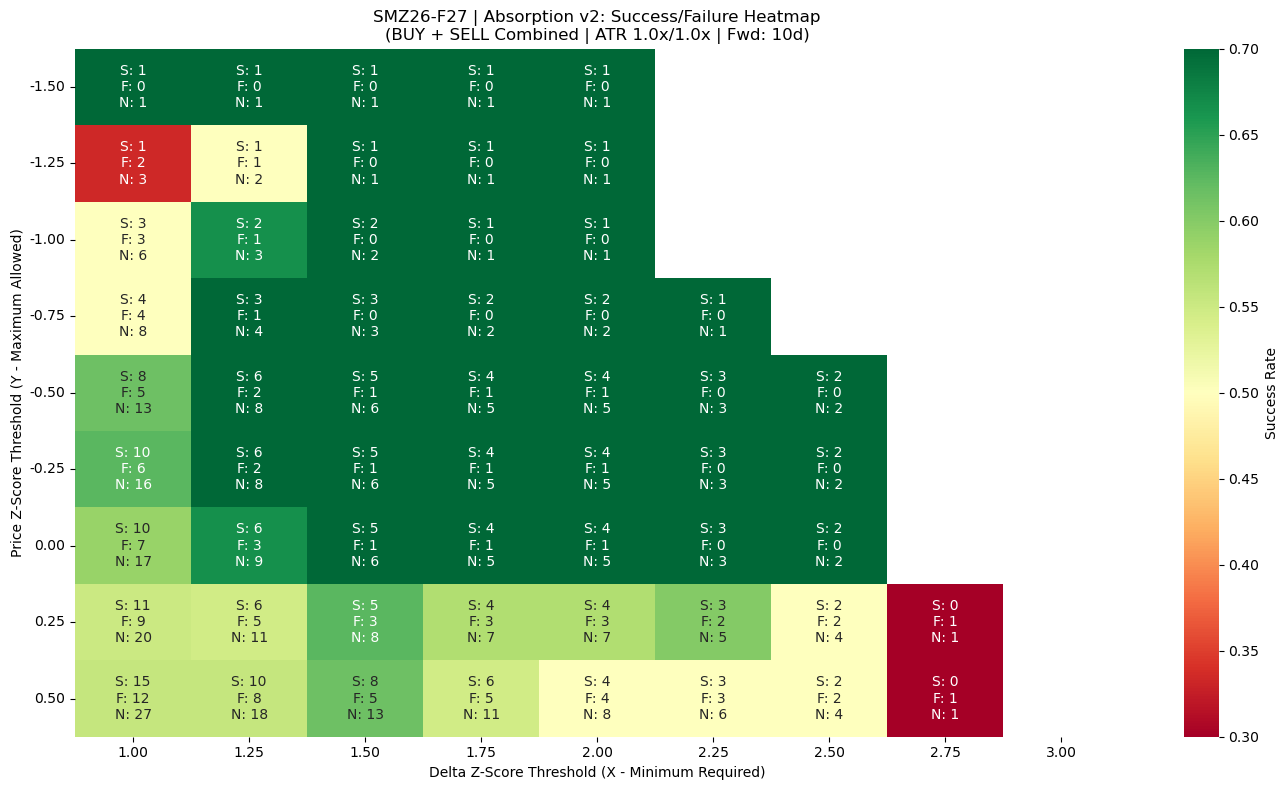

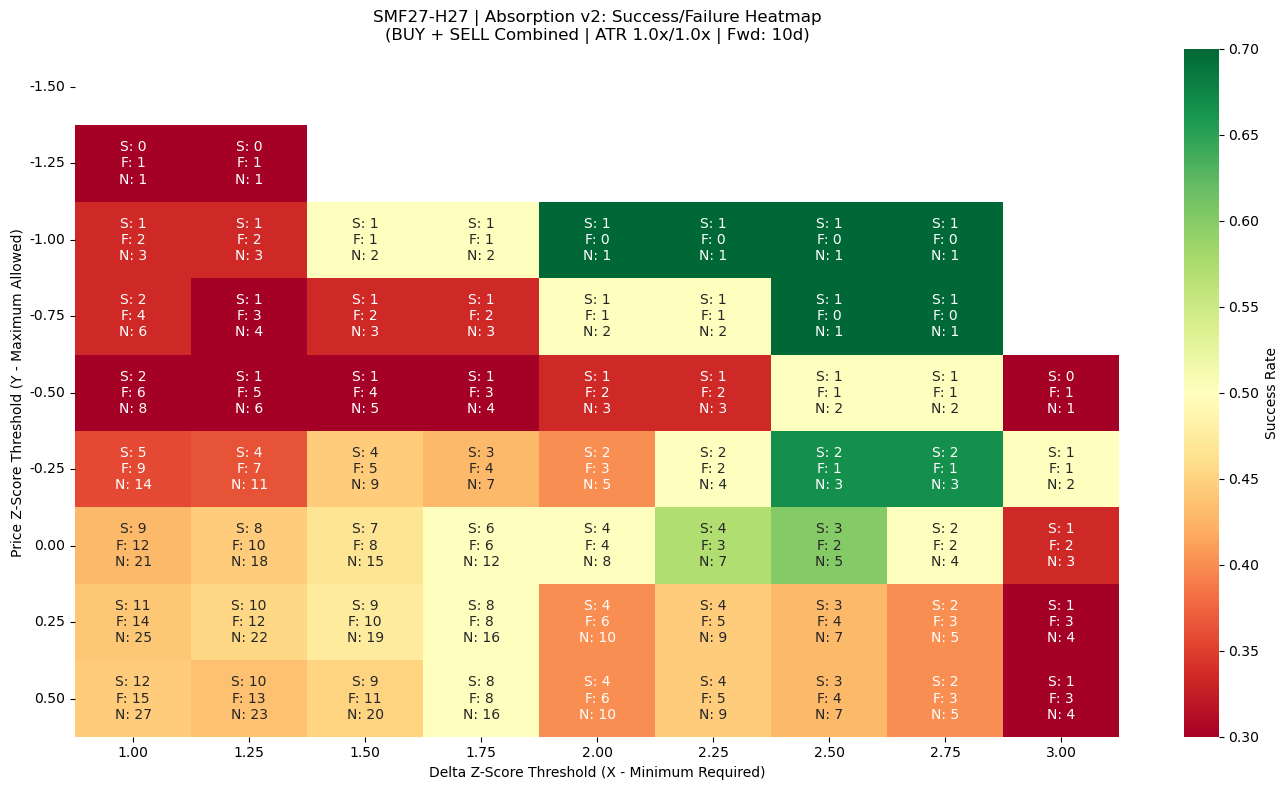

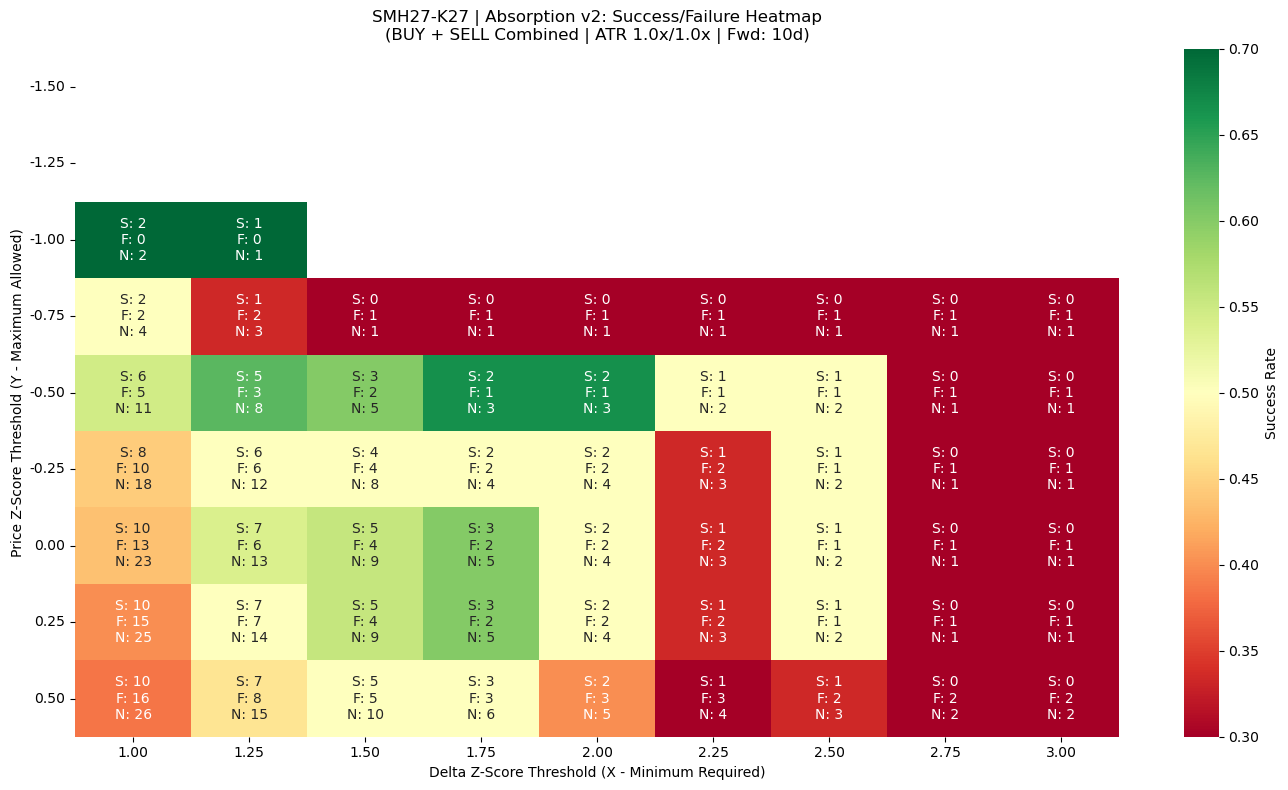

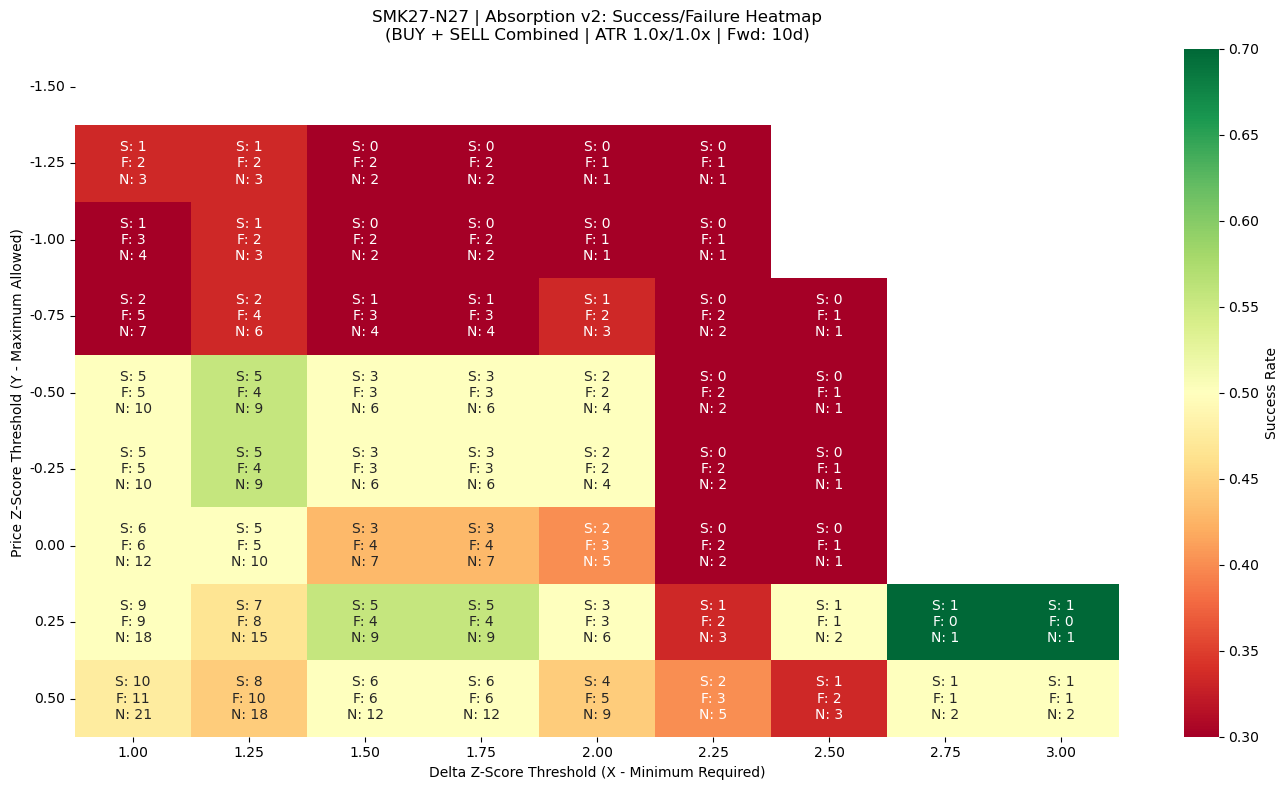

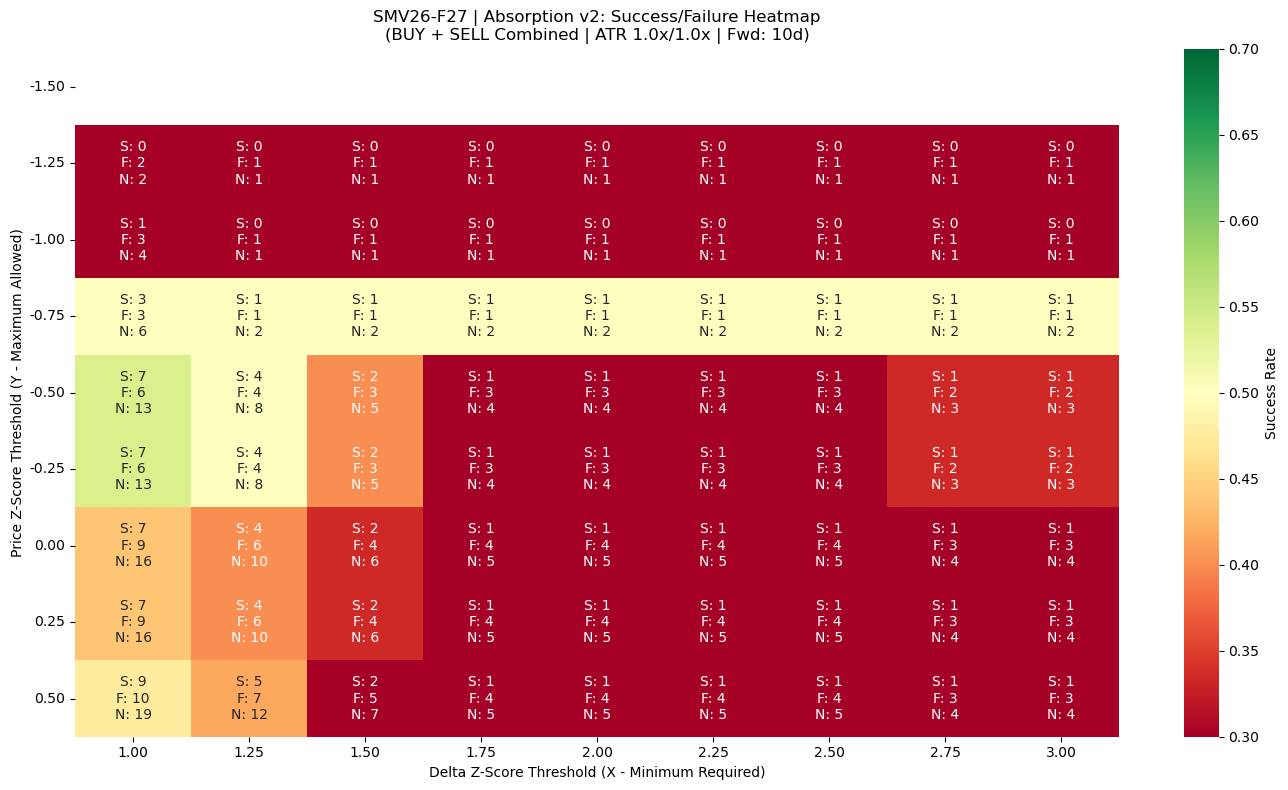

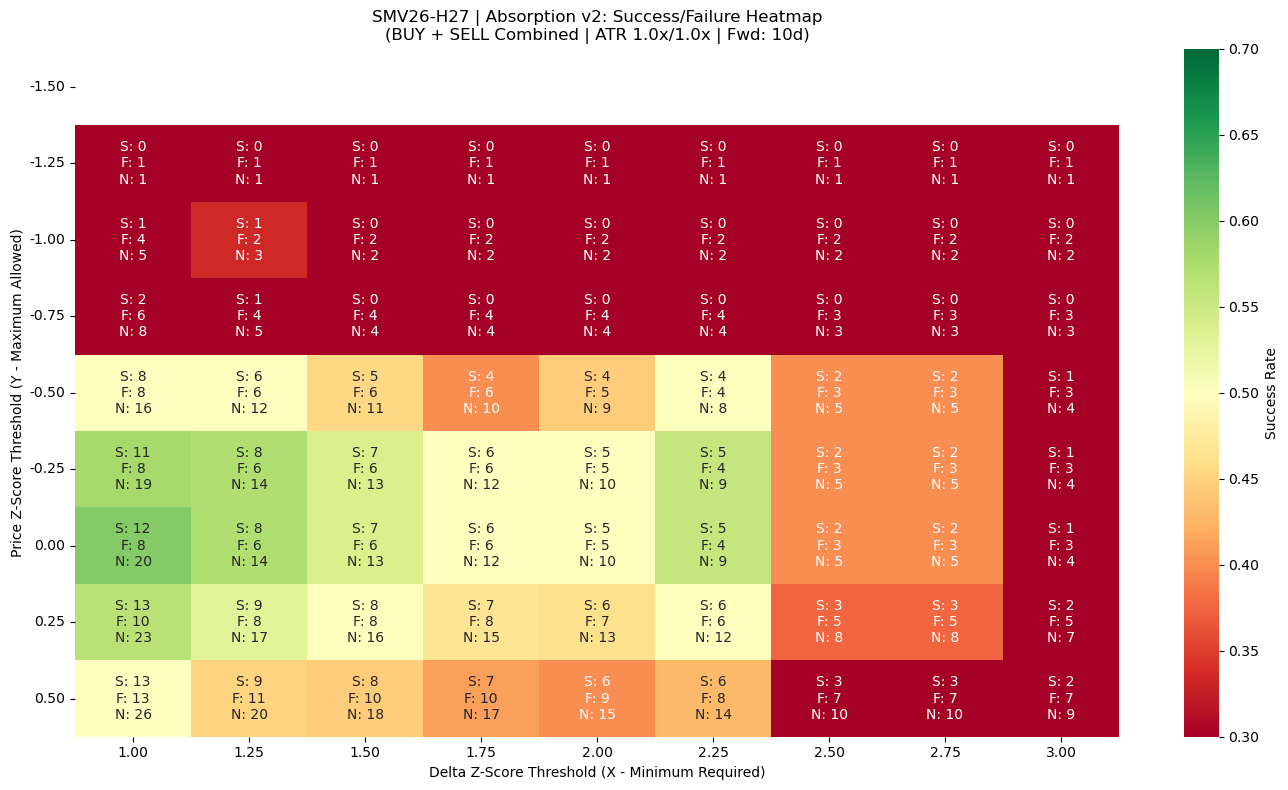

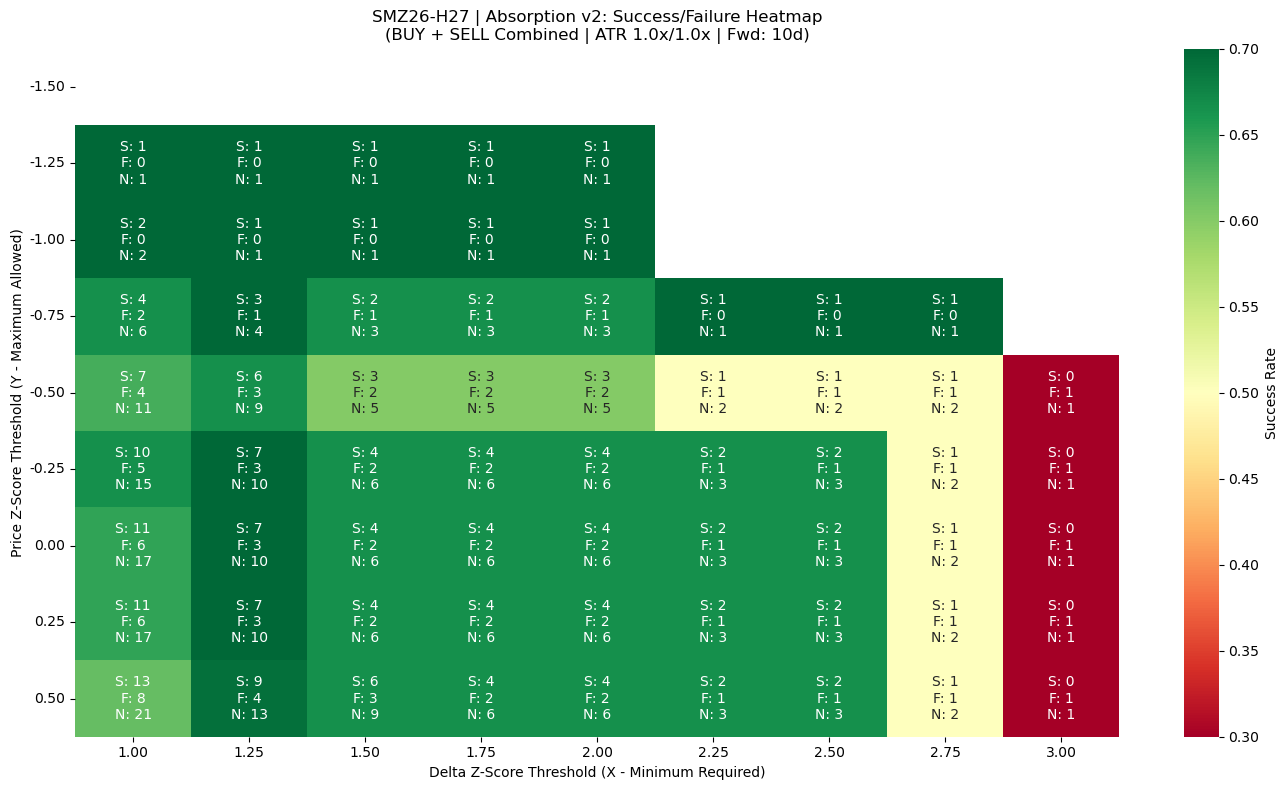

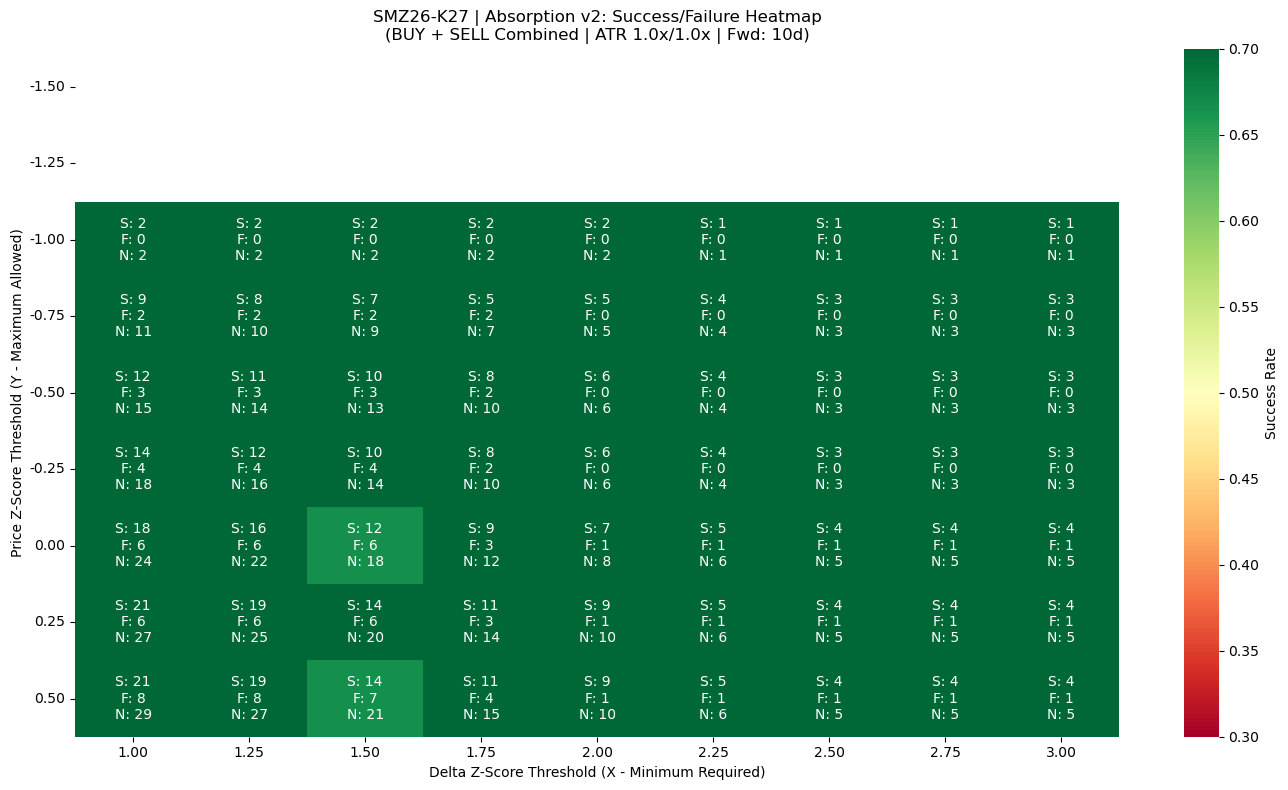

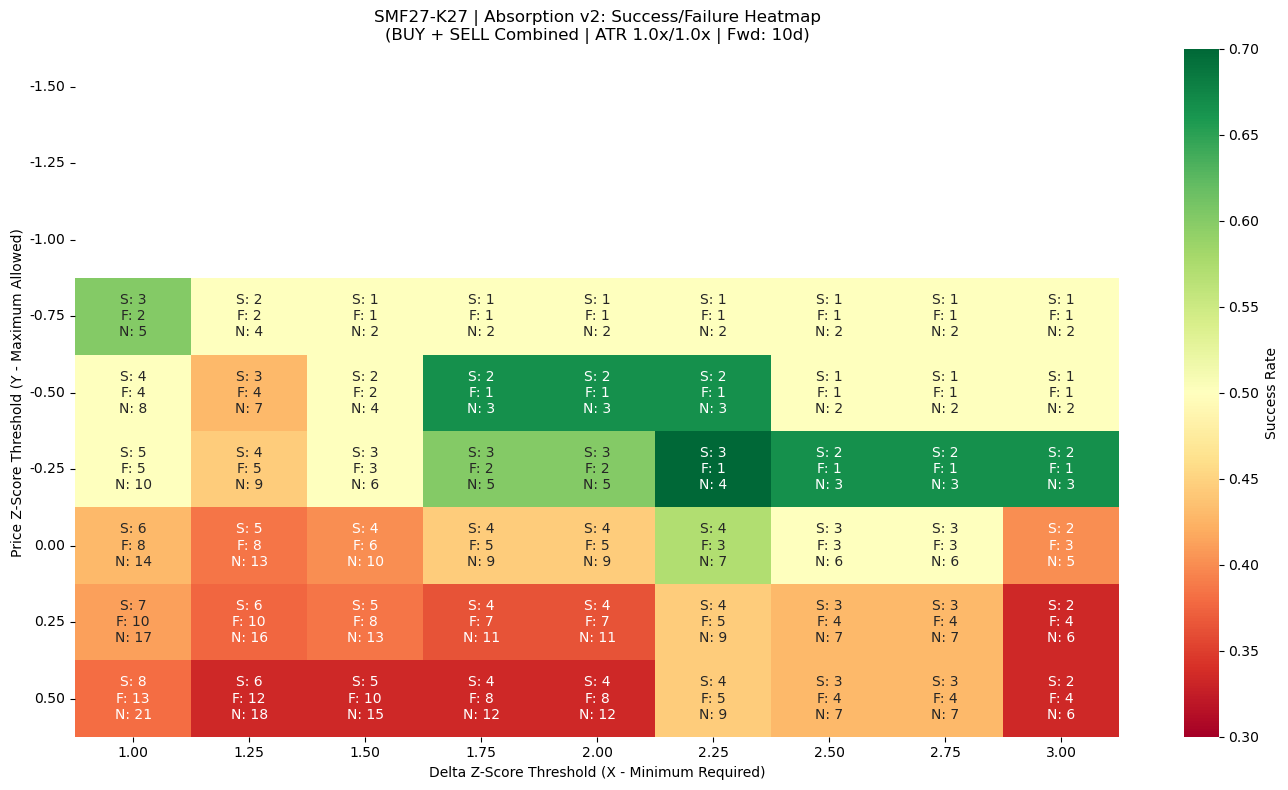

In [4]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the necessary modules from your project
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr

# ------------------------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------------------------
product_code = "SM"     # Change as needed
months_back = 8
front_n = 5

# Define the grids for the heatmap
delta_z_grid = np.arange(1.0, 3.25, 0.25)       # X-axis (e.g. 1.0 to 3.0)
price_z_grid = np.arange(0.5, -1.75, -0.25)   # Y-axis (e.g. -0.25 to -1.50)

# Scorer parameters (z-score rolling window sizes)
v2_params = {
    "volume_window": 5,
    "atr_window": 5,
    "baseline_window": 30,
}

# ATR labeling parameters
atr_period = 14
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10

# ------------------------------------------------------------------------------
# 2. FETCH, PROCESS & PLOT HEATMAP FOR EACH INDIVIDUAL INSTRUMENT
# ------------------------------------------------------------------------------
start_date = (pd.Timestamp.now() - pd.DateOffset(months=months_back)).strftime("%Y-%m-%d")
end_date = pd.Timestamp.now().strftime("%Y-%m-%d")

# Gather all instruments from all structures
instruments = []
for insts in get_all_front_instruments(product_code, reference_date=None, front_n=front_n).values():
    instruments.extend(insts)

print(f"Generating independent heatmaps for {len(instruments)} instruments. Please wait...\n")

for inst in instruments:
    # 1. Fetch OHLC
    df = fetch_ohlc_1d(inst, product_code, getData_OHLC_v2, start_date, end_date)
    if df is None or len(df) < 30:
        print(f"Skipping {inst} (insufficient data)")
        continue
    
    # 2. Calculate z-scores (we pass dummy thresholds of 0 because we only need raw z_delta & z_price)
    df = calculate_absorption_v2(
        df, 
        volume_window=v2_params["volume_window"], 
        atr_window=v2_params["atr_window"], 
        baseline_window=v2_params["baseline_window"],
        delta_z_threshold=0, price_z_threshold=0
    )
    
    # 3. Trick the labeler: Evaluate EVERY bar as a potential BUY
    df["absorption_direction"] = "BUY"
    df_buy = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )
    
    # 4. Trick the labeler: Evaluate EVERY bar as a potential SELL
    df["absorption_direction"] = "SELL"
    df_sell = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )

    # ------------------------------------------------------------------------------
    # 3. COMPUTE HEATMAP MATRICES FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    n_price = len(price_z_grid)
    n_delta = len(delta_z_grid)

    heat_rate = np.zeros((n_price, n_delta))
    annot_labels = np.empty((n_price, n_delta), dtype=object)

    for i, pz in enumerate(price_z_grid):
        for j, dz in enumerate(delta_z_grid):

            # ==============================================================
            # DELTA THRESHOLD = MAGNITUDE
            #
            # dz = 1.0 means:
            #       positive extreme: z_delta >= +1.0
            #       negative extreme: z_delta <= -1.0
            #
            # We evaluate BOTH tails.
            # ==============================================================

            # BUY absorption:
            #   Large positive delta + muted absolute price response
            buy_mask = (
                (df["z_delta"] >= dz) &
                (df["z_price"] <= pz)
            )

            # SELL absorption:
            #   Large negative delta + muted absolute price response
            sell_mask = (
                (df["z_delta"] <= -dz) &
                (df["z_price"] <= pz)
            )

            # --------------------------------------------------------------
            # BUY outcomes
            # --------------------------------------------------------------
            buy_succ = (
                df_buy.loc[buy_mask, "sl_success"] == 1.0
            ).sum()

            buy_fail = (
                df_buy.loc[buy_mask, "sl_success"] == 0.0
            ).sum()

            # --------------------------------------------------------------
            # SELL outcomes
            # --------------------------------------------------------------
            sell_succ = (
                df_sell.loc[sell_mask, "sl_success"] == 1.0
            ).sum()

            sell_fail = (
                df_sell.loc[sell_mask, "sl_success"] == 0.0
            ).sum()

            # --------------------------------------------------------------
            # COMBINE BOTH EXTREME SIDES
            # --------------------------------------------------------------
            tot_succ = buy_succ + sell_succ
            tot_fail = buy_fail + sell_fail
            tot_valid = tot_succ + tot_fail

            if tot_valid > 0:
                heat_rate[i, j] = tot_succ / tot_valid

                annot_labels[i, j] = (
                    f"S: {tot_succ}\n"
                    f"F: {tot_fail}\n"
                    f"N: {tot_valid}"
                )
            else:
                heat_rate[i, j] = np.nan
                annot_labels[i, j] = "N/A"
    # ------------------------------------------------------------------------------
    # 4. PLOT HEATMAP FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    plt.figure(figsize=(14, 8))

    ax = sns.heatmap(
        heat_rate, 
        annot=annot_labels, 
        fmt="",                # Disables formatting so our custom string works
        cmap="RdYlGn", 
        vmin=0.3, vmax=0.7,    # Lock color scale (30% to 70% success rate)
        cbar_kws={'label': 'Success Rate'}
    )

    ax.set_xticklabels([f"{dz:.2f}" for dz in delta_z_grid])
    ax.set_yticklabels([f"{pz:.2f}" for pz in price_z_grid], rotation=0)

    # Invert Y-axis so smaller values (e.g. -1.5) are at the bottom of the chart
    ax.invert_yaxis()

    plt.xlabel("Delta Z-Score Threshold (X - Minimum Required)")
    plt.ylabel("Price Z-Score Threshold (Y - Maximum Allowed)")
    plt.title(f"{inst} | Absorption v2: Success/Failure Heatmap\n(BUY + SELL Combined | ATR {target_atr_mult}x/{stop_atr_mult}x | Fwd: {forward_days}d)")

    plt.tight_layout()
    plt.show()


Generating independent heatmaps for 10 instruments. Please wait...



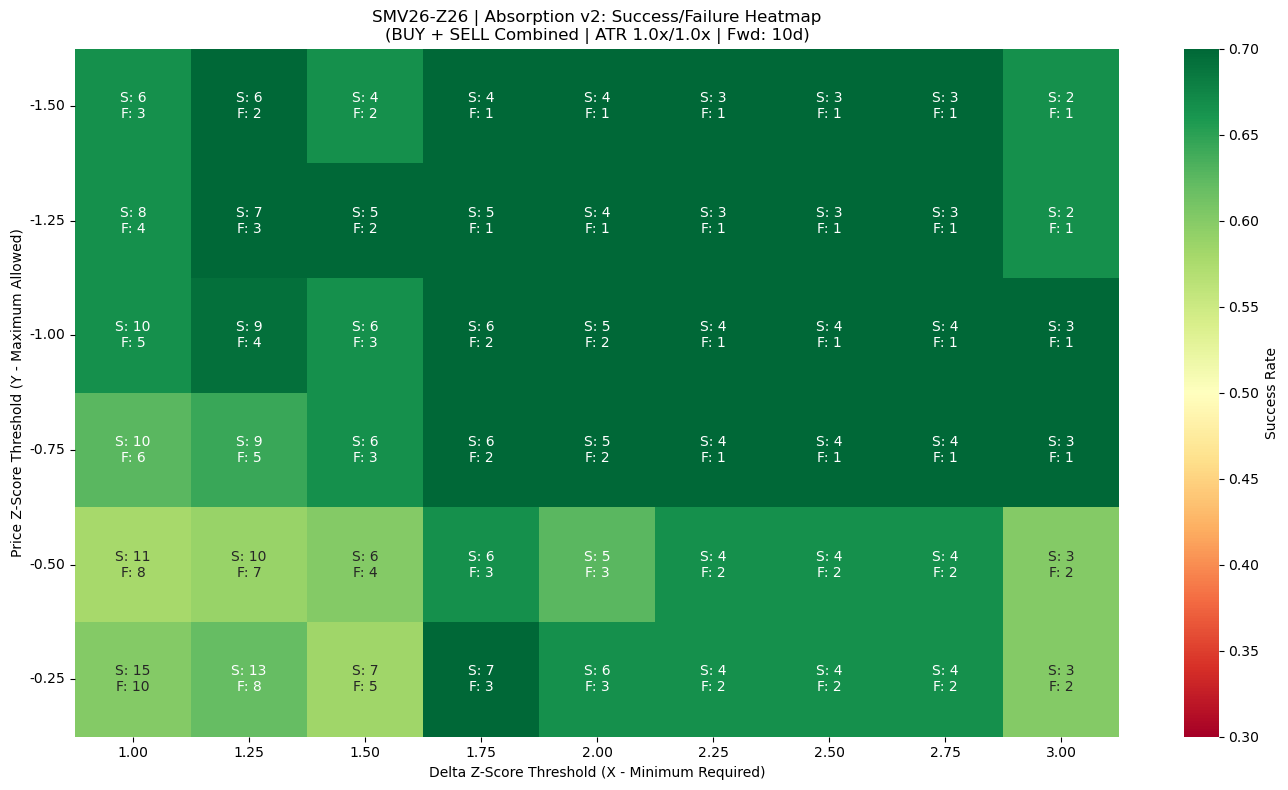

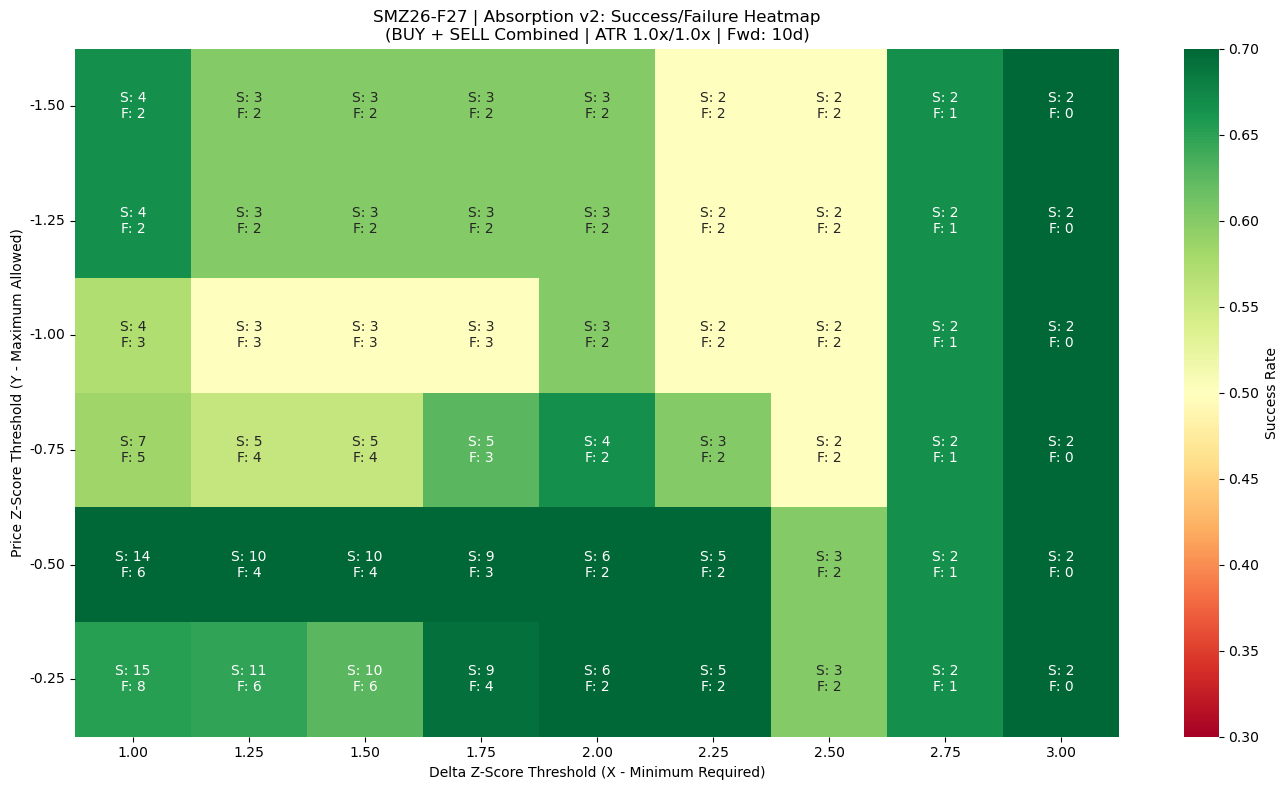

c:\Users\shresth.shankhdhar\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


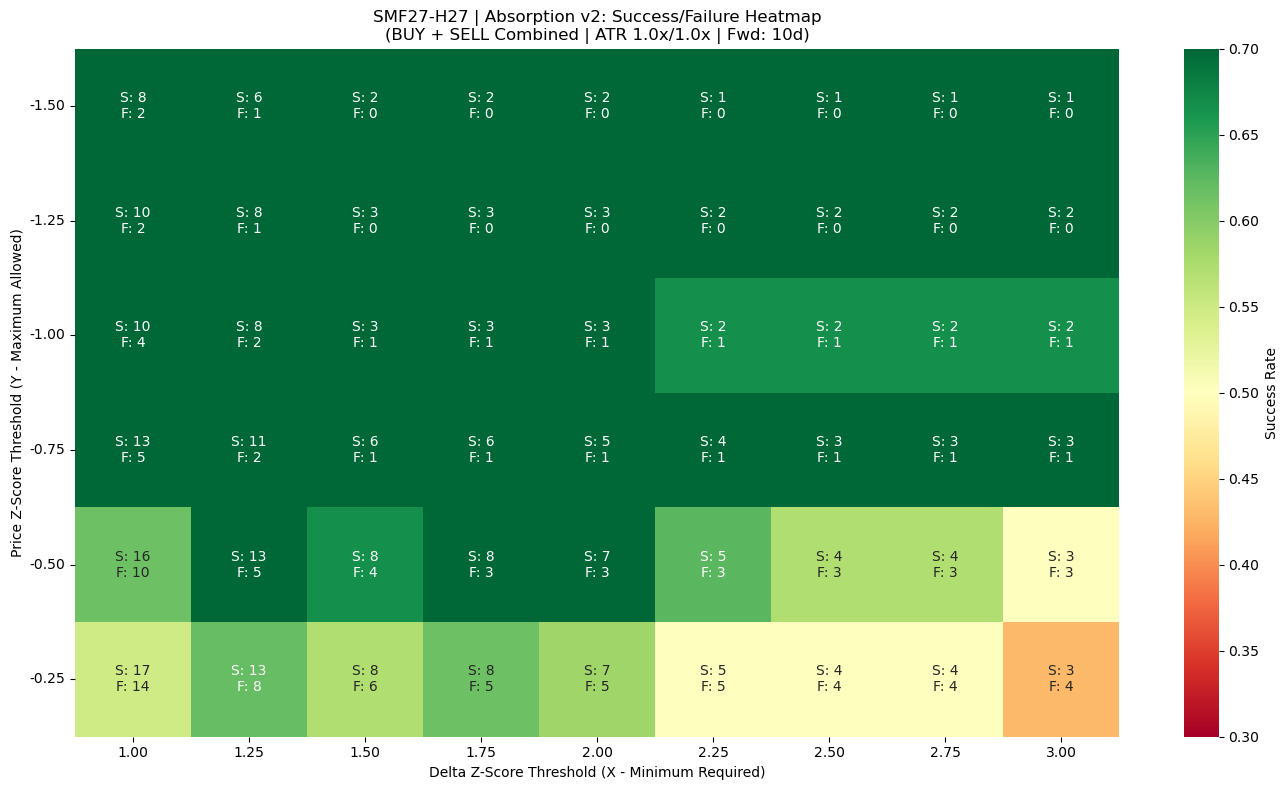

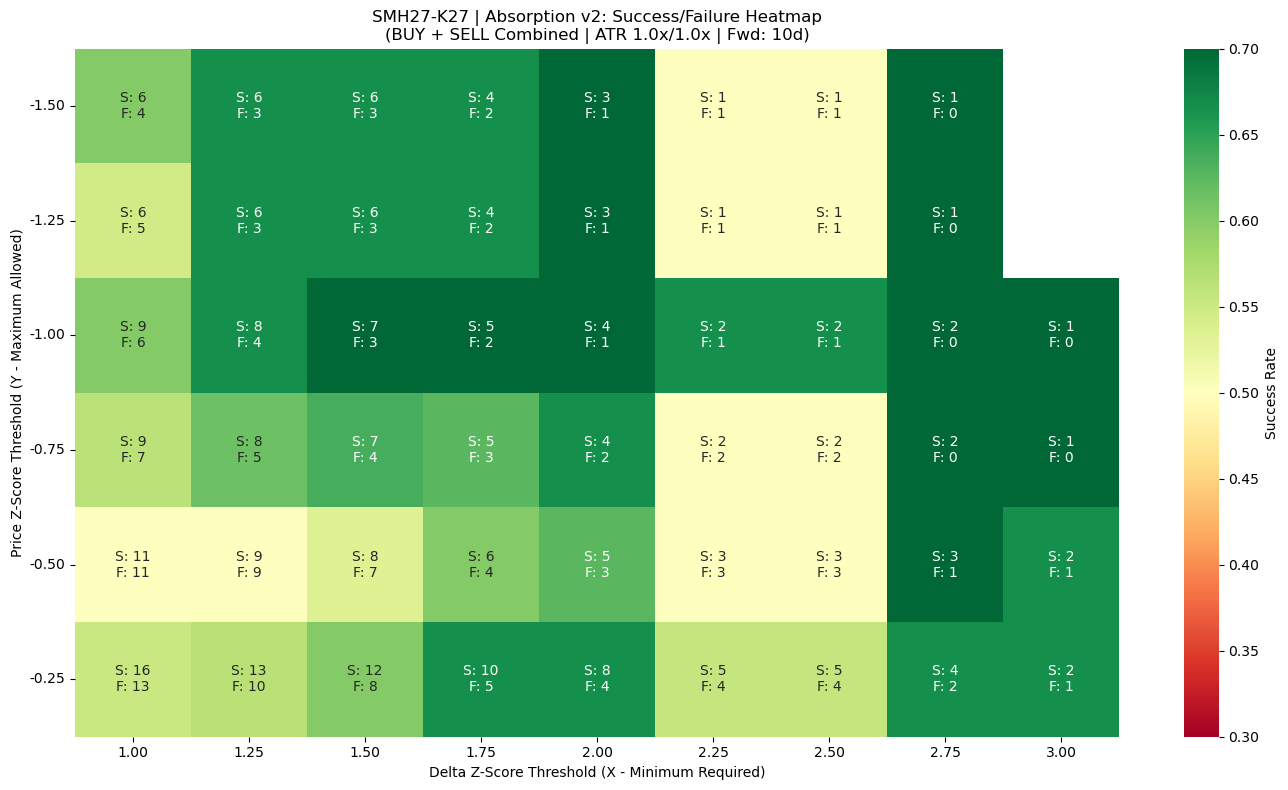

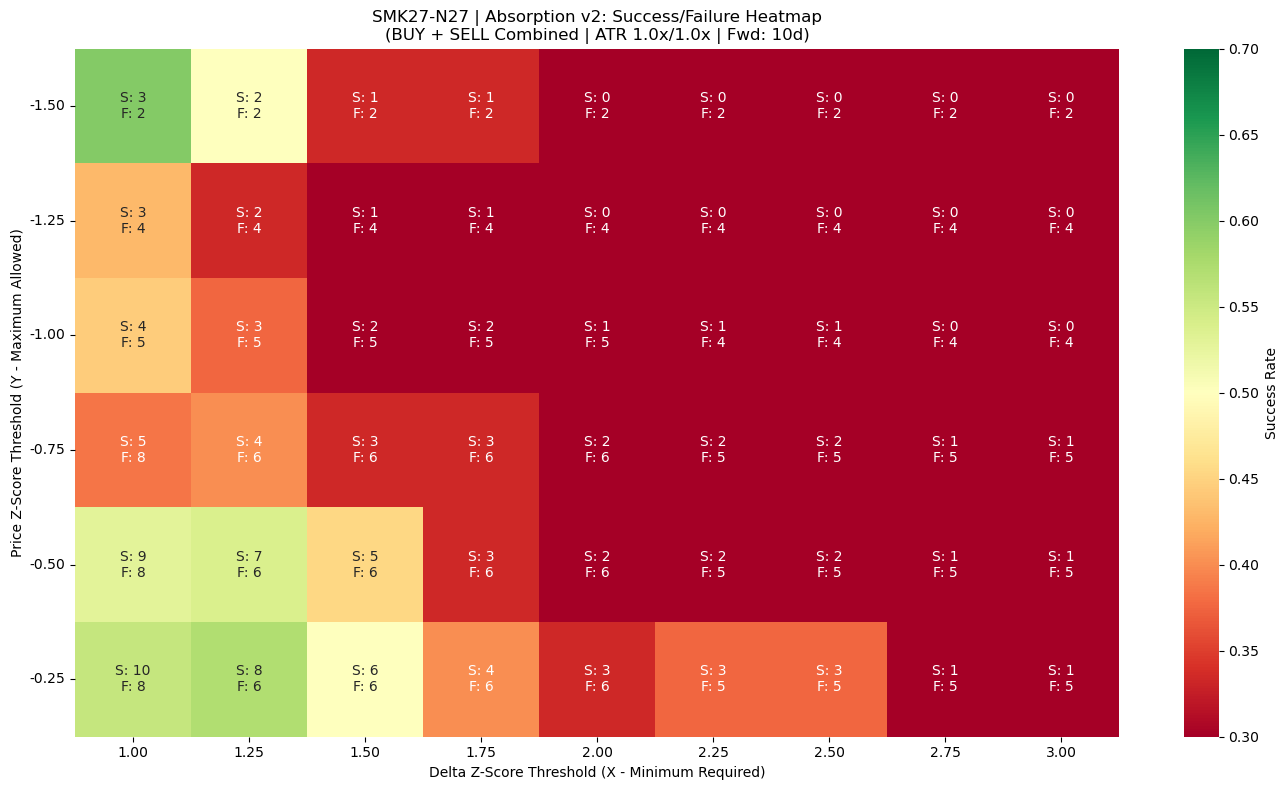

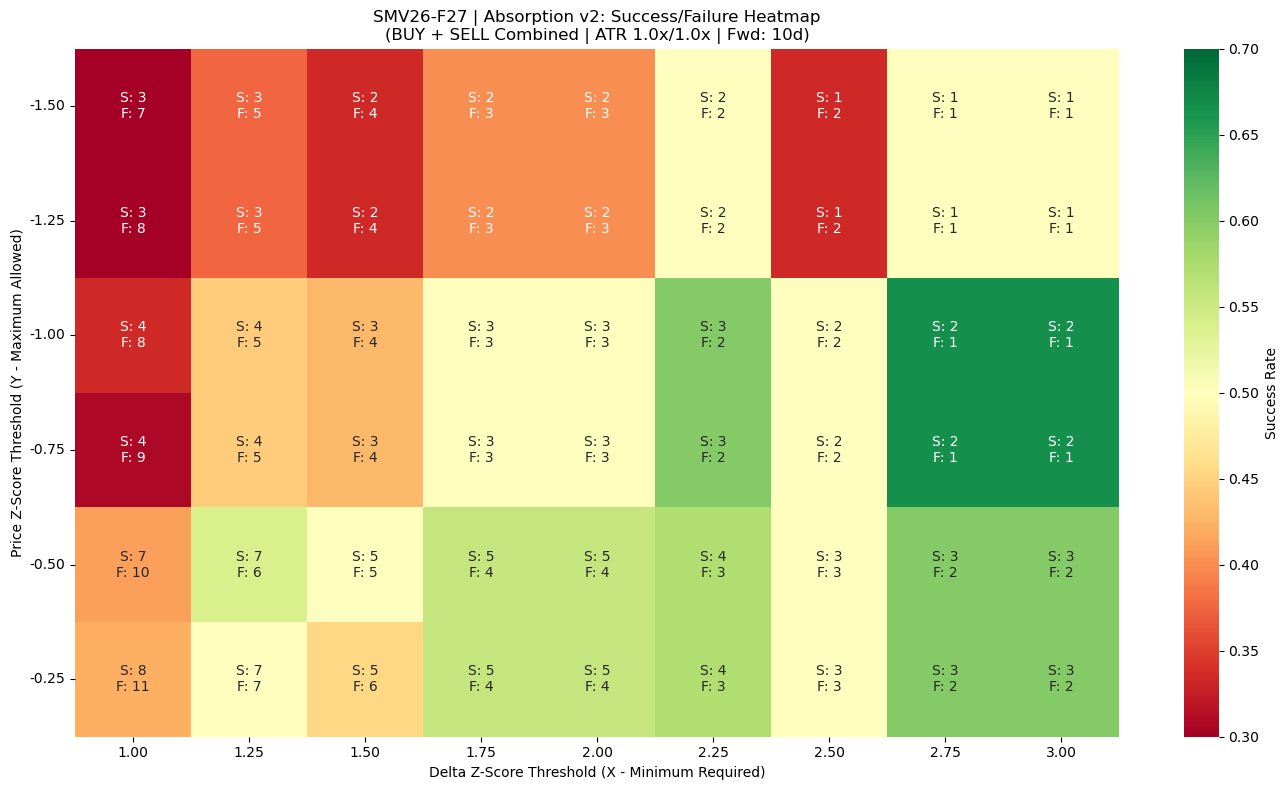

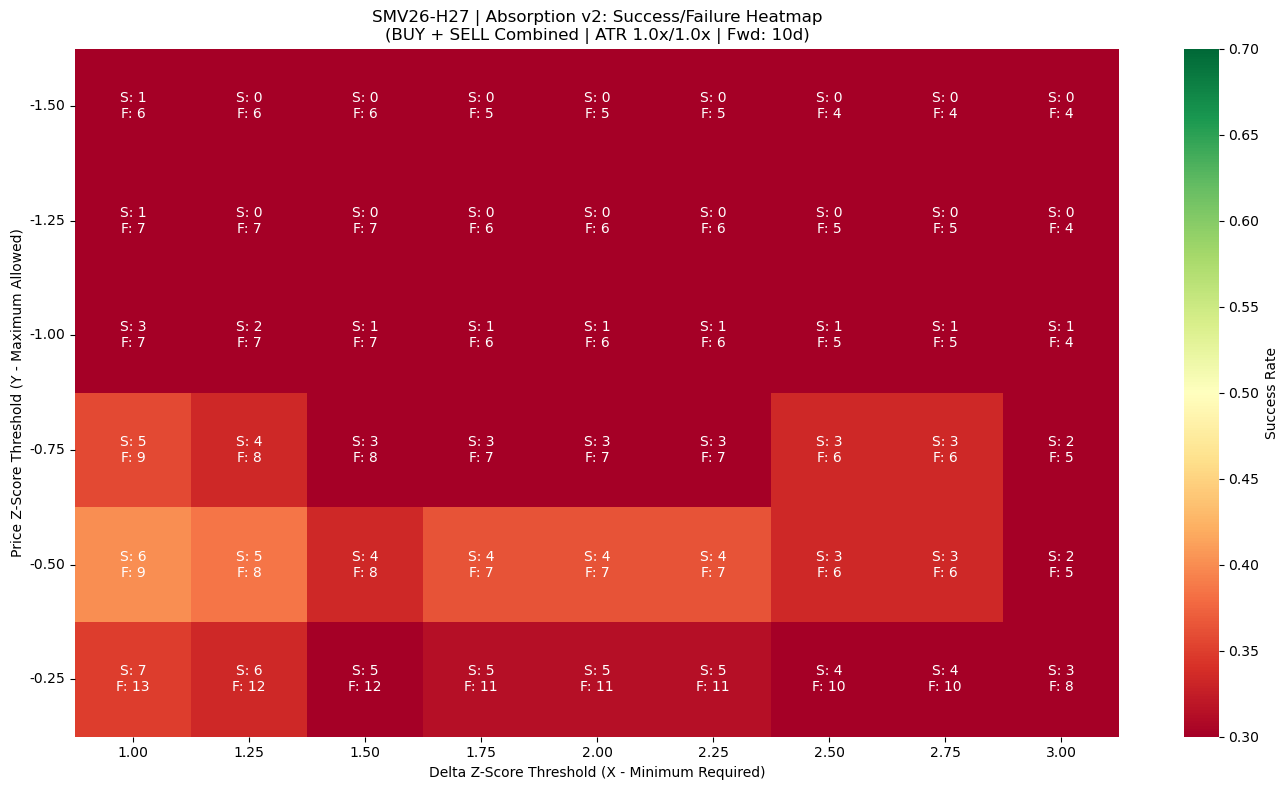

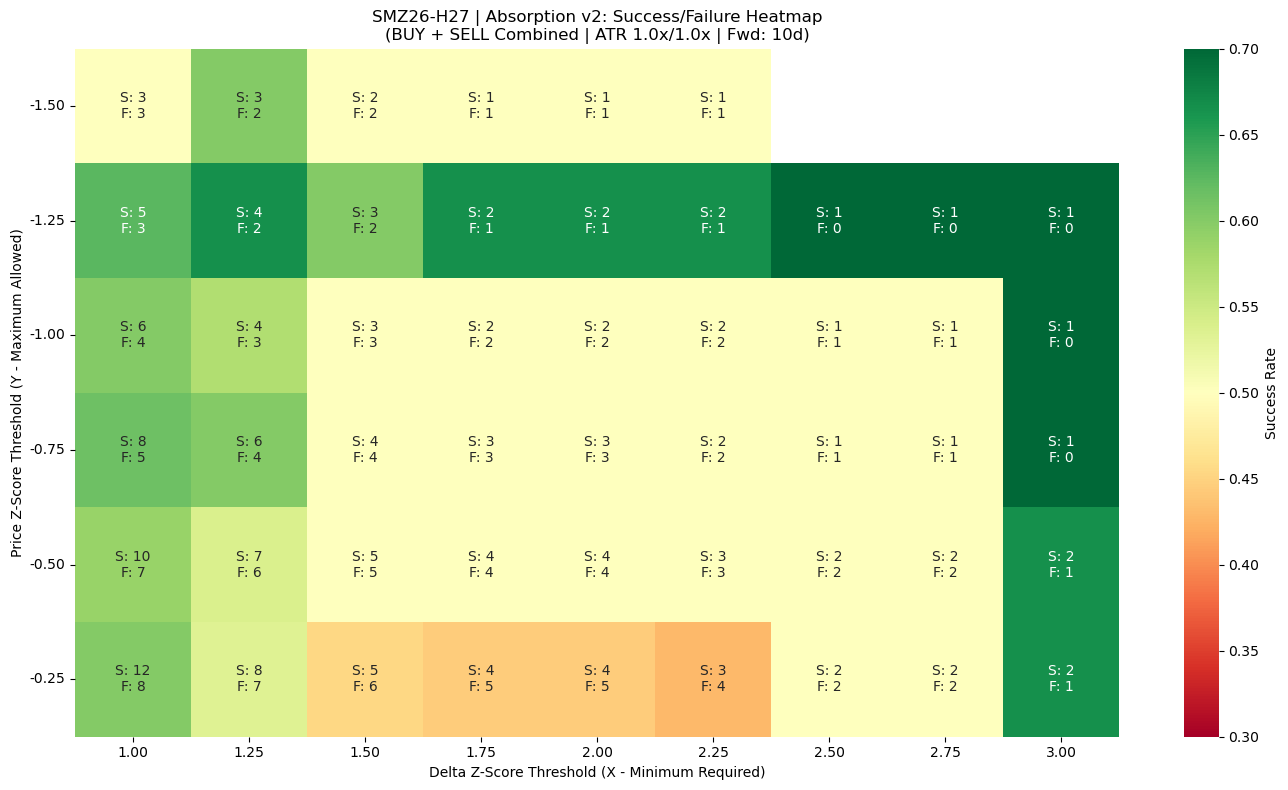

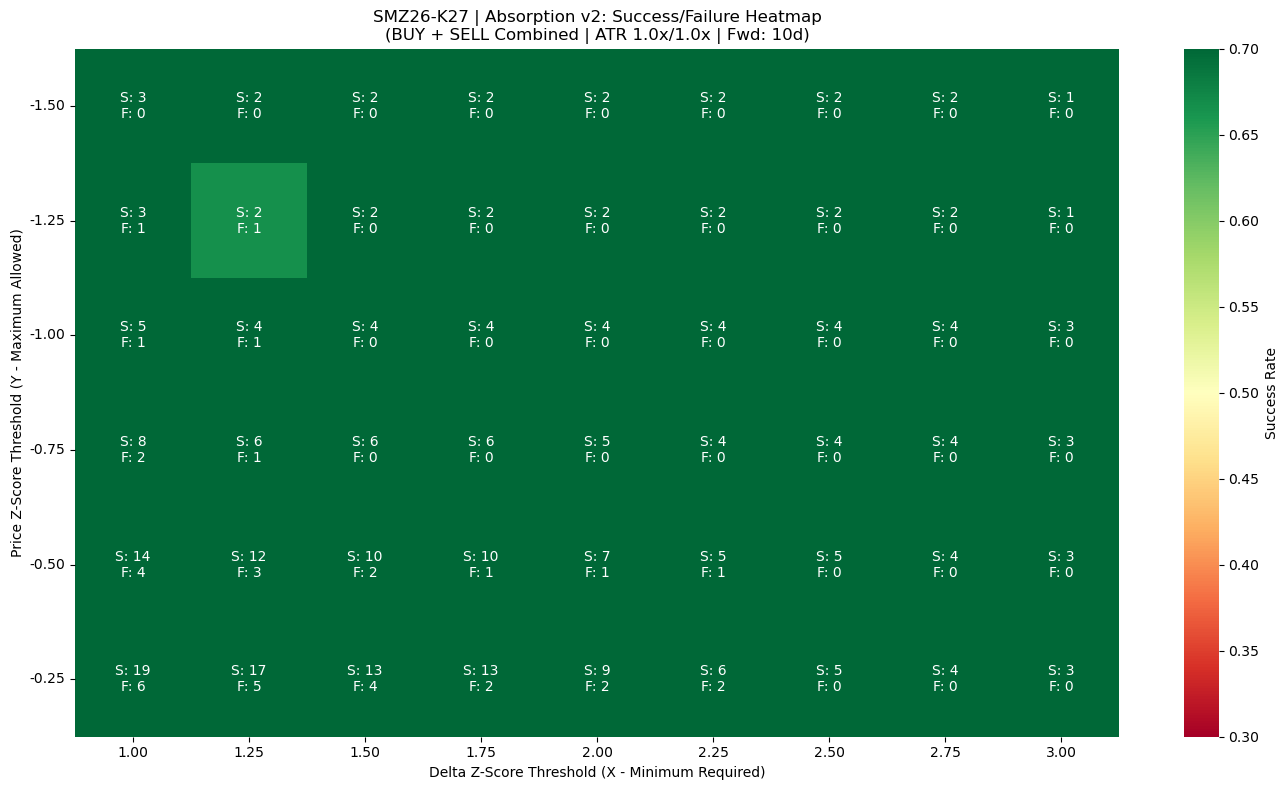

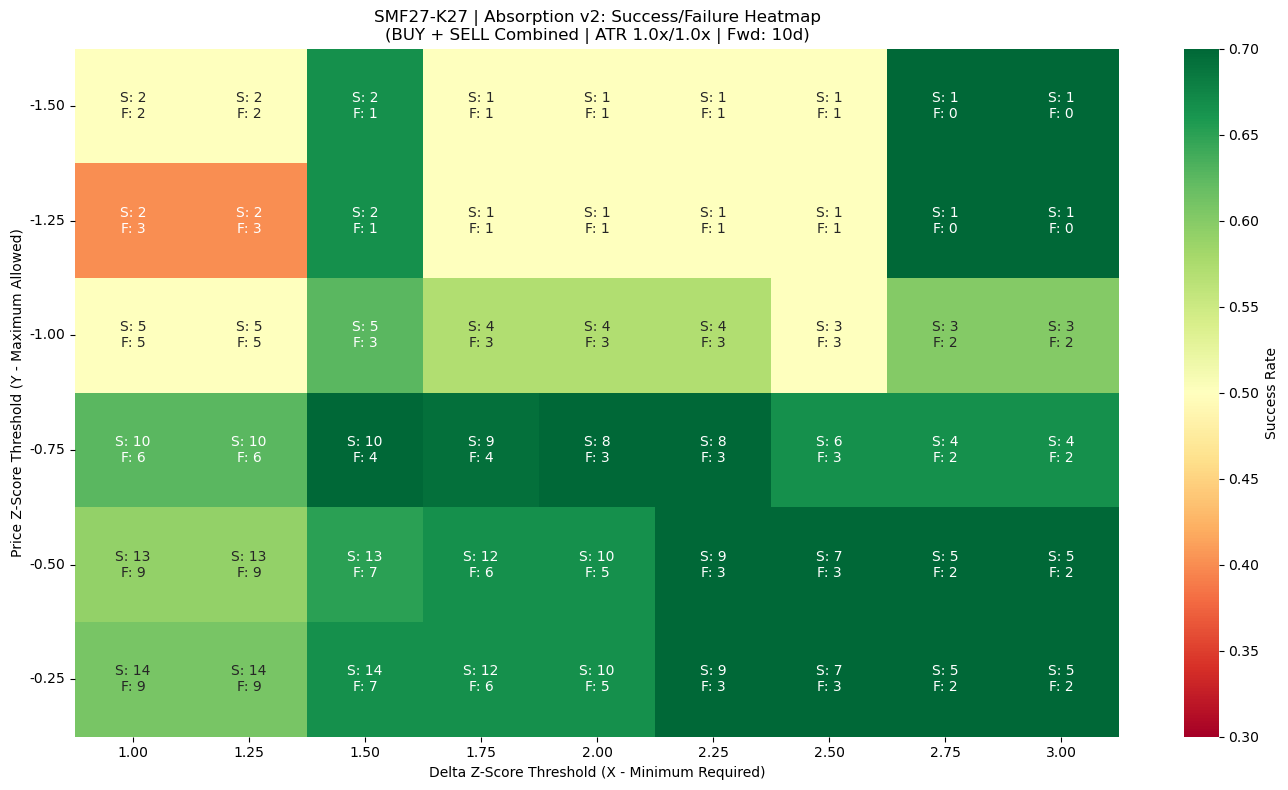

In [5]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the necessary modules from your project
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr

# ------------------------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------------------------
product_code = "SM"     # Change as needed
months_back = 8
front_n = 5

# Define the grids for the heatmap
delta_z_grid = np.arange(1.0, 3.25, 0.25)       # X-axis (e.g. 1.0 to 3.0)
price_z_grid = np.arange(-0.25, -1.75, -0.25)   # Y-axis (e.g. -0.25 to -1.50)

# Scorer parameters (z-score rolling window sizes)
v2_params = {
    "volume_window": 22,
    "atr_window": 10,
    "baseline_window": 15,
}

# ATR labeling parameters
atr_period = 14
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10

# ------------------------------------------------------------------------------
# 2. FETCH, PROCESS & PLOT HEATMAP FOR EACH INDIVIDUAL INSTRUMENT
# ------------------------------------------------------------------------------
start_date = (pd.Timestamp.now() - pd.DateOffset(months=months_back)).strftime("%Y-%m-%d")
end_date = pd.Timestamp.now().strftime("%Y-%m-%d")

# Gather all instruments from all structures
instruments = []
for insts in get_all_front_instruments(product_code, reference_date=None, front_n=front_n).values():
    instruments.extend(insts)

print(f"Generating independent heatmaps for {len(instruments)} instruments. Please wait...\n")

for inst in instruments:
    # 1. Fetch OHLC
    df = fetch_ohlc_1d(inst, product_code, getData_OHLC_v2, start_date, end_date)
    if df is None or len(df) < 30:
        print(f"Skipping {inst} (insufficient data)")
        continue
    
    # 2. Calculate z-scores (we pass dummy thresholds of 0 because we only need raw z_delta & z_price)
    df = calculate_absorption_v2(
        df, 
        volume_window=v2_params["volume_window"], 
        atr_window=v2_params["atr_window"], 
        baseline_window=v2_params["baseline_window"],
        delta_z_threshold=0, price_z_threshold=0
    )
    
    # 3. Trick the labeler: Evaluate EVERY bar as a potential BUY
    df["absorption_direction"] = "BUY"
    df_buy = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )
    
    # 4. Trick the labeler: Evaluate EVERY bar as a potential SELL
    df["absorption_direction"] = "SELL"
    df_sell = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )

    # ------------------------------------------------------------------------------
    # 3. COMPUTE HEATMAP MATRICES FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    n_price = len(price_z_grid)
    n_delta = len(delta_z_grid)

    heat_rate = np.zeros((n_price, n_delta))
    annot_labels = np.empty((n_price, n_delta), dtype=object)

    for i, pz in enumerate(price_z_grid):
        for j, dz in enumerate(delta_z_grid):
            
            # BUY condition: delta is extreme (>= dz) AND price response is muted (<= pz)
            buy_mask = (df["z_delta"] >= dz) & (df["z_price"] <= pz)
            buy_succ = (df_buy.loc[buy_mask, "sl_success"] == 1.0).sum()
            buy_fail = (df_buy.loc[buy_mask, "sl_success"] == 0.0).sum()
            
            # SELL condition: delta is extreme (<= -dz) AND price response is muted (>= -pz)
            sell_mask = (df["z_delta"] <= -dz) & (df["z_price"] >= -pz)
            sell_succ = (df_sell.loc[sell_mask, "sl_success"] == 1.0).sum()
            sell_fail = (df_sell.loc[sell_mask, "sl_success"] == 0.0).sum()
            
            # Combined totals (BUY + SELL)
            tot_succ = buy_succ + sell_succ
            tot_fail = buy_fail + sell_fail
            tot_valid = tot_succ + tot_fail
            
            if tot_valid > 0:
                heat_rate[i, j] = tot_succ / tot_valid
                annot_labels[i, j] = f"S: {tot_succ}\nF: {tot_fail}"
            else:
                heat_rate[i, j] = np.nan
                annot_labels[i, j] = "N/A"

    # ------------------------------------------------------------------------------
    # 4. PLOT HEATMAP FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    plt.figure(figsize=(14, 8))

    ax = sns.heatmap(
        heat_rate, 
        annot=annot_labels, 
        fmt="",                # Disables formatting so our custom string works
        cmap="RdYlGn", 
        vmin=0.3, vmax=0.7,    # Lock color scale (30% to 70% success rate)
        cbar_kws={'label': 'Success Rate'}
    )

    ax.set_xticklabels([f"{dz:.2f}" for dz in delta_z_grid])
    ax.set_yticklabels([f"{pz:.2f}" for pz in price_z_grid], rotation=0)

    # Invert Y-axis so smaller values (e.g. -1.5) are at the bottom of the chart
    ax.invert_yaxis()

    plt.xlabel("Delta Z-Score Threshold (X - Minimum Required)")
    plt.ylabel("Price Z-Score Threshold (Y - Maximum Allowed)")
    plt.title(f"{inst} | Absorption v2: Success/Failure Heatmap\n(BUY + SELL Combined | ATR {target_atr_mult}x/{stop_atr_mult}x | Fwd: {forward_days}d)")

    plt.tight_layout()
    plt.show()


# WITH ABS SCORE TOO

Generating independent heatmaps & distributions for 10 instruments. Please wait...



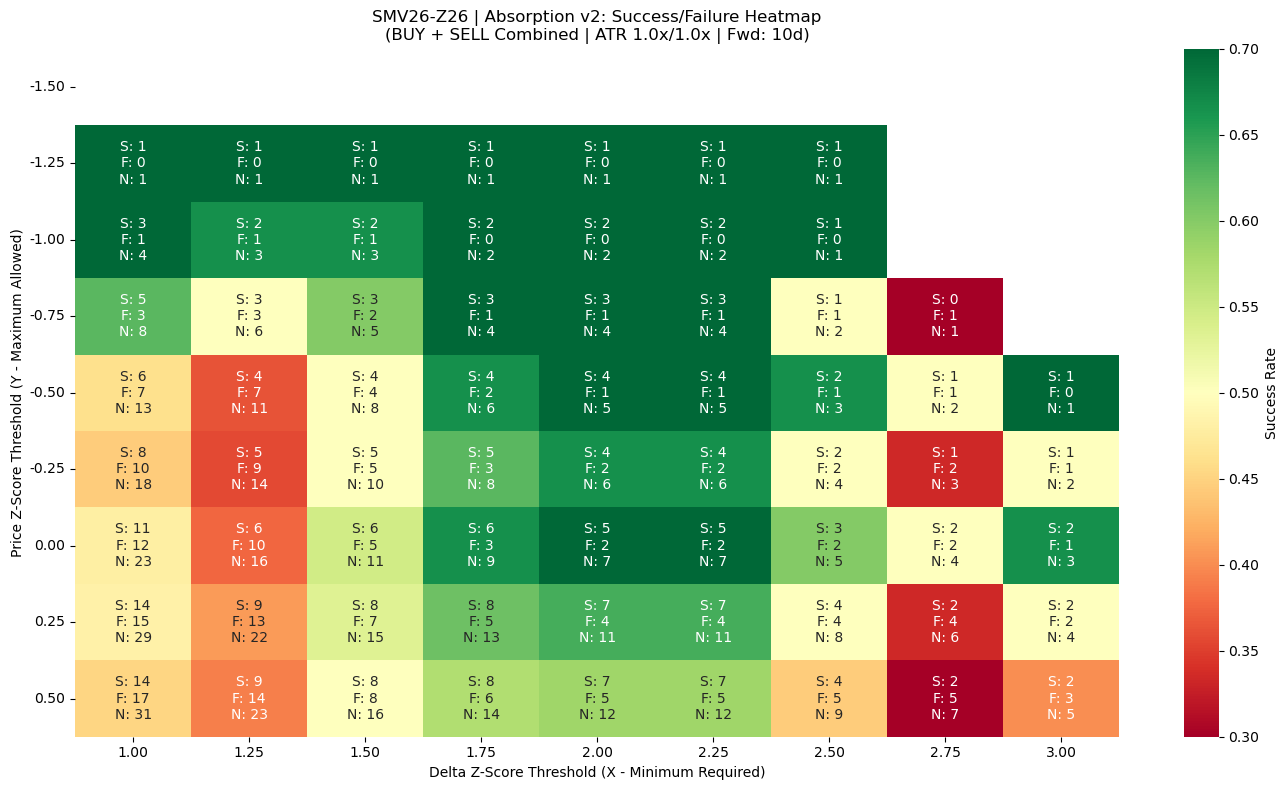

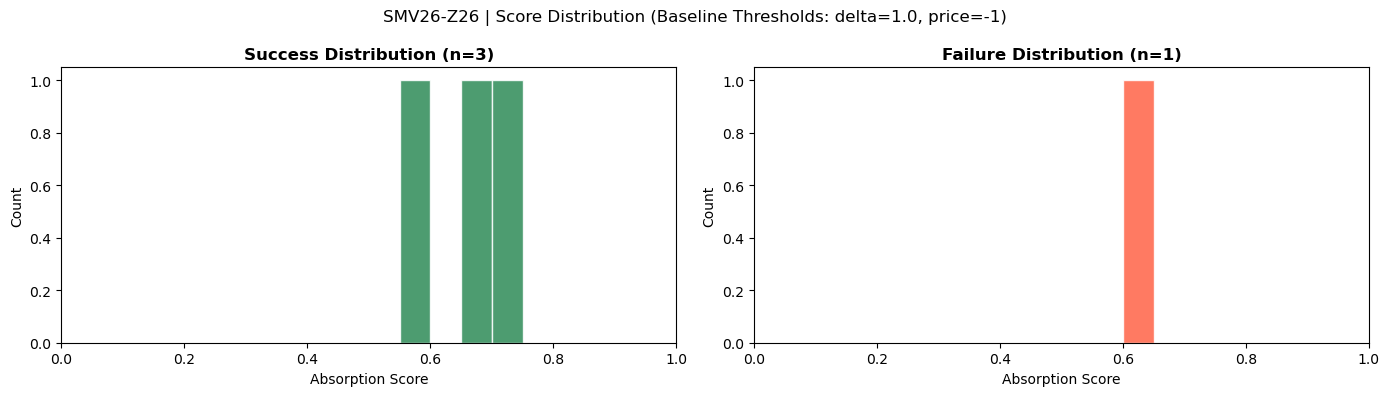

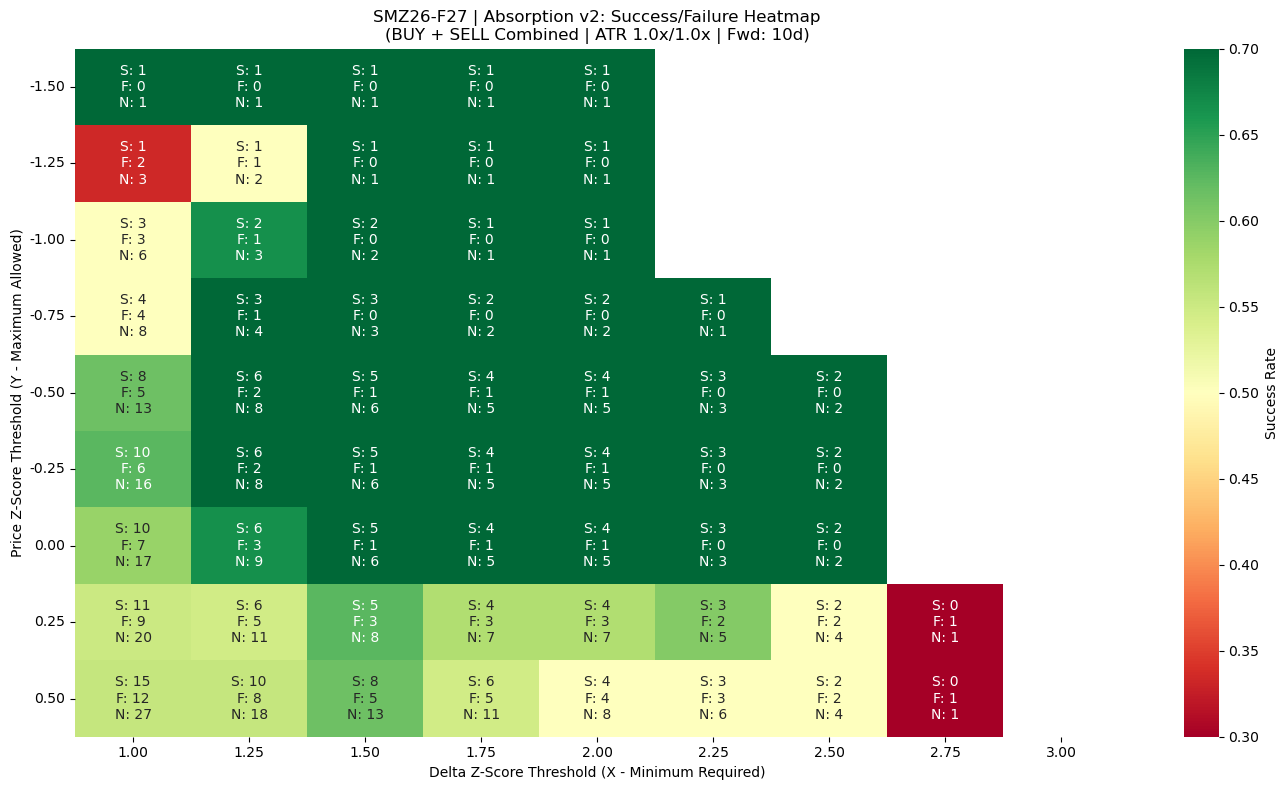

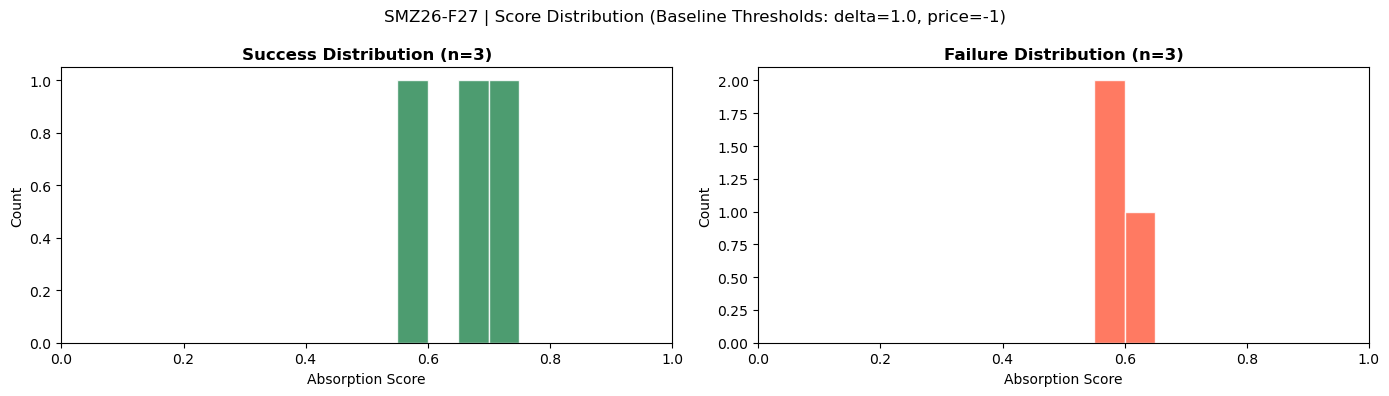

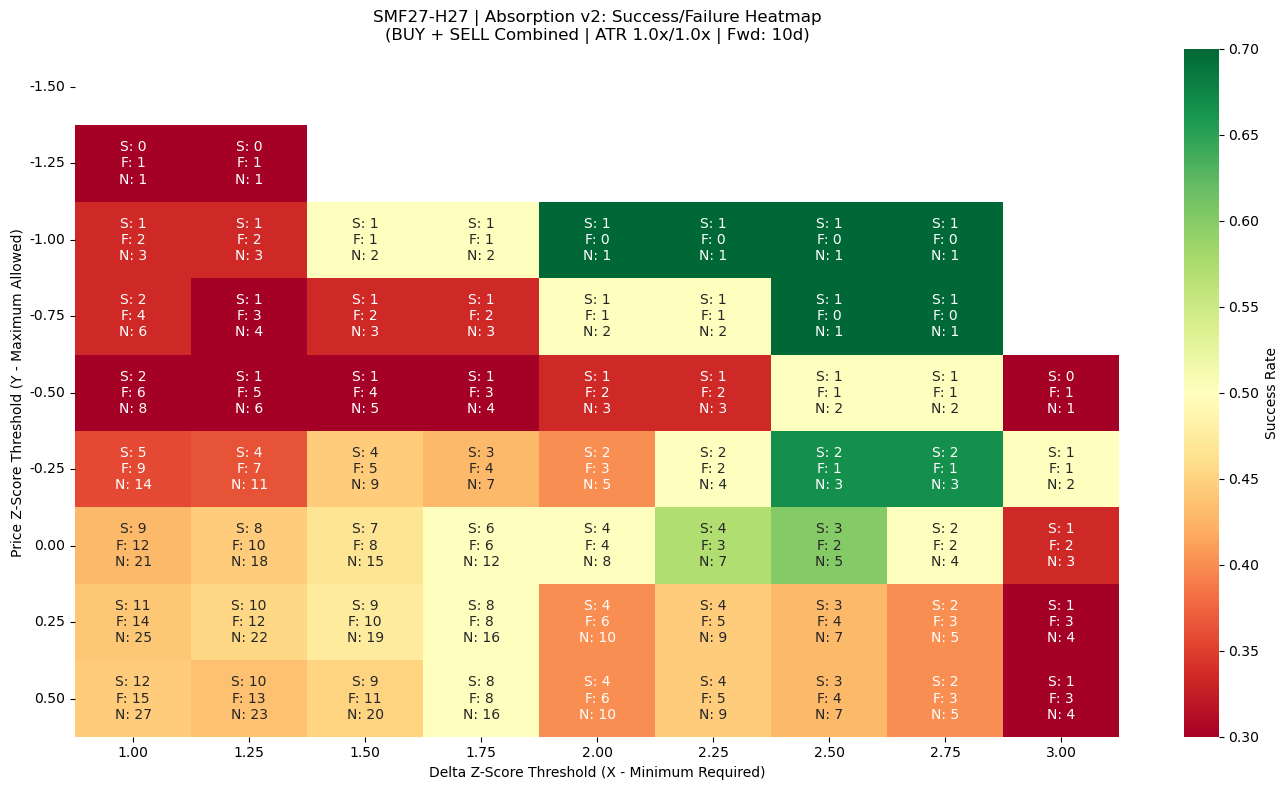

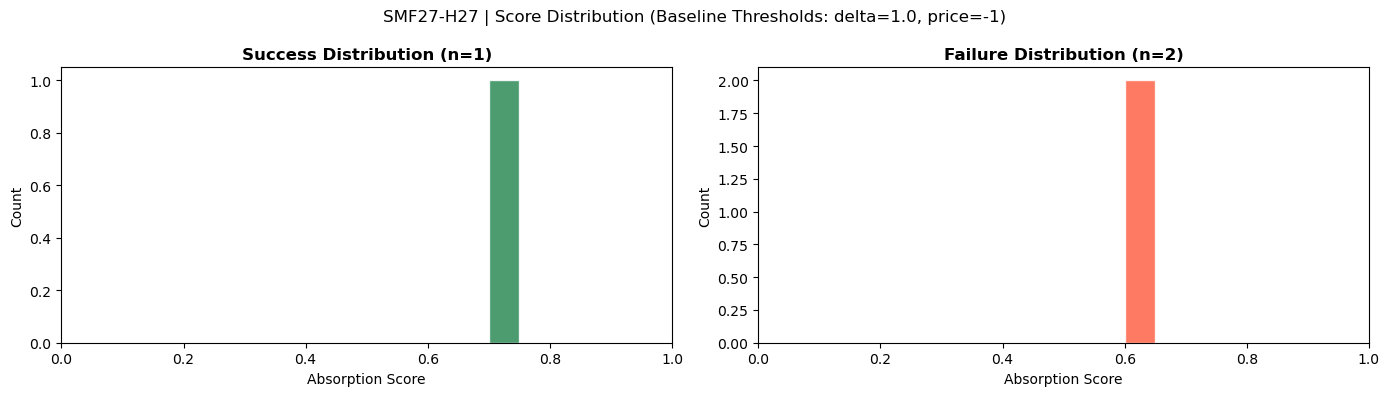

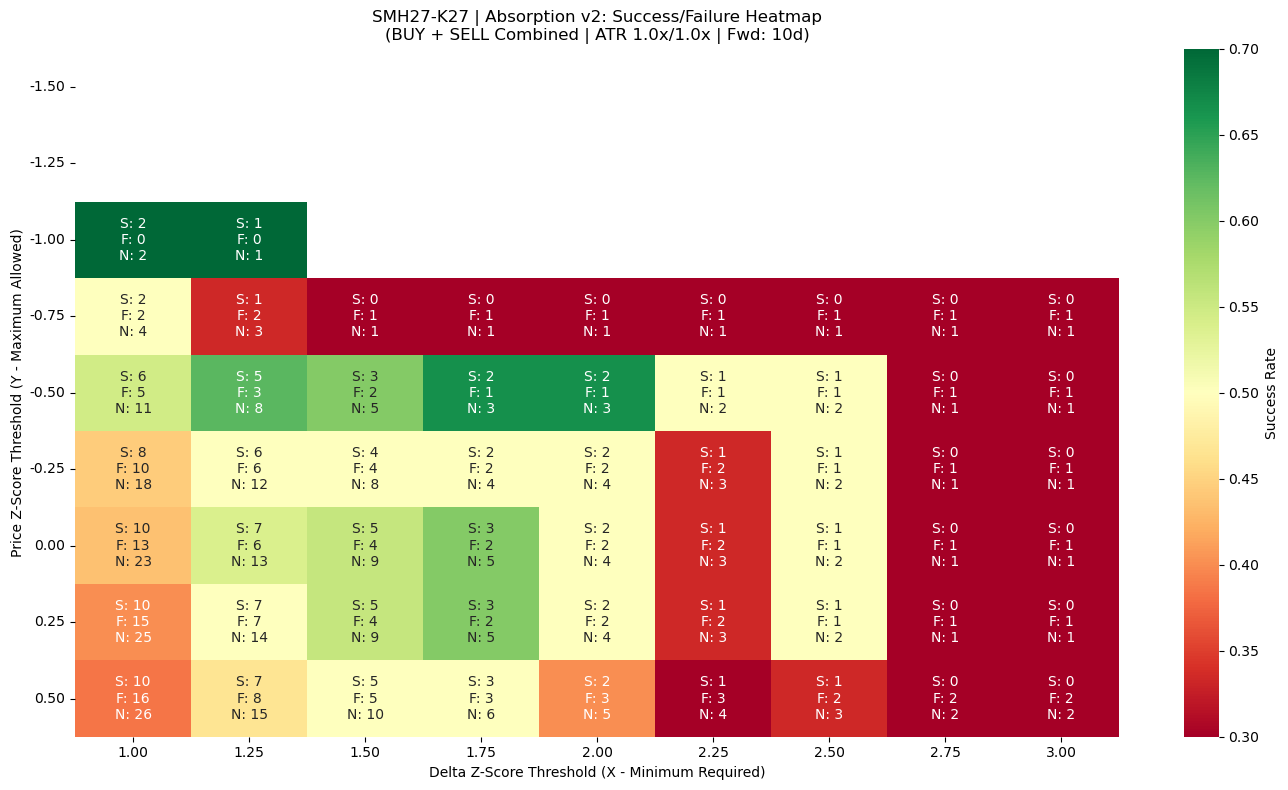

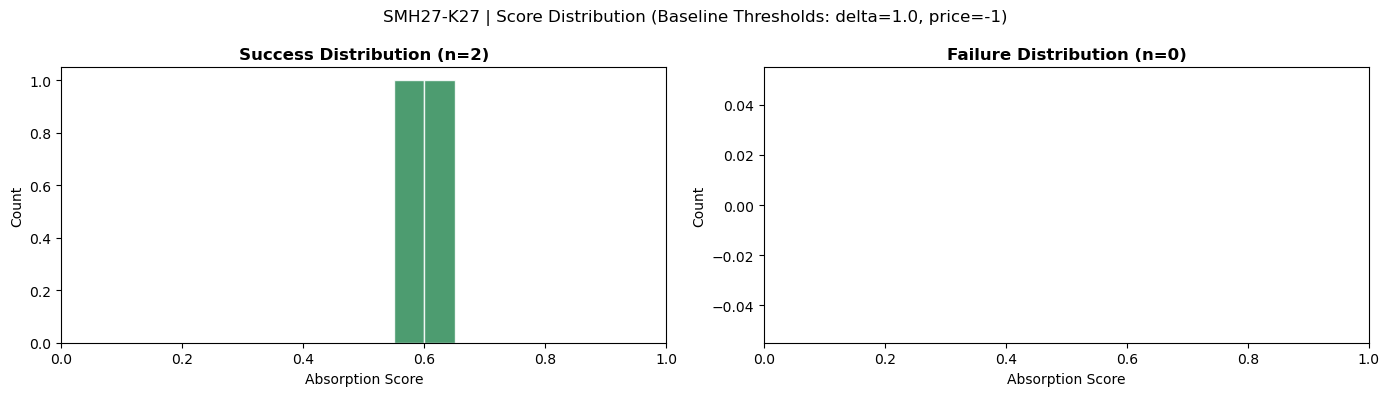

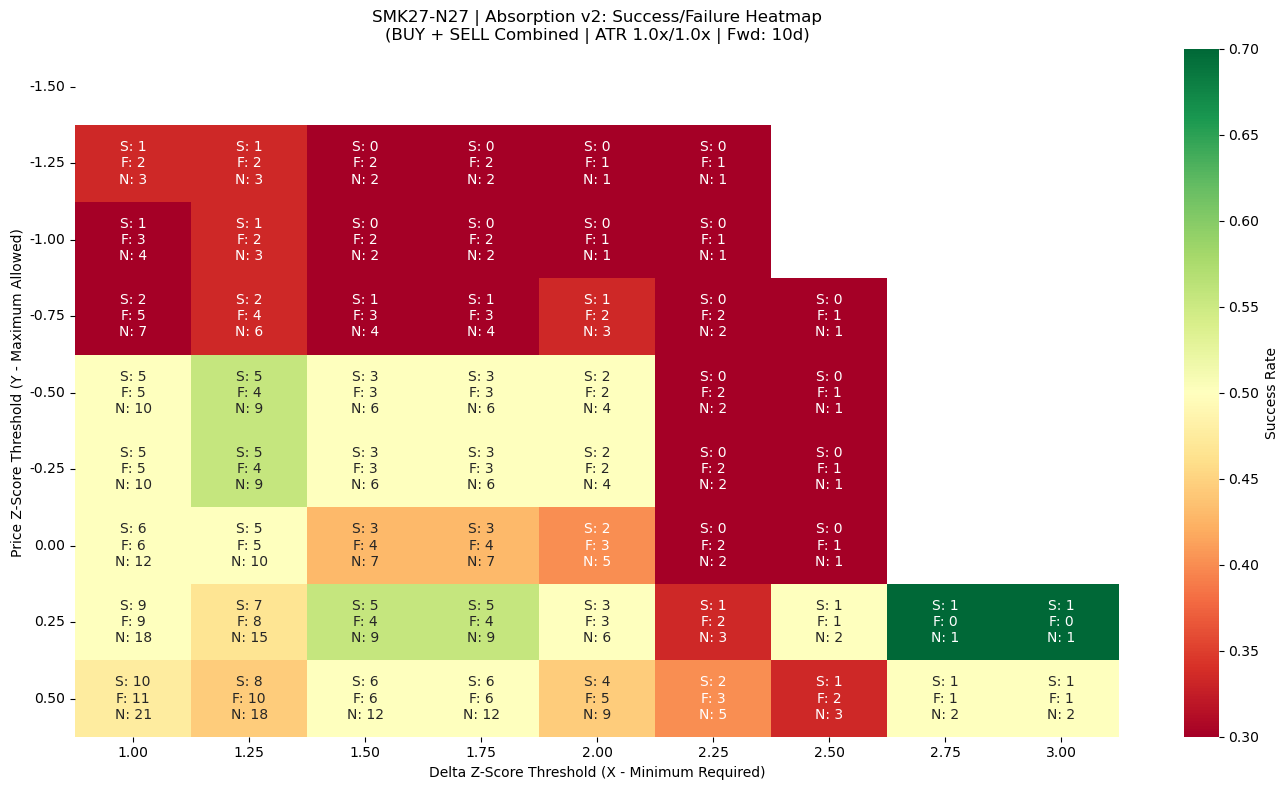

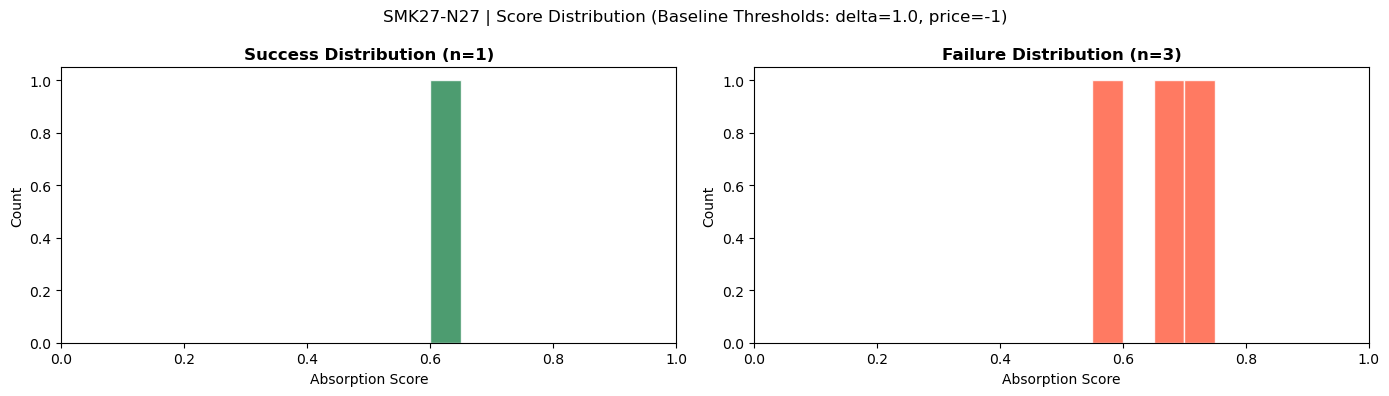

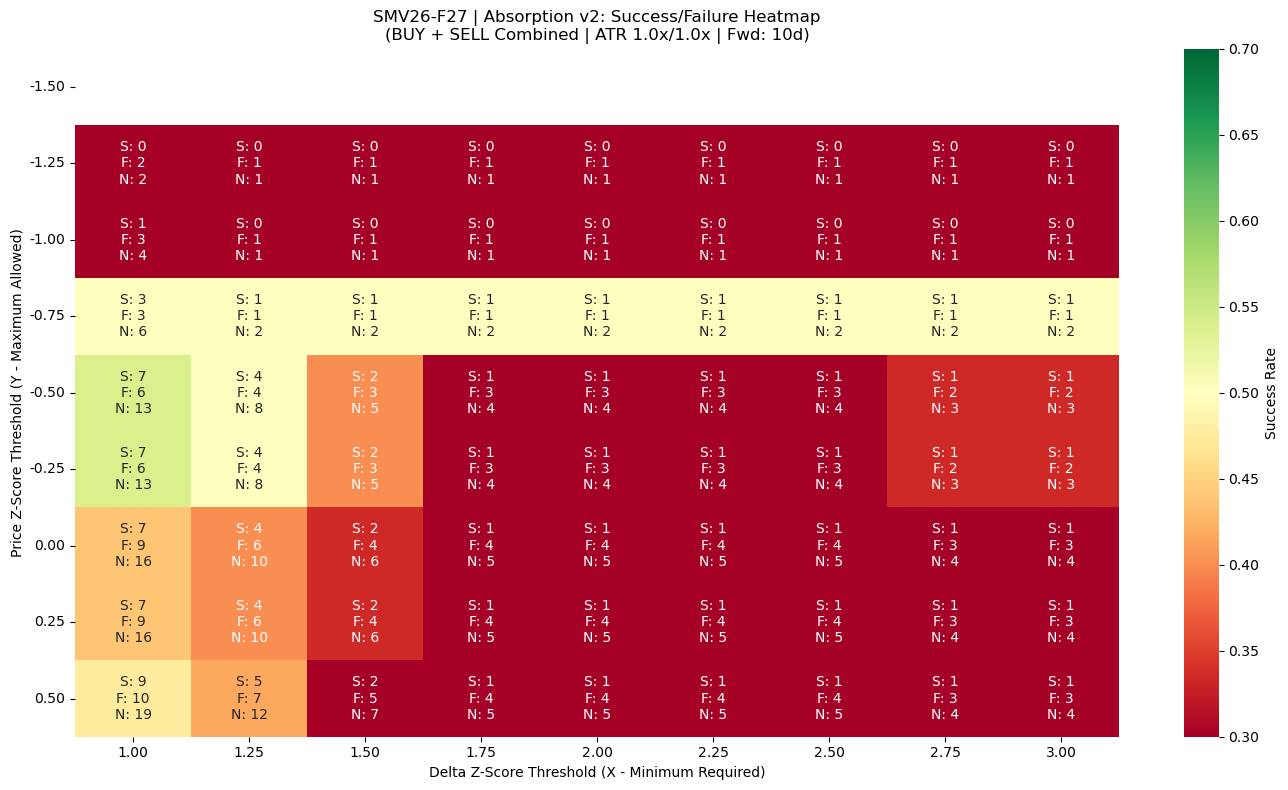

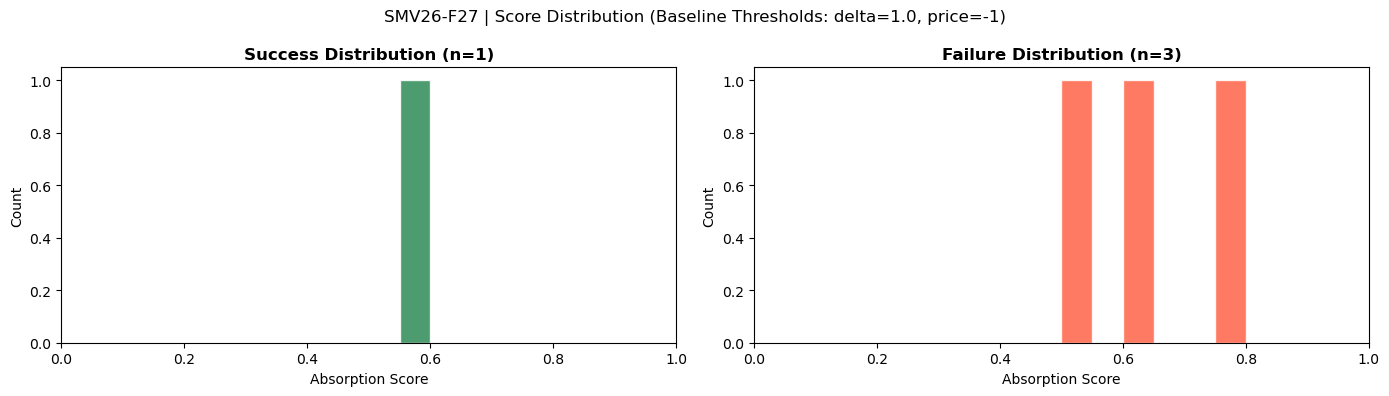

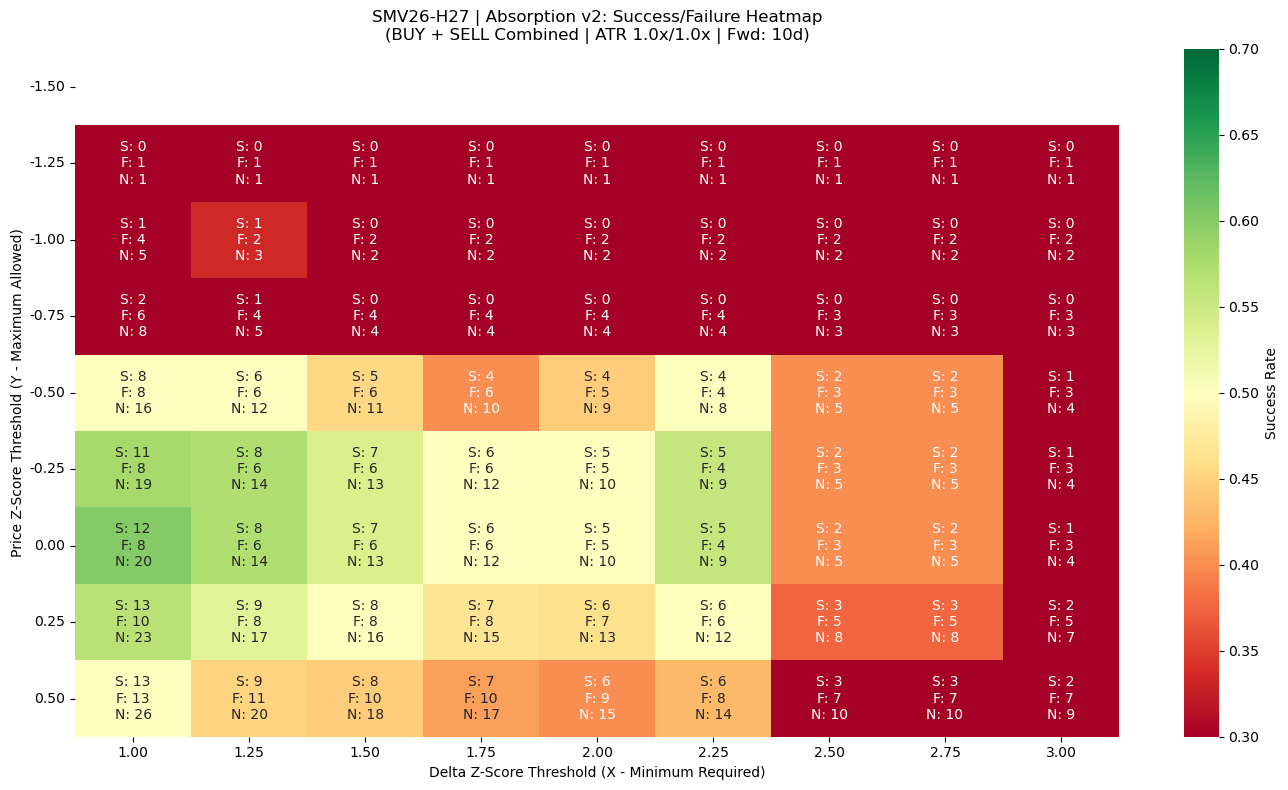

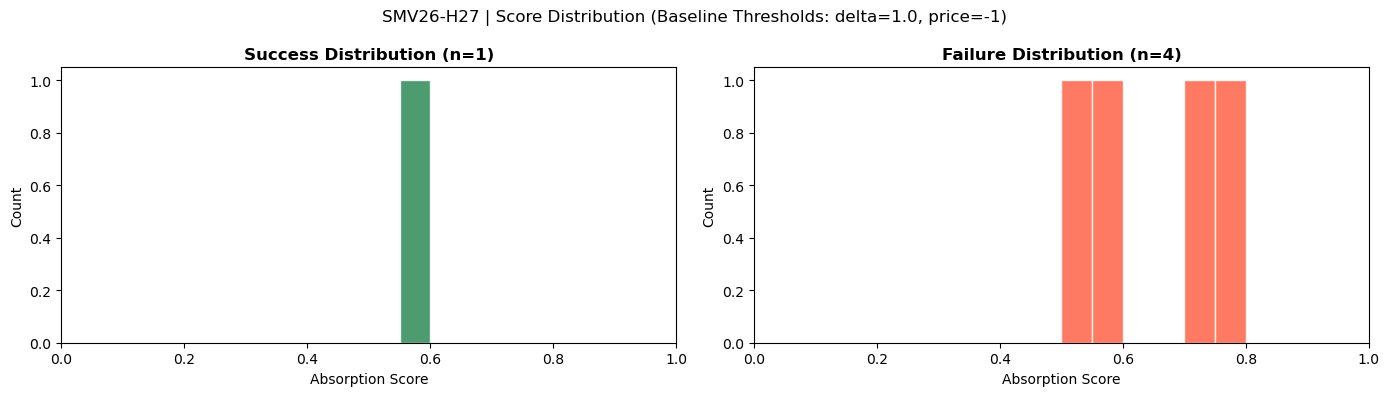

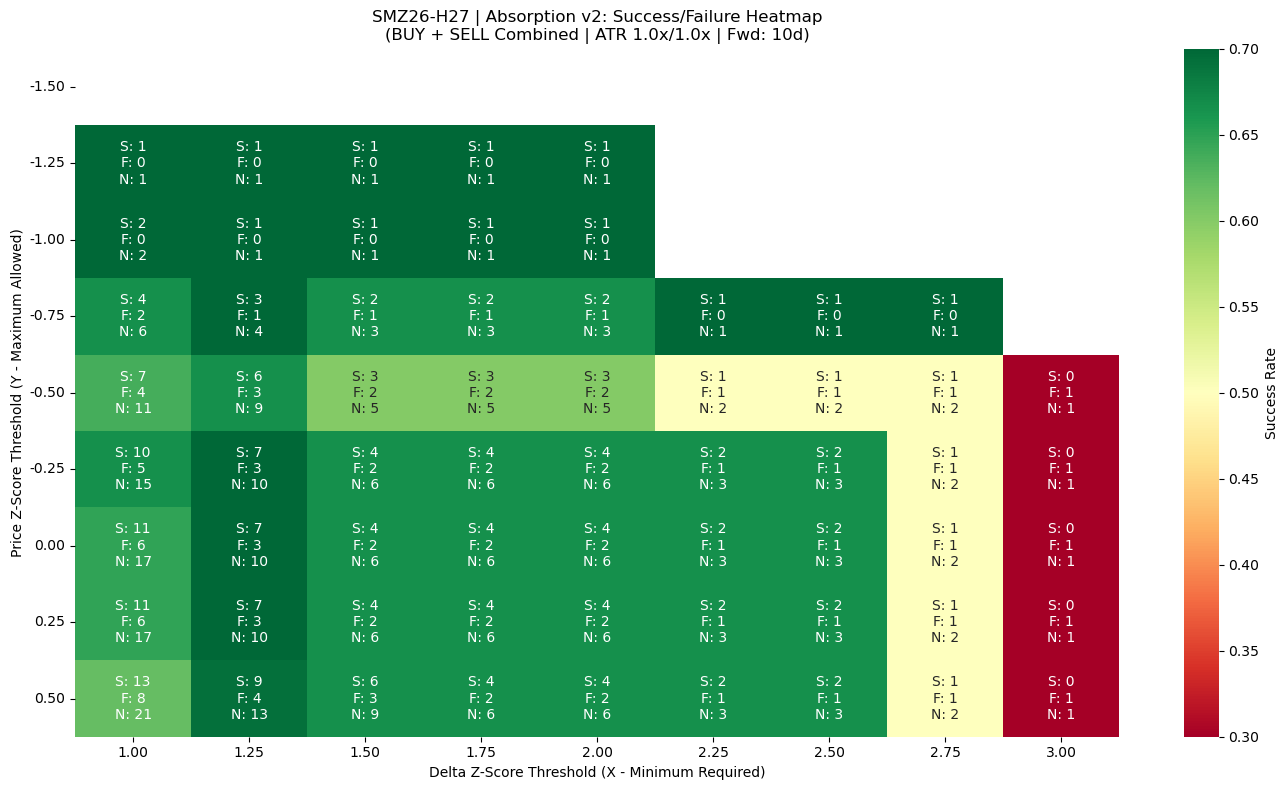

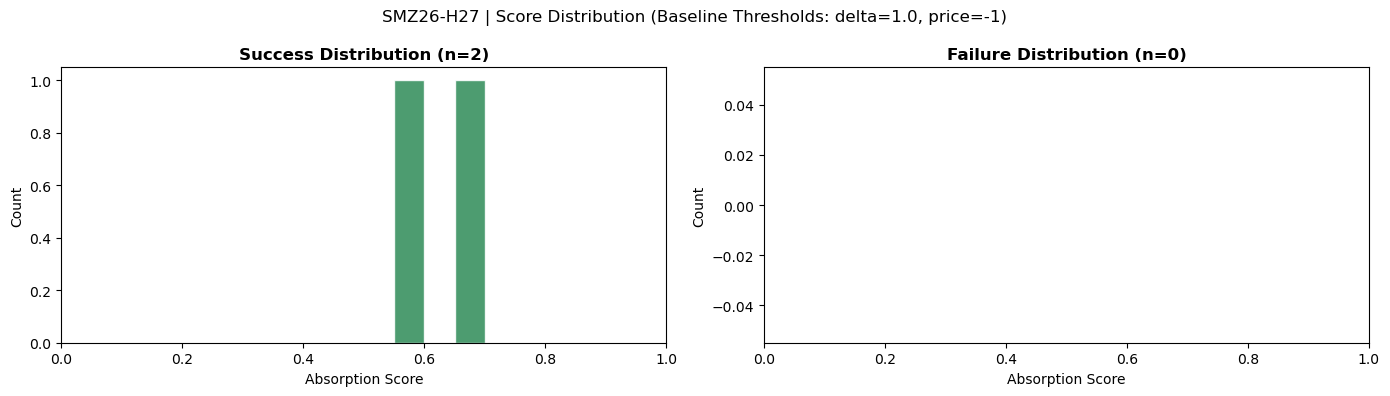

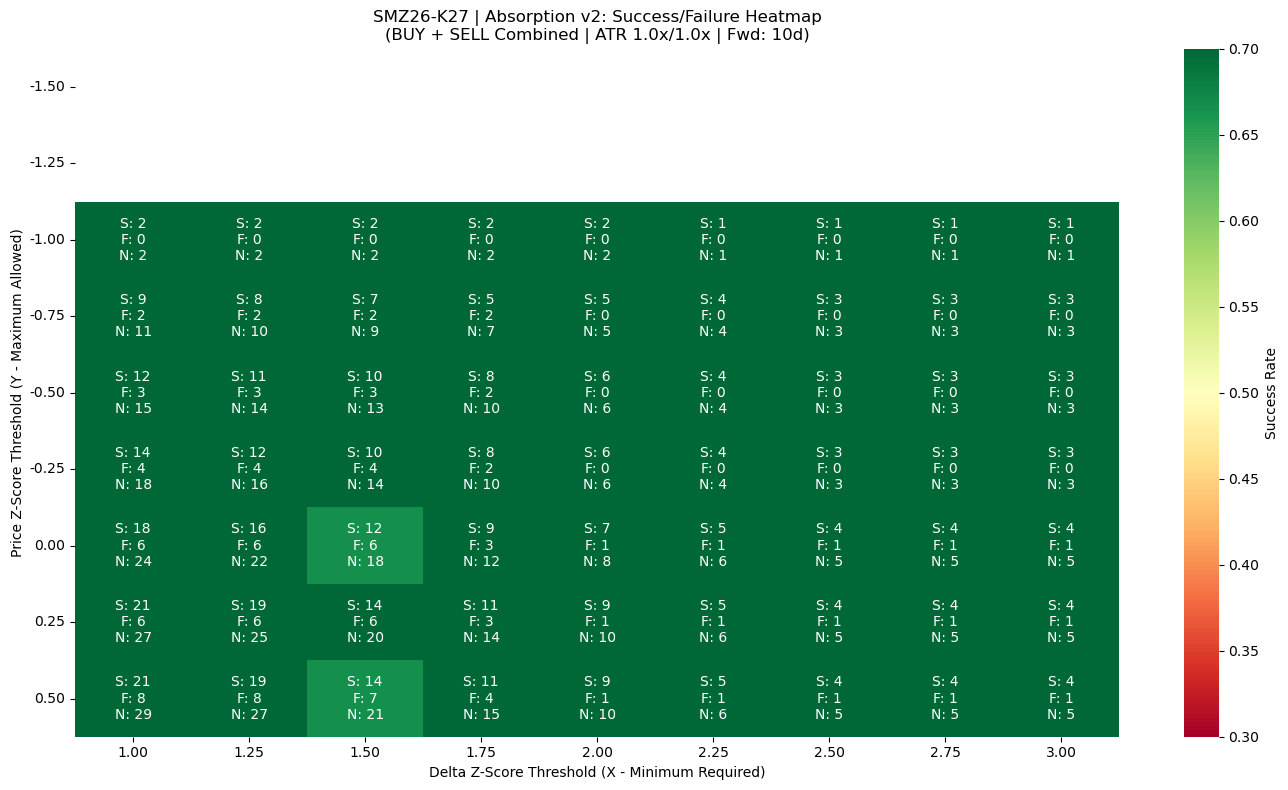

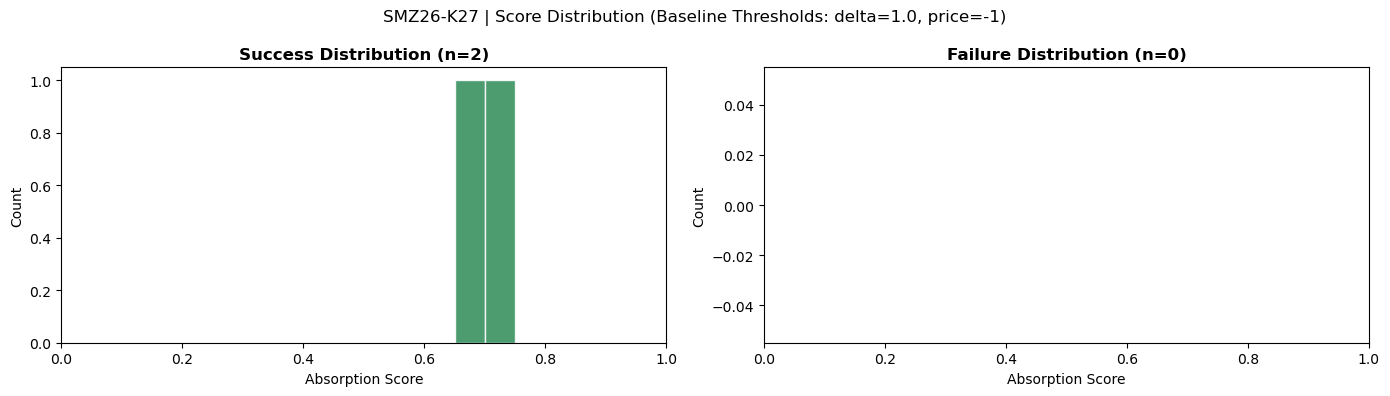

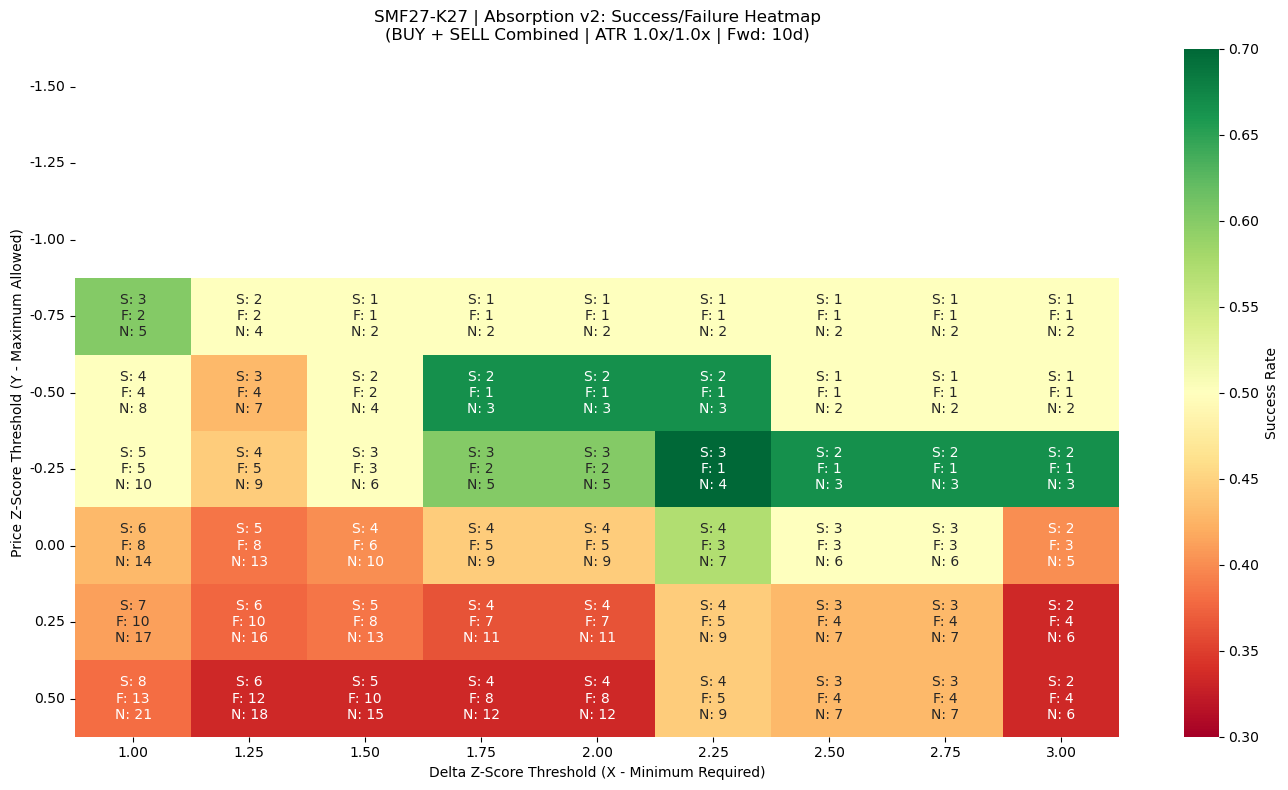

No valid signals for SMF27-K27 at baseline threshold (delta=1.0, price=-1) to plot distribution.




In [6]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the necessary modules from your project
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr

# ------------------------------------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------------------------------------
product_code = "SM"     # Change as needed
months_back = 8
front_n = 5

# Define the grids for the heatmap
delta_z_grid = np.arange(1.0, 3.25, 0.25)     # X-axis
price_z_grid = np.arange(0.5, -1.75, -0.25)   # Y-axis

# Fixed baseline thresholds used ONLY for calculating the continuous absorption_score 
# for the distribution plots (since the heatmap tests multiple thresholds)
dist_delta_z = 1.0
dist_price_z = -1

# Scorer parameters (z-score rolling window sizes)
v2_params = {
    "volume_window": 5,
    "atr_window": 5,
    "baseline_window": 30,
}

# ATR labeling parameters
atr_period = 14
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10

# ------------------------------------------------------------------------------
# 2. FETCH, PROCESS & PLOT FOR EACH INDIVIDUAL INSTRUMENT
# ------------------------------------------------------------------------------
start_date = (pd.Timestamp.now() - pd.DateOffset(months=months_back)).strftime("%Y-%m-%d")
end_date = pd.Timestamp.now().strftime("%Y-%m-%d")

# Gather all instruments from all structures
instruments = []
for insts in get_all_front_instruments(product_code, reference_date=None, front_n=front_n).values():
    instruments.extend(insts)

print(f"Generating independent heatmaps & distributions for {len(instruments)} instruments. Please wait...\n")

for inst in instruments:
    # 1. Fetch OHLC
    df = fetch_ohlc_1d(inst, product_code, getData_OHLC_v2, start_date, end_date)
    if df is None or len(df) < 30:
        print(f"Skipping {inst} (insufficient data)")
        continue
    
    # 2. Calculate z-scores using the baseline thresholds so the native absorption_score is populated correctly
    df = calculate_absorption_v2(
        df, 
        volume_window=v2_params["volume_window"], 
        atr_window=v2_params["atr_window"], 
        baseline_window=v2_params["baseline_window"],
        delta_z_threshold=dist_delta_z, 
        price_z_threshold=dist_price_z
    )
    
    # SAVE the real calculated direction so we don't lose it when tricking the labeler
    real_direction = df["absorption_direction"].copy()
    
    # 3. Trick the labeler: Evaluate EVERY bar as a potential BUY
    df["absorption_direction"] = "BUY"
    df_buy = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )
    
    # 4. Trick the labeler: Evaluate EVERY bar as a potential SELL
    df["absorption_direction"] = "SELL"
    df_sell = label_absorption_atr(
        df, atr_period=atr_period, target_atr_mult=target_atr_mult, 
        stop_atr_mult=stop_atr_mult, forward_days=forward_days
    )

    # RESTORE the real direction so the distribution plot works correctly later
    df["absorption_direction"] = real_direction

    # ------------------------------------------------------------------------------
    # 3. COMPUTE HEATMAP MATRICES FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    n_price = len(price_z_grid)
    n_delta = len(delta_z_grid)

    heat_rate = np.zeros((n_price, n_delta))
    annot_labels = np.empty((n_price, n_delta), dtype=object)

    for i, pz in enumerate(price_z_grid):
        for j, dz in enumerate(delta_z_grid):

            # BUY absorption mask (Custom logic)
            buy_mask = (df["z_delta"] >= dz) & (df["z_price"] <= pz)

            # SELL absorption mask (Custom logic)
            sell_mask = (df["z_delta"] <= -dz) & (df["z_price"] <= pz)

            # BUY outcomes
            buy_succ = (df_buy.loc[buy_mask, "sl_success"] == 1.0).sum()
            buy_fail = (df_buy.loc[buy_mask, "sl_success"] == 0.0).sum()

            # SELL outcomes
            sell_succ = (df_sell.loc[sell_mask, "sl_success"] == 1.0).sum()
            sell_fail = (df_sell.loc[sell_mask, "sl_success"] == 0.0).sum()

            # COMBINE BOTH
            tot_succ = buy_succ + sell_succ
            tot_fail = buy_fail + sell_fail
            tot_valid = tot_succ + tot_fail

            if tot_valid > 0:
                heat_rate[i, j] = tot_succ / tot_valid
                annot_labels[i, j] = (f"S: {tot_succ}\nF: {tot_fail}\nN: {tot_valid}")
            else:
                heat_rate[i, j] = np.nan
                annot_labels[i, j] = "N/A"

    # ------------------------------------------------------------------------------
    # 4. PLOT HEATMAP FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    plt.figure(figsize=(14, 8))

    ax = sns.heatmap(
        heat_rate, 
        annot=annot_labels, 
        fmt="",                # Disables formatting so our custom string works
        cmap="RdYlGn", 
        vmin=0.3, vmax=0.7,    # Lock color scale (30% to 70% success rate)
        cbar_kws={'label': 'Success Rate'}
    )

    ax.set_xticklabels([f"{dz:.2f}" for dz in delta_z_grid])
    ax.set_yticklabels([f"{pz:.2f}" for pz in price_z_grid], rotation=0)

    # Invert Y-axis so smaller values (e.g. -1.5) are at the bottom of the chart
    ax.invert_yaxis()

    plt.xlabel("Delta Z-Score Threshold (X - Minimum Required)")
    plt.ylabel("Price Z-Score Threshold (Y - Maximum Allowed)")
    plt.title(f"{inst} | Absorption v2: Success/Failure Heatmap\n(BUY + SELL Combined | ATR {target_atr_mult}x/{stop_atr_mult}x | Fwd: {forward_days}d)")

    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------------------
    # 5. PLOT DISTRIBUTION FOR THIS EXACT INSTRUMENT
    # ------------------------------------------------------------------------------
    # To plot the distribution of absorption_score, we use the real outcomes mapped 
    # from the baseline thresholds configured at the top (dist_delta_z, dist_price_z).
    
    dist_buy_mask = (df["absorption_direction"] == "BUY")
    dist_sell_mask = (df["absorption_direction"] == "SELL")
    
    df["final_success"] = np.nan
    df.loc[dist_buy_mask, "final_success"] = df_buy.loc[dist_buy_mask, "sl_success"]
    df.loc[dist_sell_mask, "final_success"] = df_sell.loc[dist_sell_mask, "sl_success"]
    
    valid_dist = df.dropna(subset=["final_success"])
    
    if len(valid_dist) > 0:
        s_scores = valid_dist.loc[valid_dist["final_success"] == 1.0, "absorption_score"]
        f_scores = valid_dist.loc[valid_dist["final_success"] == 0.0, "absorption_score"]
        
        bins = np.arange(0, 1.05, 0.05)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
        
        ax1.hist(s_scores, bins=bins, color="seagreen", edgecolor="white", alpha=0.85)
        ax1.set_title(f"Success Distribution (n={len(s_scores)})", fontweight="bold")
        ax1.set_xlabel("Absorption Score")
        ax1.set_ylabel("Count")
        ax1.set_xlim([0, 1])
        
        ax2.hist(f_scores, bins=bins, color="tomato", edgecolor="white", alpha=0.85)
        ax2.set_title(f"Failure Distribution (n={len(f_scores)})", fontweight="bold")
        ax2.set_xlabel("Absorption Score")
        ax2.set_ylabel("Count")
        ax2.set_xlim([0, 1])
        
        plt.suptitle(f"{inst} | Score Distribution (Baseline Thresholds: delta={dist_delta_z}, price={dist_price_z})")
        plt.tight_layout()
        plt.show()
    else:
        print(f"No valid signals for {inst} at baseline threshold (delta={dist_delta_z}, price={dist_price_z}) to plot distribution.")
        
    print("\n" + "="*80 + "\n")


# abs score in heatmap_block

Generating independent heatmaps & distributions for 10 instruments. Please wait...

Processing BOV26-Z26...


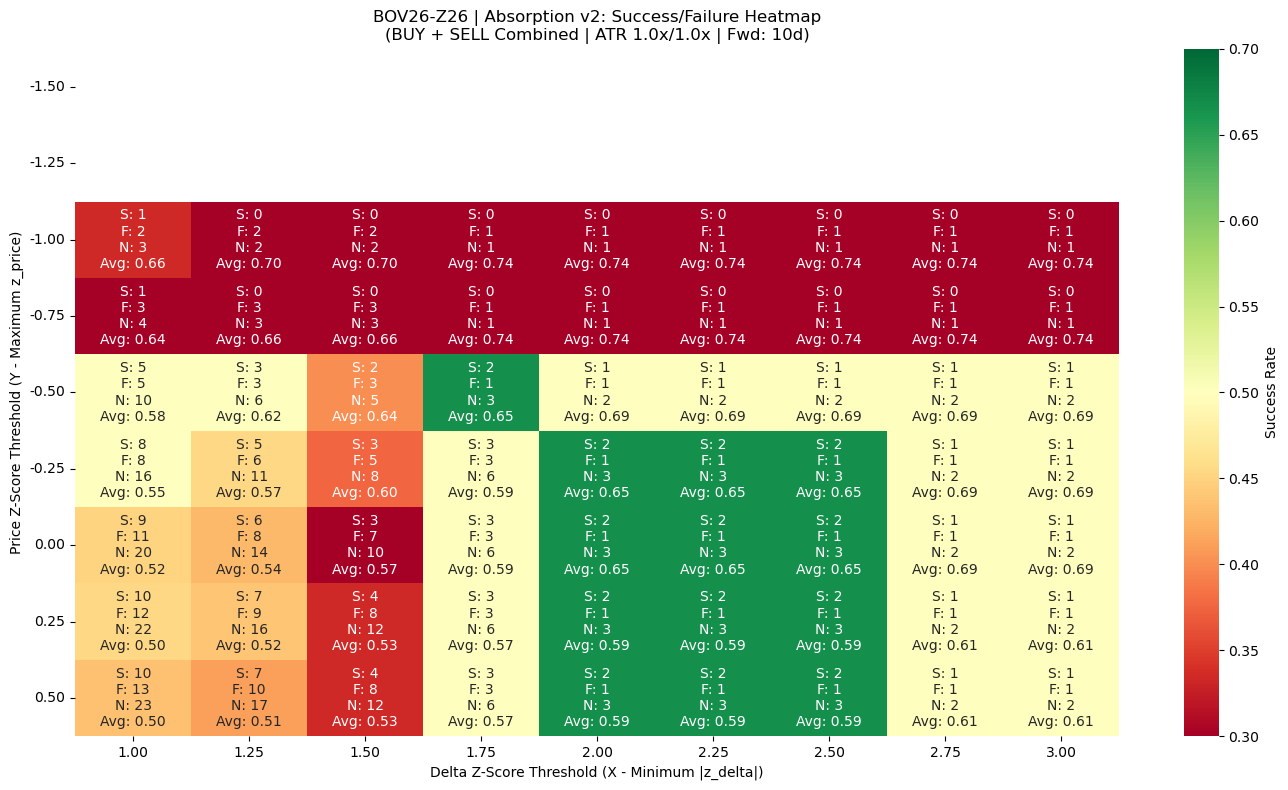

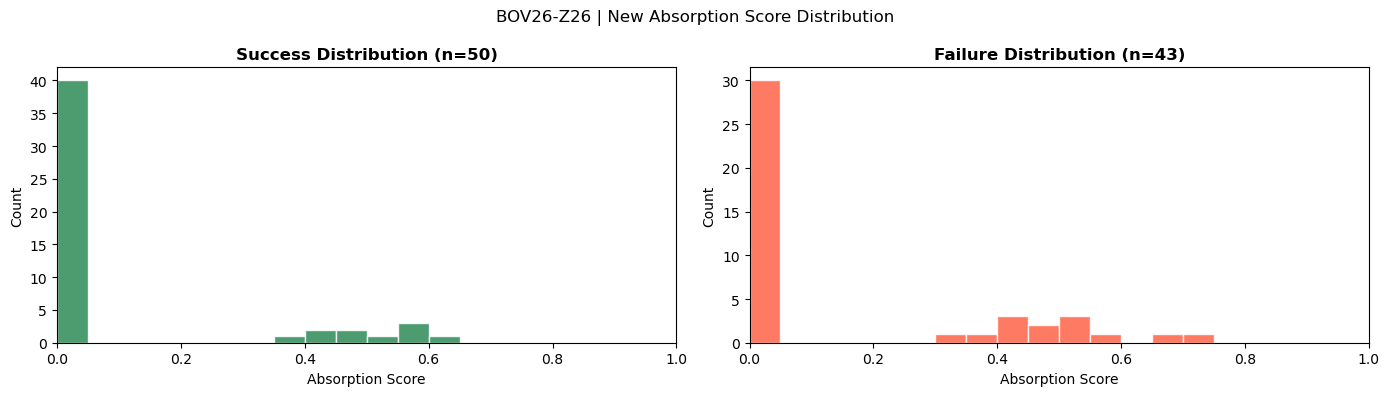


Score summary:
Successful signals : 50
Failed signals     : 43
Mean success score : 0.101
Mean failure score : 0.151


Processing BOZ26-F27...


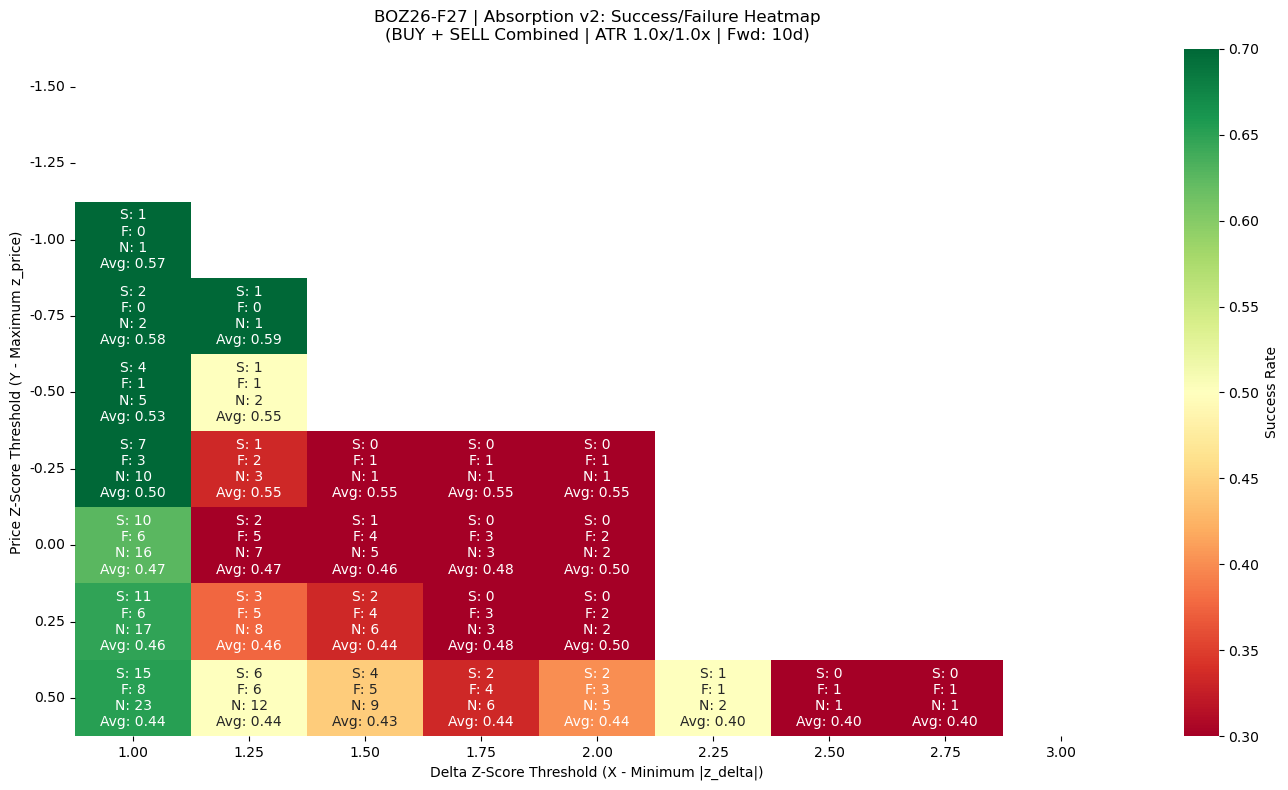

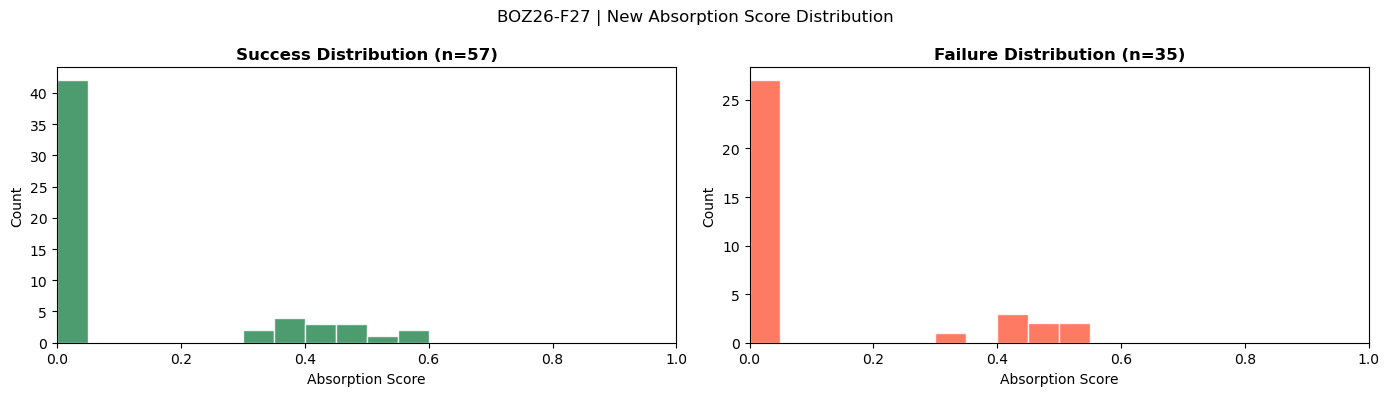


Score summary:
Successful signals : 57
Failed signals     : 35
Mean success score : 0.114
Mean failure score : 0.102


Processing BOF27-H27...


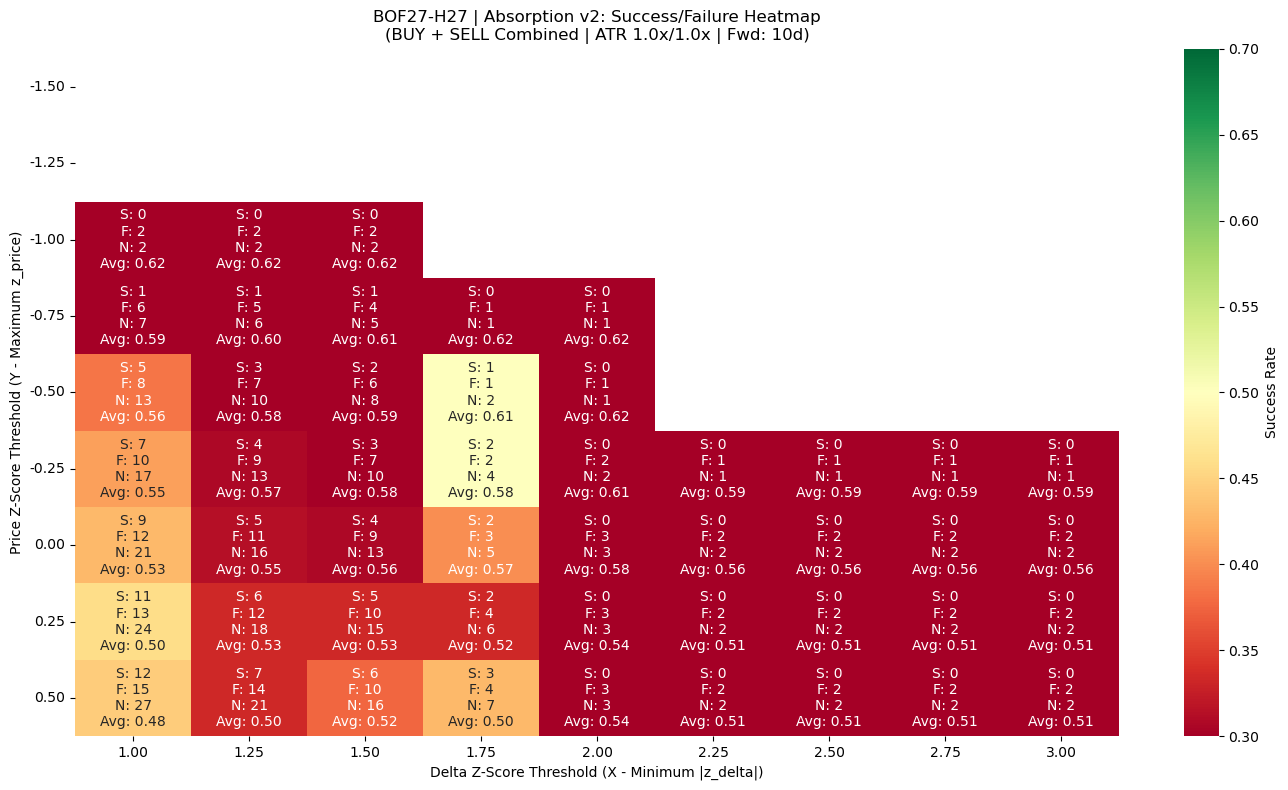

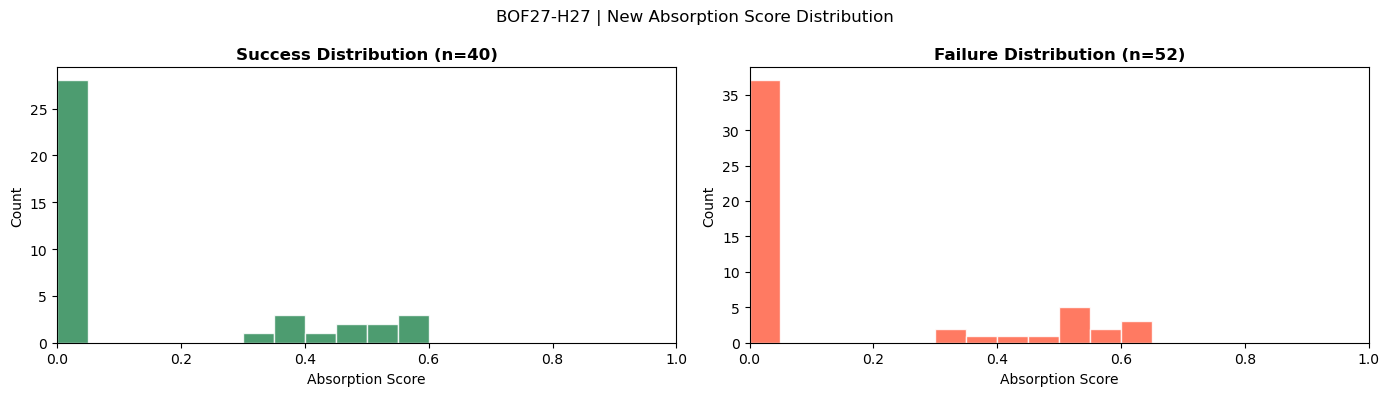


Score summary:
Successful signals : 40
Failed signals     : 52
Mean success score : 0.140
Mean failure score : 0.148


Processing BOH27-K27...


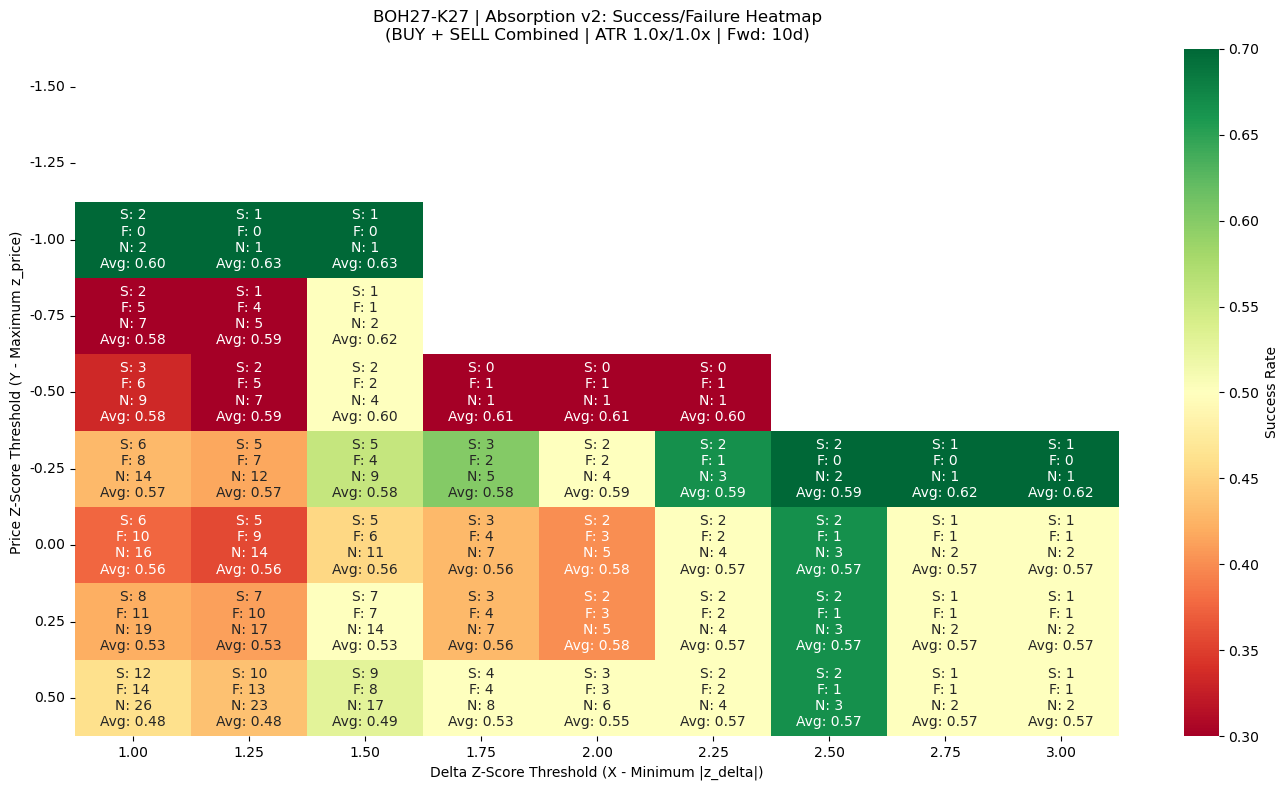

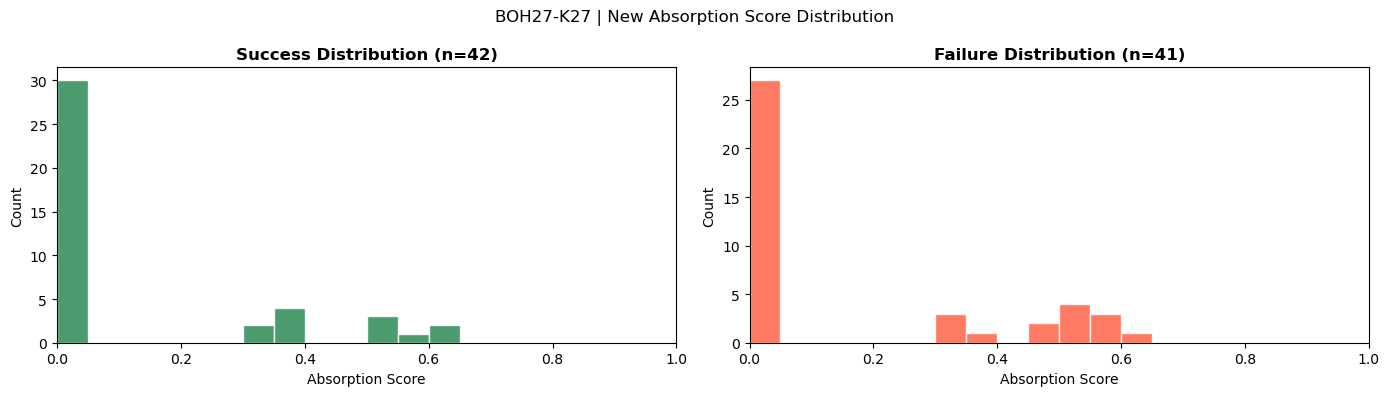


Score summary:
Successful signals : 42
Failed signals     : 41
Mean success score : 0.133
Mean failure score : 0.165


Processing BOK27-N27...


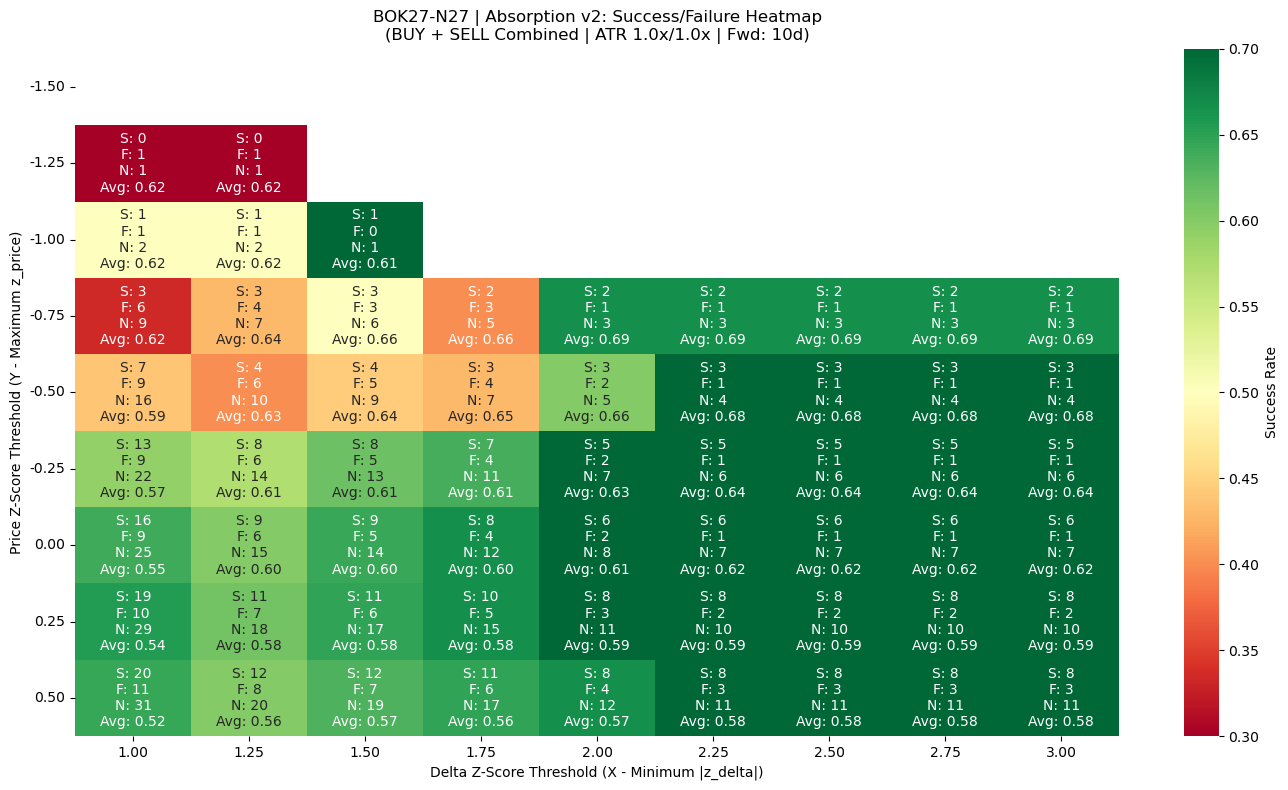

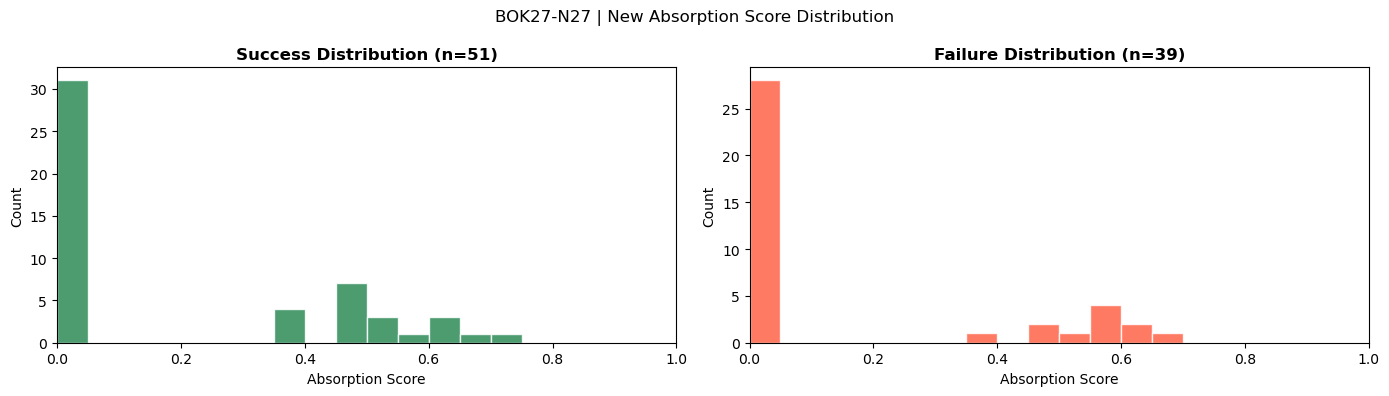


Score summary:
Successful signals : 51
Failed signals     : 39
Mean success score : 0.202
Mean failure score : 0.156


Processing BOV26-F27...


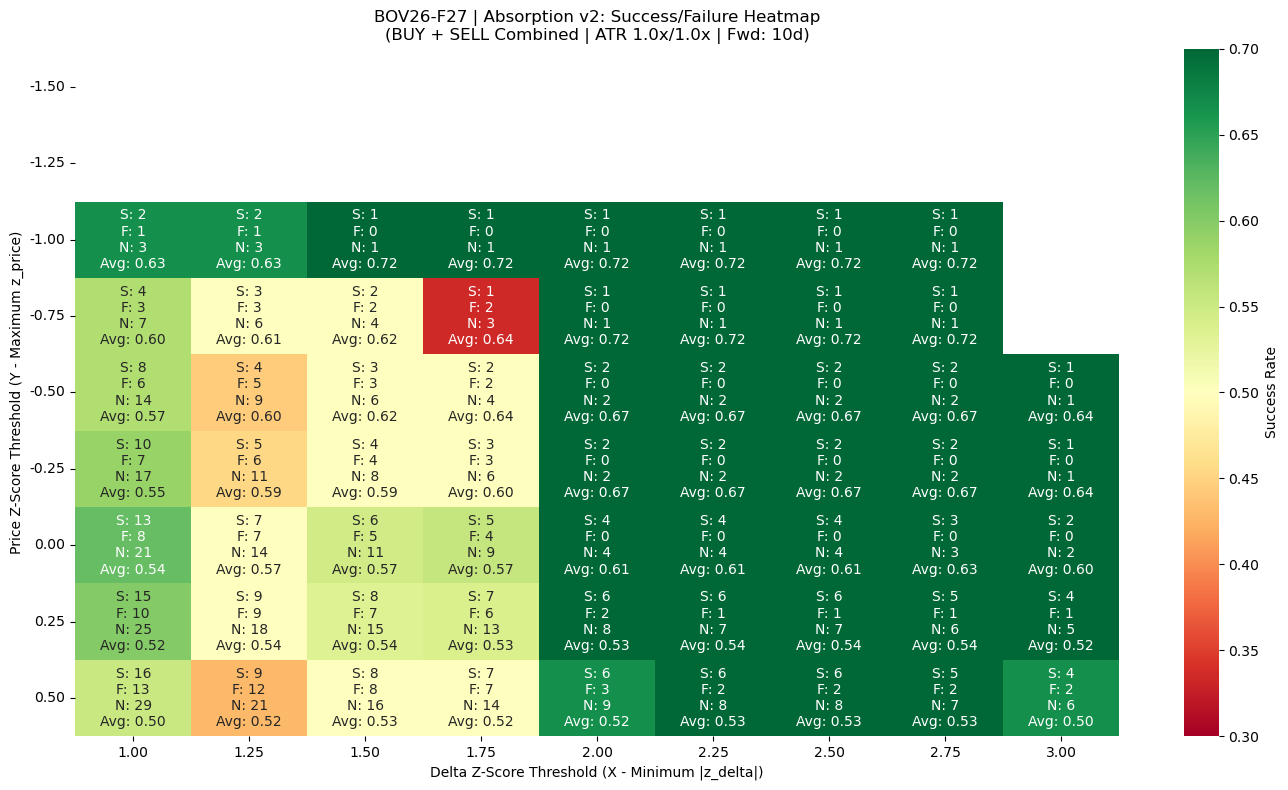

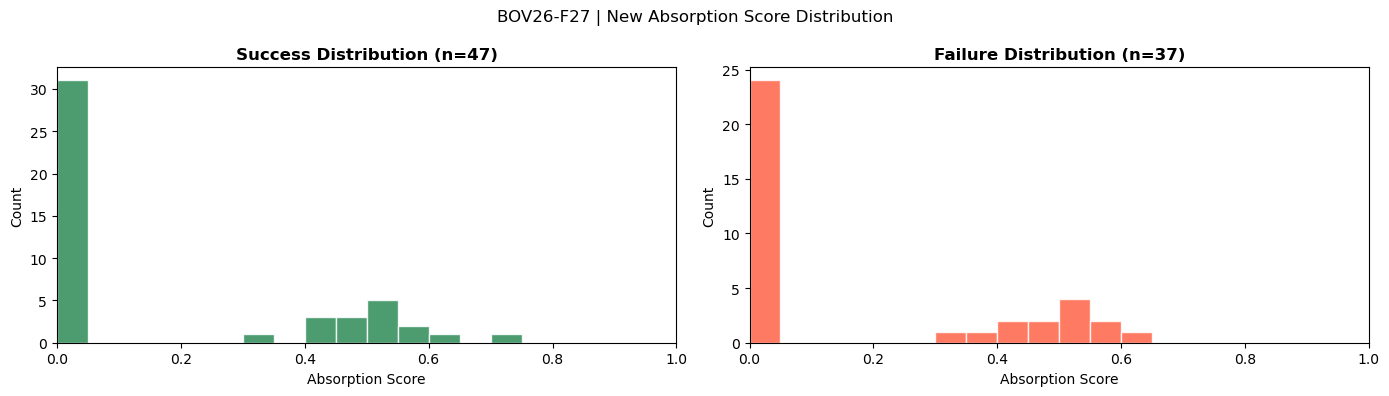


Score summary:
Successful signals : 47
Failed signals     : 37
Mean success score : 0.174
Mean failure score : 0.171


Processing BOV26-H27...


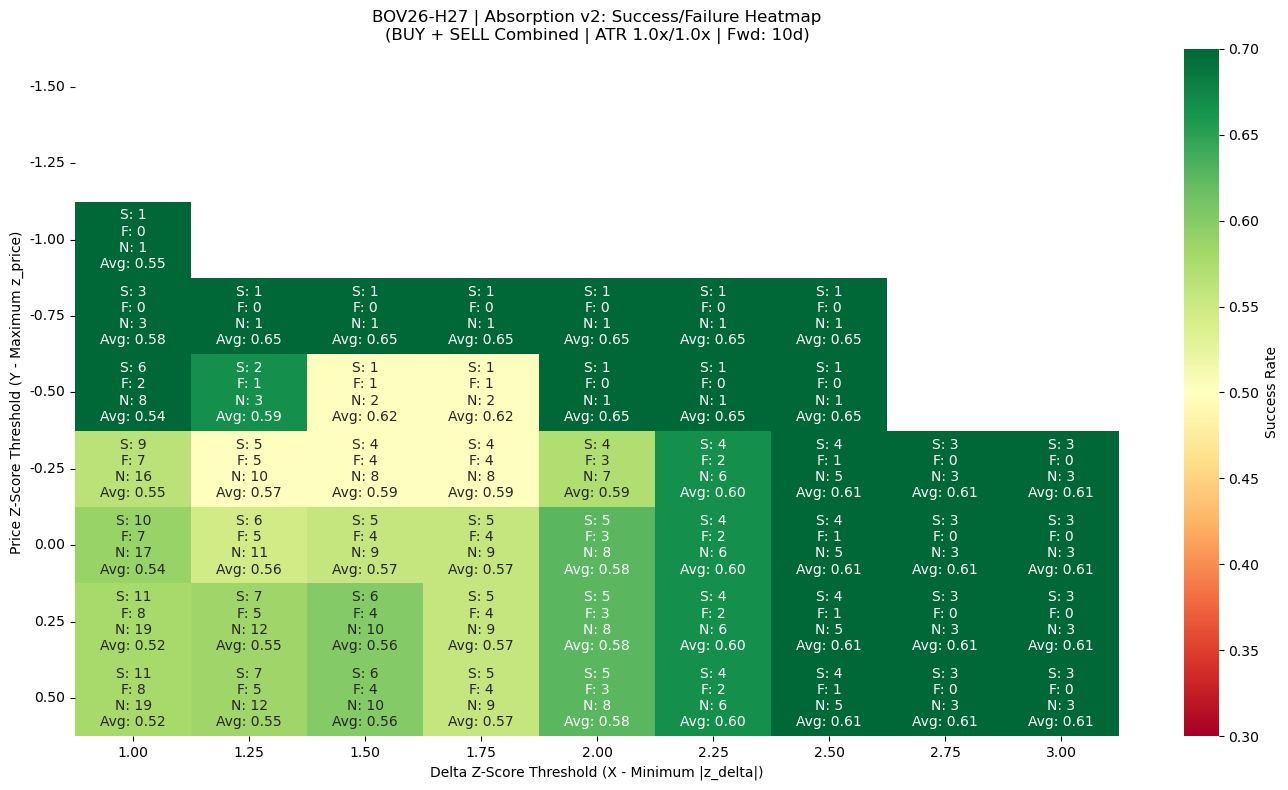

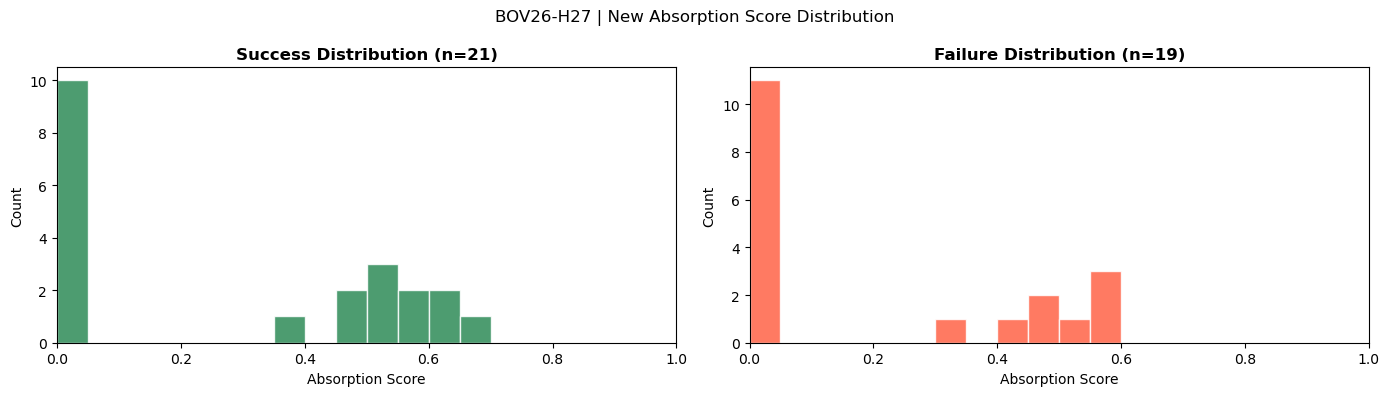


Score summary:
Successful signals : 21
Failed signals     : 19
Mean success score : 0.284
Mean failure score : 0.212


Processing BOZ26-H27...


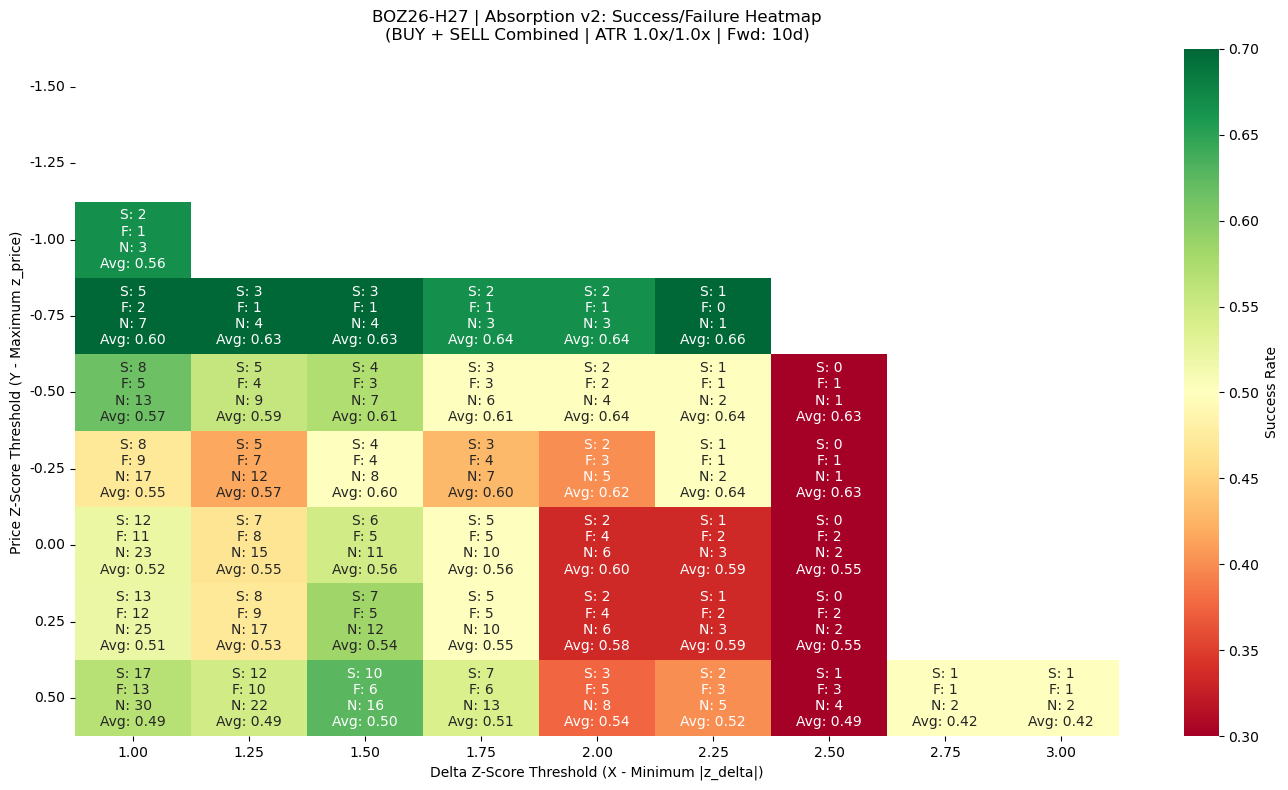

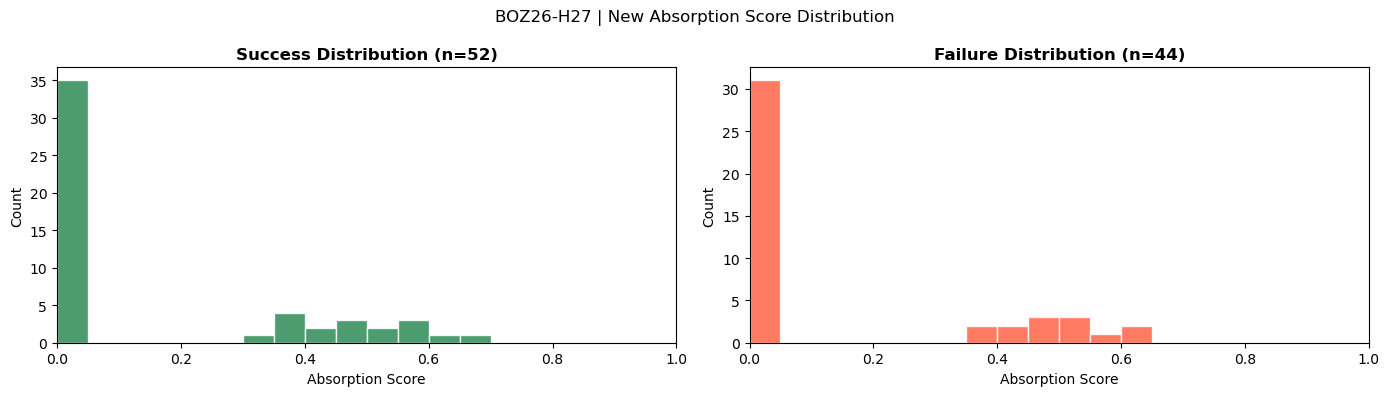


Score summary:
Successful signals : 52
Failed signals     : 44
Mean success score : 0.157
Mean failure score : 0.146


Processing BOZ26-K27...


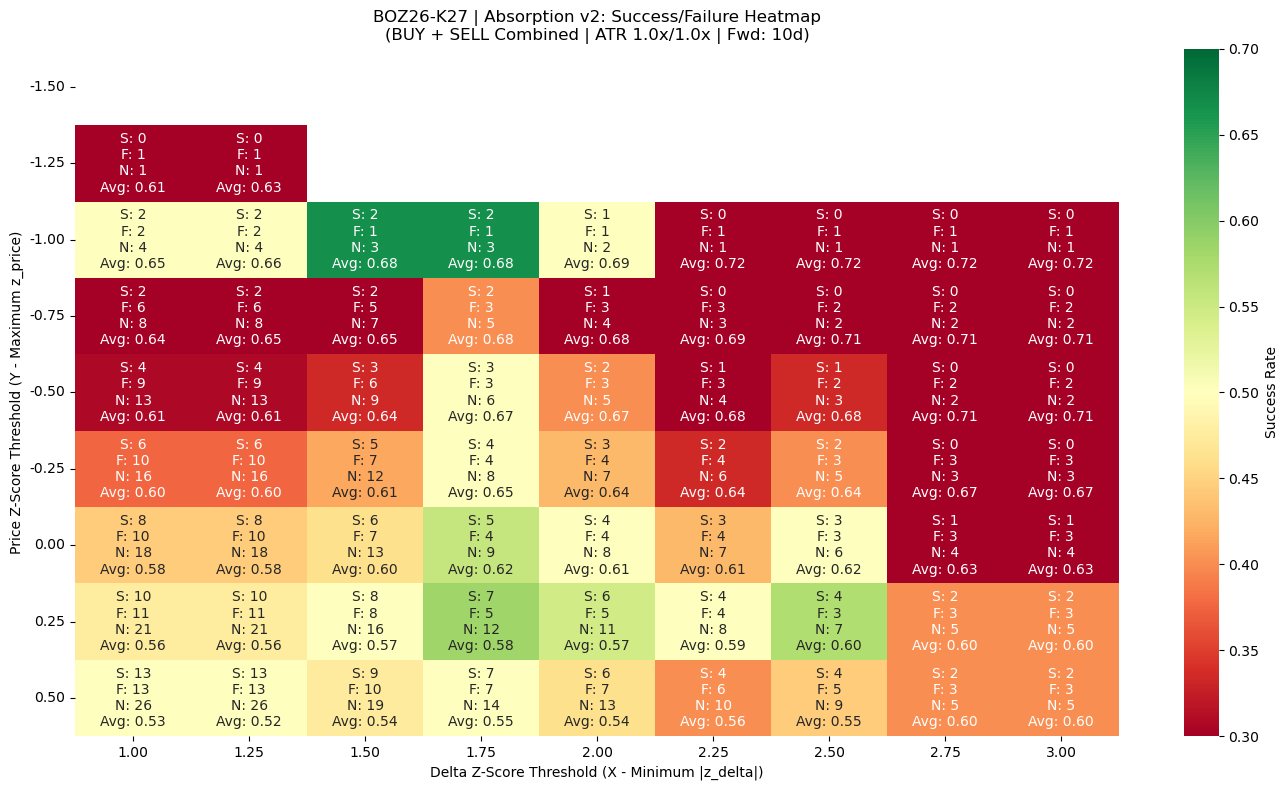

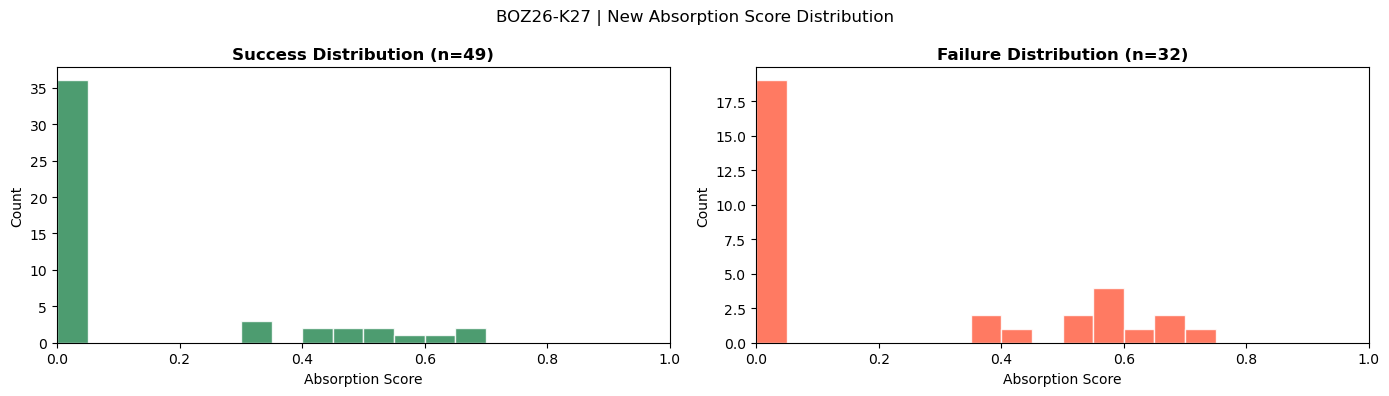


Score summary:
Successful signals : 49
Failed signals     : 32
Mean success score : 0.128
Mean failure score : 0.226


Processing BOF27-K27...


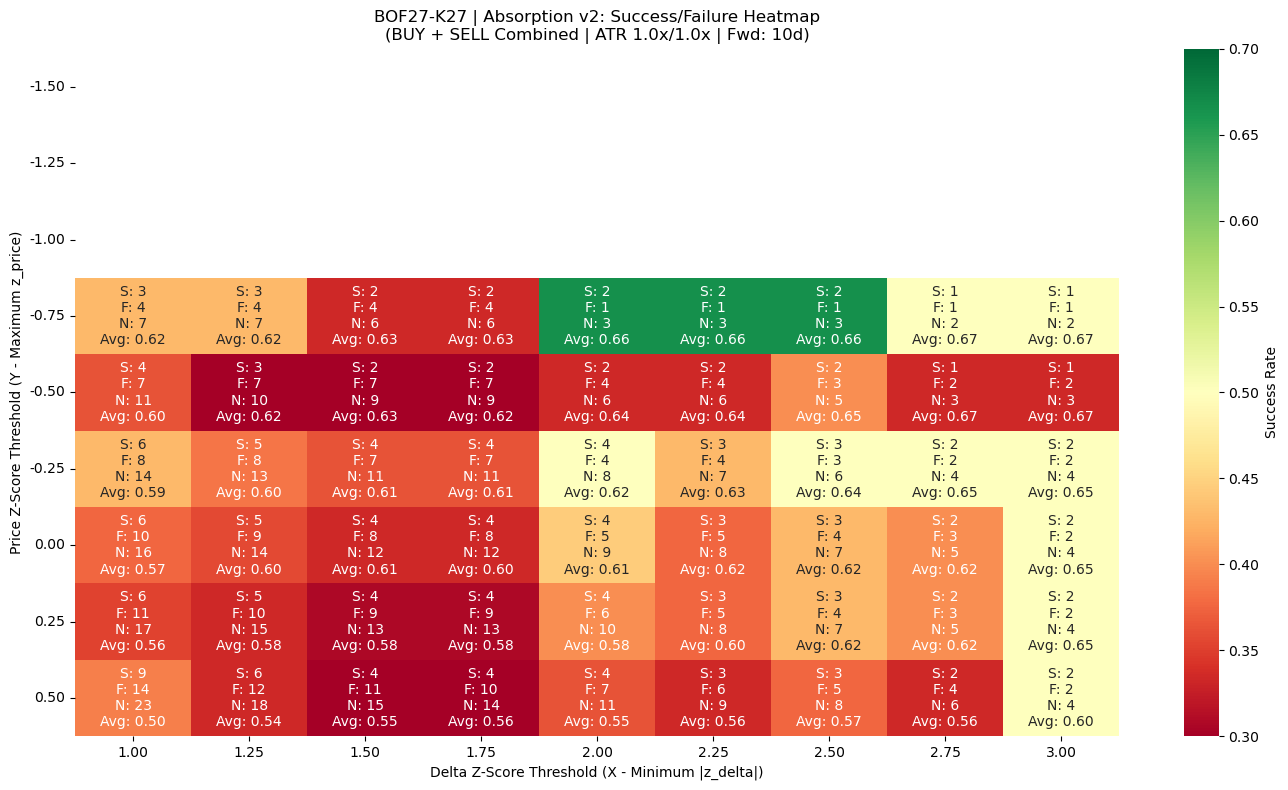

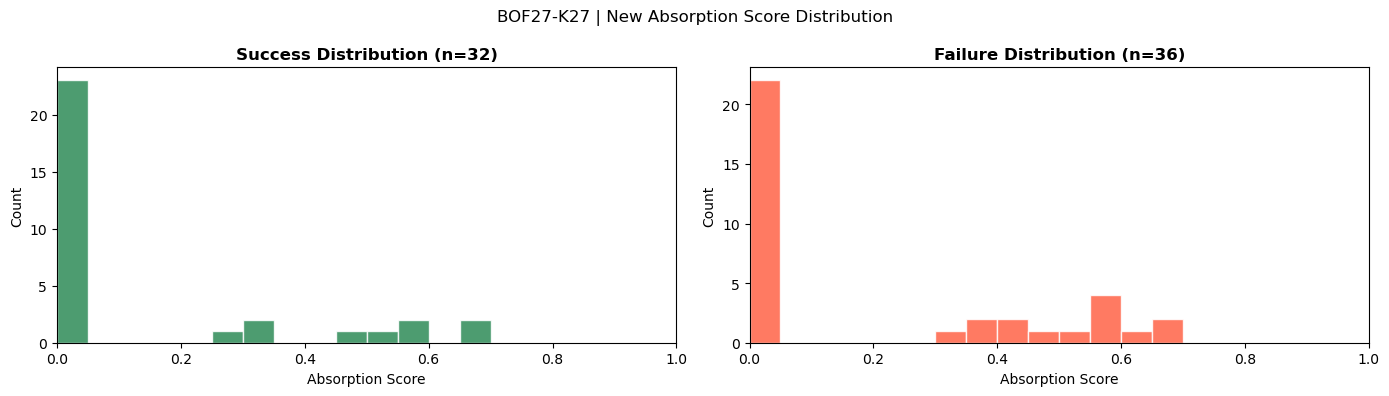


Score summary:
Successful signals : 32
Failed signals     : 36
Mean success score : 0.136
Mean failure score : 0.201




In [7]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import project modules
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr


# ==============================================================================
# 1. PARAMETERS
# ==============================================================================

product_code = "BO"
months_back = 6
front_n = 5


# ------------------------------------------------------------------------------
# Heatmap grids
# ------------------------------------------------------------------------------
# X = minimum |z_delta| required
delta_z_grid = np.arange(1.0, 3.25, 0.25)

# Y = maximum z_price allowed
#
# IMPORTANT:
# z_price is based on ABSOLUTE price response.
#
# Therefore:
#     lower z_price = smaller-than-usual price movement
#                    = stronger absorption
#
price_z_grid = np.arange(0.5, -1.75, -0.25)


# ------------------------------------------------------------------------------
# Scorer parameters
# ------------------------------------------------------------------------------
#
# These are used only for calculating the causal z-scores and the
# continuous absorption_score.
#
v2_params = {
    "volume_window": 5,
    "atr_window": 5,
    "baseline_window": 30,
}


# ------------------------------------------------------------------------------
# ATR labeling parameters
# ------------------------------------------------------------------------------
atr_period = 10
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10


# ==============================================================================
# 2. FETCH DATE RANGE
# ==============================================================================

start_date = (
    pd.Timestamp.now() - pd.DateOffset(months=months_back)
).strftime("%Y-%m-%d")

end_date = pd.Timestamp.now().strftime("%Y-%m-%d")


# ==============================================================================
# 3. GET ALL FRONT INSTRUMENTS
# ==============================================================================

instruments = []

for insts in get_all_front_instruments(
    product_code,
    reference_date=None,
    front_n=front_n
).values():
    instruments.extend(insts)


print(
    f"Generating independent heatmaps & distributions "
    f"for {len(instruments)} instruments. Please wait...\n"
)


# ==============================================================================
# 4. PROCESS EACH INSTRUMENT
# ==============================================================================

for inst in instruments:

    print(f"Processing {inst}...")


    # --------------------------------------------------------------------------
    # 4.1 Fetch OHLC
    # --------------------------------------------------------------------------

    df = fetch_ohlc_1d(
        inst,
        product_code,
        getData_OHLC_v2,
        start_date,
        end_date
    )

    if df is None or len(df) < 30:
        print(f"Skipping {inst} (insufficient data)")
        continue


    # --------------------------------------------------------------------------
    # 4.2 Calculate absorption features + continuous score
    # --------------------------------------------------------------------------

    #
    # IMPORTANT:
    #
    # delta_z_threshold and price_z_threshold are used ONLY for defining
    # absorption_direction inside calculate_absorption_v2.
    #
    # The continuous absorption_score itself is NOT dependent on these
    # thresholds anymore.
    #
    df = calculate_absorption_v2(
        df,
        volume_window=v2_params["volume_window"],
        atr_window=v2_params["atr_window"],
        baseline_window=v2_params["baseline_window"],

        # Used only to determine the native BUY / SELL direction
        delta_z_threshold=0,
        price_z_threshold=0.5,
    )


    # --------------------------------------------------------------------------
    # 4.3 Save the real direction
    # --------------------------------------------------------------------------

    real_direction = df["absorption_direction"].copy()


    # ==========================================================================
    # 5. LABEL EVERY BAR AS BUY
    # ==========================================================================

    #
    # We deliberately force BUY so that the labeler evaluates every possible
    # BUY setup. The heatmap mask later decides which observations qualify.
    #

    df["absorption_direction"] = "BUY"

    df_buy = label_absorption_atr(
        df,
        atr_period=atr_period,
        target_atr_mult=target_atr_mult,
        stop_atr_mult=stop_atr_mult,
        forward_days=forward_days
    )


    # ==========================================================================
    # 6. LABEL EVERY BAR AS SELL
    # ==========================================================================

    df["absorption_direction"] = "SELL"

    df_sell = label_absorption_atr(
        df,
        atr_period=atr_period,
        target_atr_mult=target_atr_mult,
        stop_atr_mult=stop_atr_mult,
        forward_days=forward_days
    )


    # --------------------------------------------------------------------------
    # Restore the actual BUY / SELL / NEUTRAL direction
    # --------------------------------------------------------------------------

    df["absorption_direction"] = real_direction


    # ==========================================================================
    # 7. HEATMAP MATRICES
    # ==========================================================================

    n_price = len(price_z_grid)
    n_delta = len(delta_z_grid)

    heat_rate = np.full(
        (n_price, n_delta),
        np.nan
    )

    annot_labels = np.empty(
        (n_price, n_delta),
        dtype=object
    )


    # ==========================================================================
    # 8. TEST EVERY (DELTA Z, PRICE Z) THRESHOLD COMBINATION
    # ==========================================================================

    for i, pz in enumerate(price_z_grid):

        for j, dz in enumerate(delta_z_grid):


            # ------------------------------------------------------------------
            # BUY absorption
            #
            # Large positive delta
            # + small absolute price movement
            # ------------------------------------------------------------------

            buy_mask = (
                (df["z_delta"] >= dz) &
                (df["z_price"] <= pz)
            )


            # ------------------------------------------------------------------
            # SELL absorption
            #
            # Large negative delta
            # + small absolute price movement
            # ------------------------------------------------------------------

            sell_mask = (
                (df["z_delta"] <= -dz) &
                (df["z_price"] <= pz)
            )


            # ------------------------------------------------------------------
            # Combined mask
            # ------------------------------------------------------------------

            combined_mask = buy_mask | sell_mask


            # ------------------------------------------------------------------
            # Average NEW absorption score for this cell
            #
            # IMPORTANT:
            #
            # We do NOT recalculate the score using dz/pz.
            #
            # absorption_score is now a continuous intrinsic score:
            #
            #     delta_strength × price_suppression
            #
            # The heatmap thresholds only decide which observations belong
            # to this cell.
            # ------------------------------------------------------------------

            if combined_mask.sum() > 0:

                avg_score = df.loc[
                    combined_mask,
                    "absorption_score"
                ].mean()

            else:

                avg_score = np.nan


            # ==================================================================
            # OUTCOME CALCULATION
            # ==================================================================

            # BUY outcomes
            buy_succ = (
                df_buy.loc[
                    buy_mask,
                    "sl_success"
                ] == 1.0
            ).sum()

            buy_fail = (
                df_buy.loc[
                    buy_mask,
                    "sl_success"
                ] == 0.0
            ).sum()


            # SELL outcomes
            sell_succ = (
                df_sell.loc[
                    sell_mask,
                    "sl_success"
                ] == 1.0
            ).sum()

            sell_fail = (
                df_sell.loc[
                    sell_mask,
                    "sl_success"
                ] == 0.0
            ).sum()


            # ------------------------------------------------------------------
            # Combine BUY + SELL
            # ------------------------------------------------------------------

            tot_succ = buy_succ + sell_succ
            tot_fail = buy_fail + sell_fail

            tot_valid = tot_succ + tot_fail


            # ------------------------------------------------------------------
            # Success rate + annotation
            # ------------------------------------------------------------------

            if tot_valid > 0:

                heat_rate[i, j] = (
                    tot_succ / tot_valid
                )

                annot_labels[i, j] = (
                    f"S: {tot_succ}\n"
                    f"F: {tot_fail}\n"
                    f"N: {tot_valid}\n"
                    f"Avg: {avg_score:.2f}"
                )

            else:

                heat_rate[i, j] = np.nan

                annot_labels[i, j] = "N/A"


    # ==========================================================================
    # 9. PLOT HEATMAP
    # ==========================================================================

    plt.figure(figsize=(14, 8))

    ax = sns.heatmap(
        heat_rate,
        annot=annot_labels,
        fmt="",
        cmap="RdYlGn",
        vmin=0.30,
        vmax=0.70,
        cbar_kws={
            "label": "Success Rate"
        }
    )


    ax.set_xticklabels(
        [f"{dz:.2f}" for dz in delta_z_grid]
    )

    ax.set_yticklabels(
        [f"{pz:.2f}" for pz in price_z_grid],
        rotation=0
    )


    # Keep smaller price threshold at bottom
    ax.invert_yaxis()


    plt.xlabel(
        "Delta Z-Score Threshold (X - Minimum |z_delta|)"
    )

    plt.ylabel(
        "Price Z-Score Threshold (Y - Maximum z_price)"
    )

    plt.title(
        f"{inst} | Absorption v2: Success/Failure Heatmap\n"
        f"(BUY + SELL Combined | "
        f"ATR {target_atr_mult}x/{stop_atr_mult}x | "
        f"Fwd: {forward_days}d)"
    )

    plt.tight_layout()
    plt.show()


    # ==========================================================================
    # 10. SCORE DISTRIBUTION
    # ==========================================================================

    #
    # Use the REAL direction generated by calculate_absorption_v2.
    #
    # BUY bars get BUY outcomes.
    # SELL bars get SELL outcomes.
    #
    # NEUTRAL bars are ignored.
    #

    dist_buy_mask = (
        df["absorption_direction"] == "BUY"
    )

    dist_sell_mask = (
        df["absorption_direction"] == "SELL"
    )


    # --------------------------------------------------------------------------
    # Create final outcome column
    # --------------------------------------------------------------------------

    df["final_success"] = np.nan


    df.loc[
        dist_buy_mask,
        "final_success"
    ] = df_buy.loc[
        dist_buy_mask,
        "sl_success"
    ]


    df.loc[
        dist_sell_mask,
        "final_success"
    ] = df_sell.loc[
        dist_sell_mask,
        "sl_success"
    ]


    # Only observations where an outcome is available
    valid_dist = df.dropna(
        subset=["final_success"]
    )


    # ==========================================================================
    # 11. PLOT SUCCESS VS FAILURE SCORE DISTRIBUTION
    # ==========================================================================

    if len(valid_dist) > 0:

        s_scores = valid_dist.loc[
            valid_dist["final_success"] == 1.0,
            "absorption_score"
        ]

        f_scores = valid_dist.loc[
            valid_dist["final_success"] == 0.0,
            "absorption_score"
        ]


        # Score is [0,1]
        bins = np.arange(
            0,
            1.05,
            0.05
        )


        fig, (ax1, ax2) = plt.subplots(
            1,
            2,
            figsize=(14, 4)
        )


        # ----------------------------------------------------------------------
        # SUCCESS
        # ----------------------------------------------------------------------

        ax1.hist(
            s_scores,
            bins=bins,
            color="seagreen",
            edgecolor="white",
            alpha=0.85
        )

        ax1.set_title(
            f"Success Distribution (n={len(s_scores)})",
            fontweight="bold"
        )

        ax1.set_xlabel(
            "Absorption Score"
        )

        ax1.set_ylabel(
            "Count"
        )

        ax1.set_xlim(
            [0, 1]
        )


        # ----------------------------------------------------------------------
        # FAILURE
        # ----------------------------------------------------------------------

        ax2.hist(
            f_scores,
            bins=bins,
            color="tomato",
            edgecolor="white",
            alpha=0.85
        )

        ax2.set_title(
            f"Failure Distribution (n={len(f_scores)})",
            fontweight="bold"
        )

        ax2.set_xlabel(
            "Absorption Score"
        )

        ax2.set_ylabel(
            "Count"
        )

        ax2.set_xlim(
            [0, 1]
        )


        plt.suptitle(
            f"{inst} | New Absorption Score Distribution"
        )

        plt.tight_layout()
        plt.show()


        # ======================================================================
        # 12. OPTIONAL: SCORE SUMMARY
        # ======================================================================

        print("\nScore summary:")

        print(
            f"Successful signals : {len(s_scores)}"
        )

        print(
            f"Failed signals     : {len(f_scores)}"
        )

        if len(s_scores) > 0:
            print(
                f"Mean success score : {s_scores.mean():.3f}"
            )

        if len(f_scores) > 0:
            print(
                f"Mean failure score : {f_scores.mean():.3f}"
            )


    else:

        print(
            f"No valid BUY/SELL outcomes for {inst}."
        )


    print(
        "\n" + "=" * 80 + "\n"
    )

Generating independent heatmaps & distributions for 10 instruments. Please wait...

Processing SMV26-Z26...


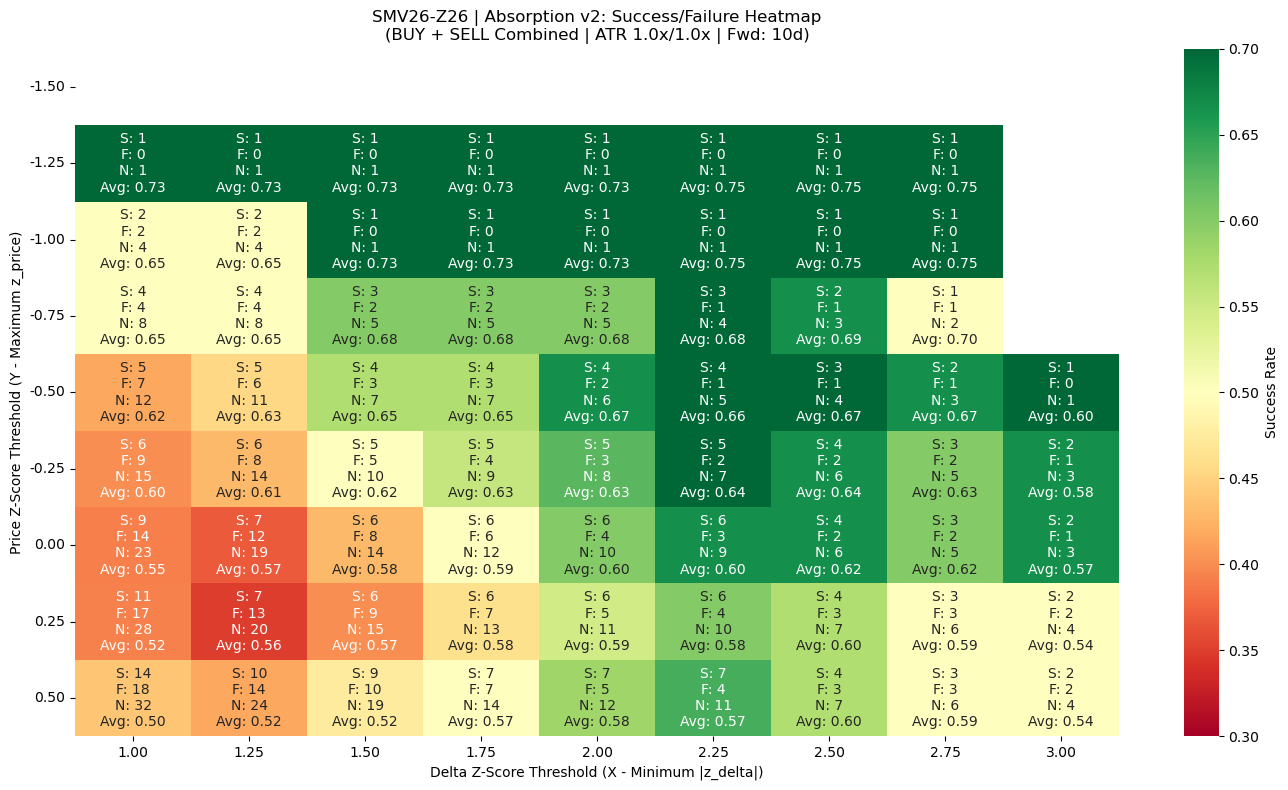

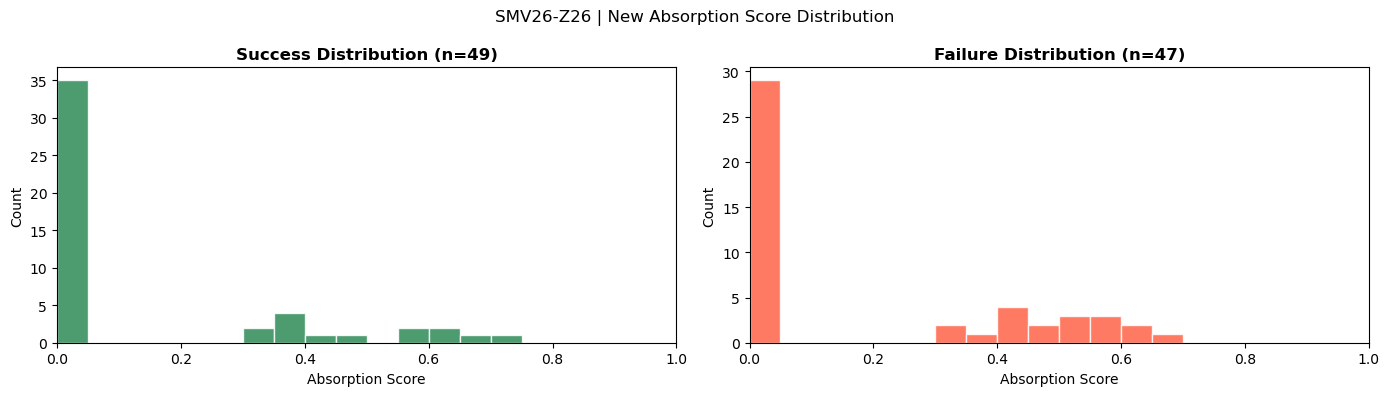


Score summary:
Successful signals : 49
Failed signals     : 47
Mean success score : 0.141
Mean failure score : 0.190


Processing SMZ26-F27...


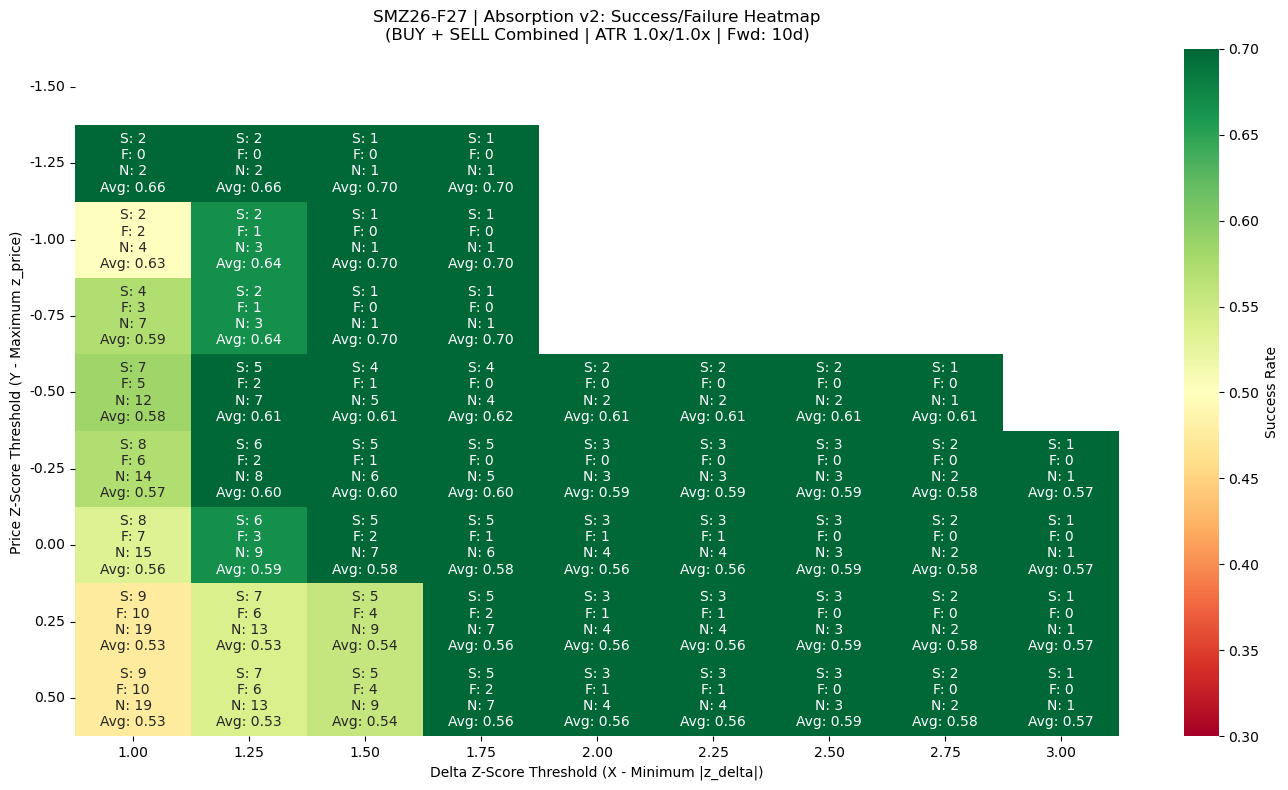

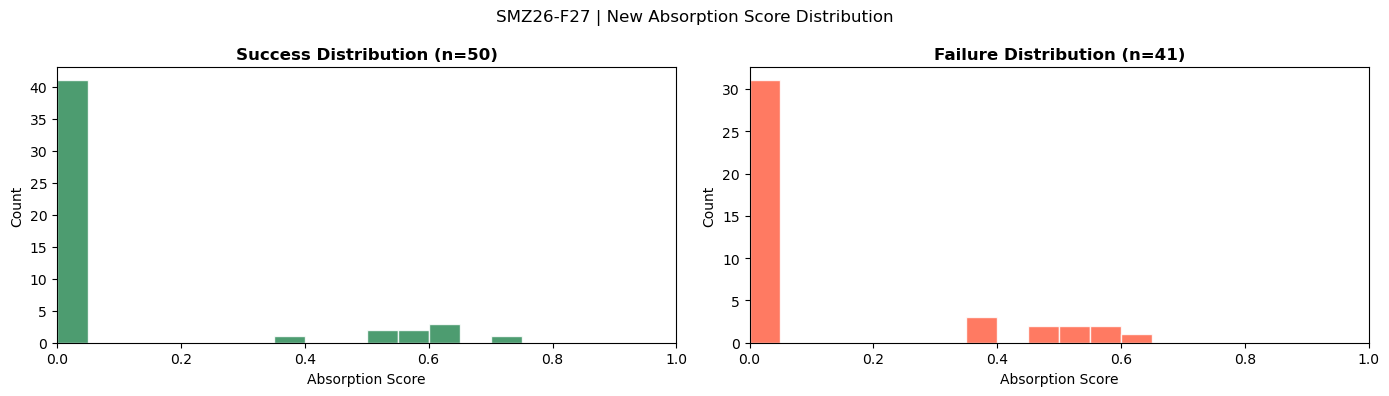


Score summary:
Successful signals : 50
Failed signals     : 41
Mean success score : 0.102
Mean failure score : 0.119


Processing SMF27-H27...


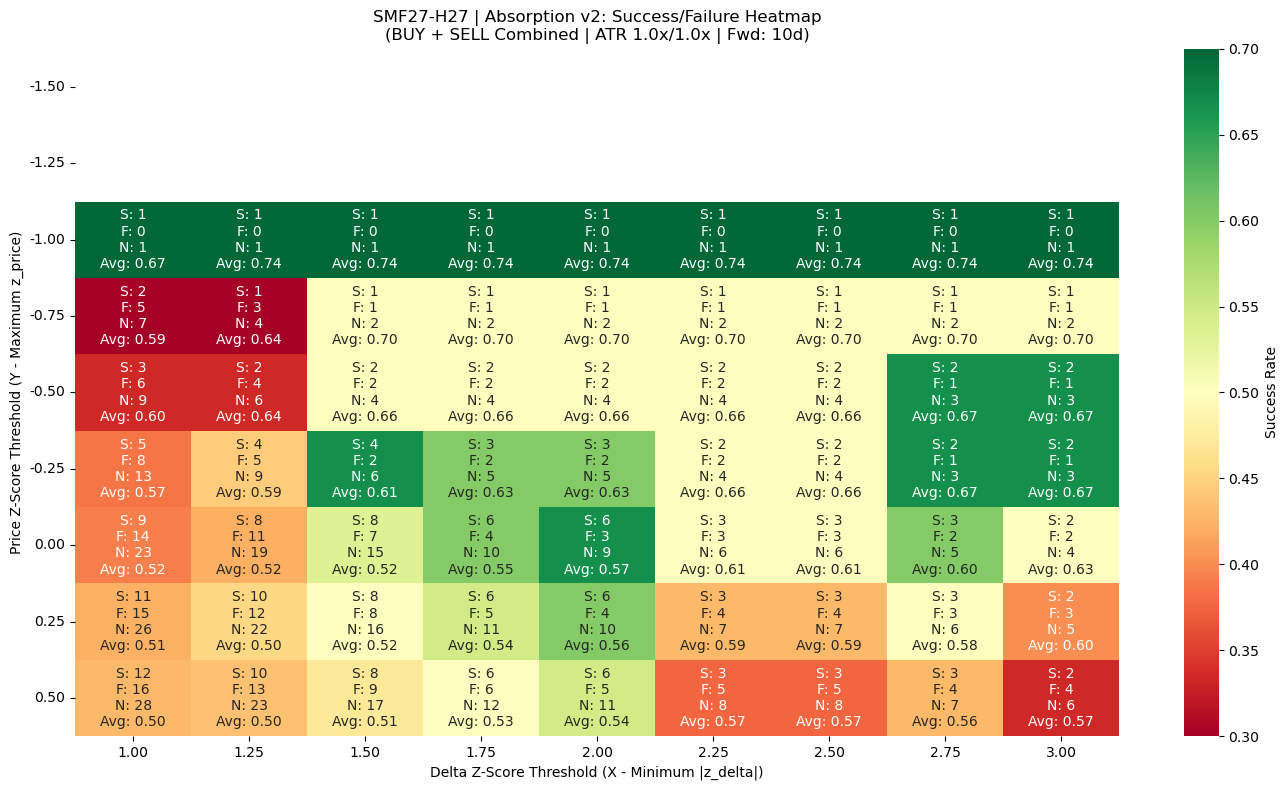

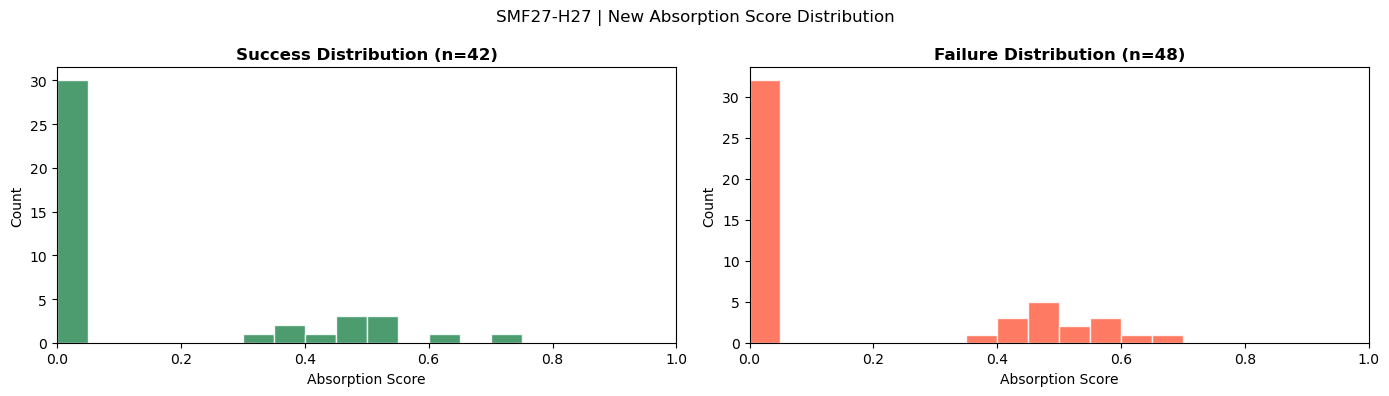


Score summary:
Successful signals : 42
Failed signals     : 48
Mean success score : 0.138
Mean failure score : 0.169


Processing SMH27-K27...


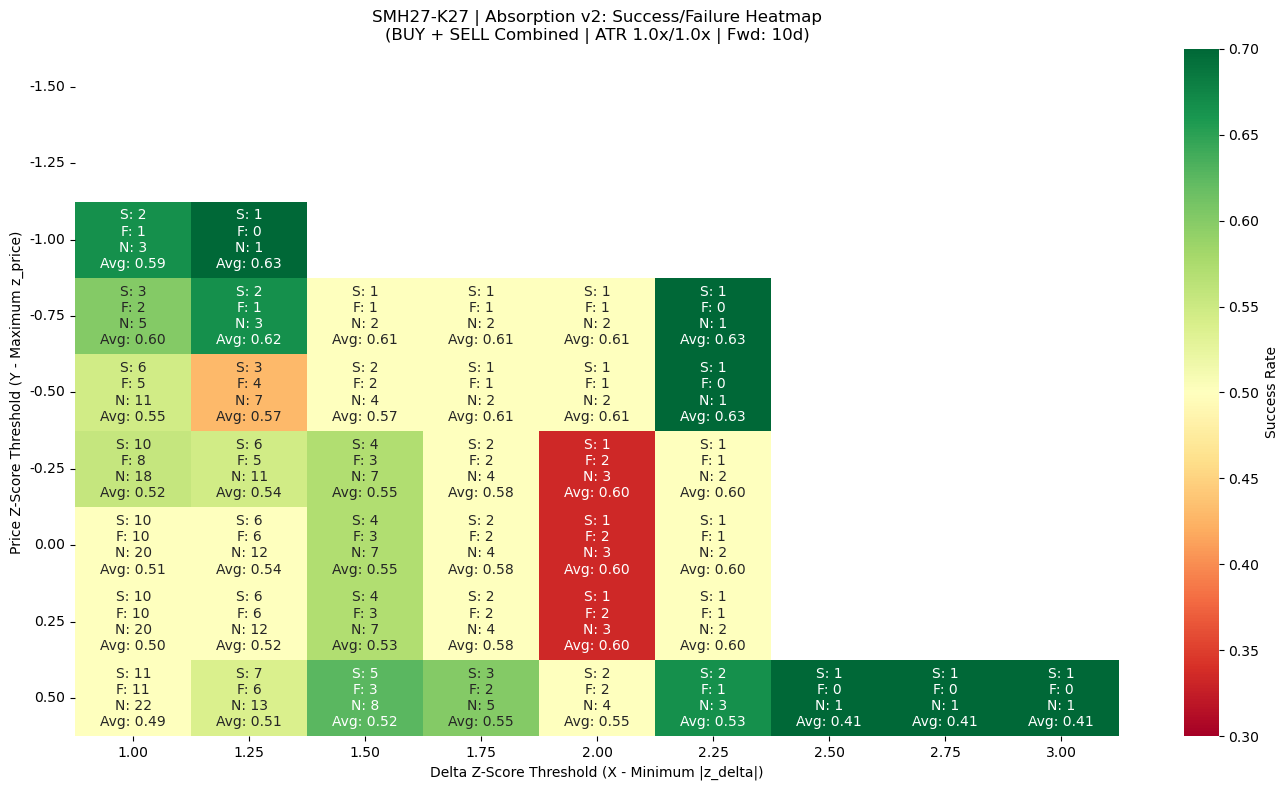

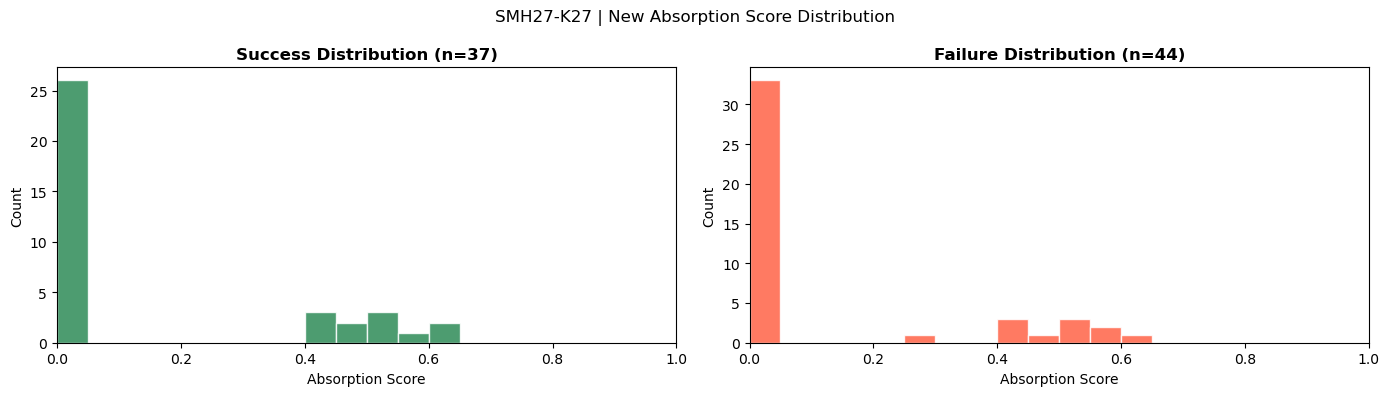


Score summary:
Successful signals : 37
Failed signals     : 44
Mean success score : 0.152
Mean failure score : 0.121


Processing SMK27-N27...


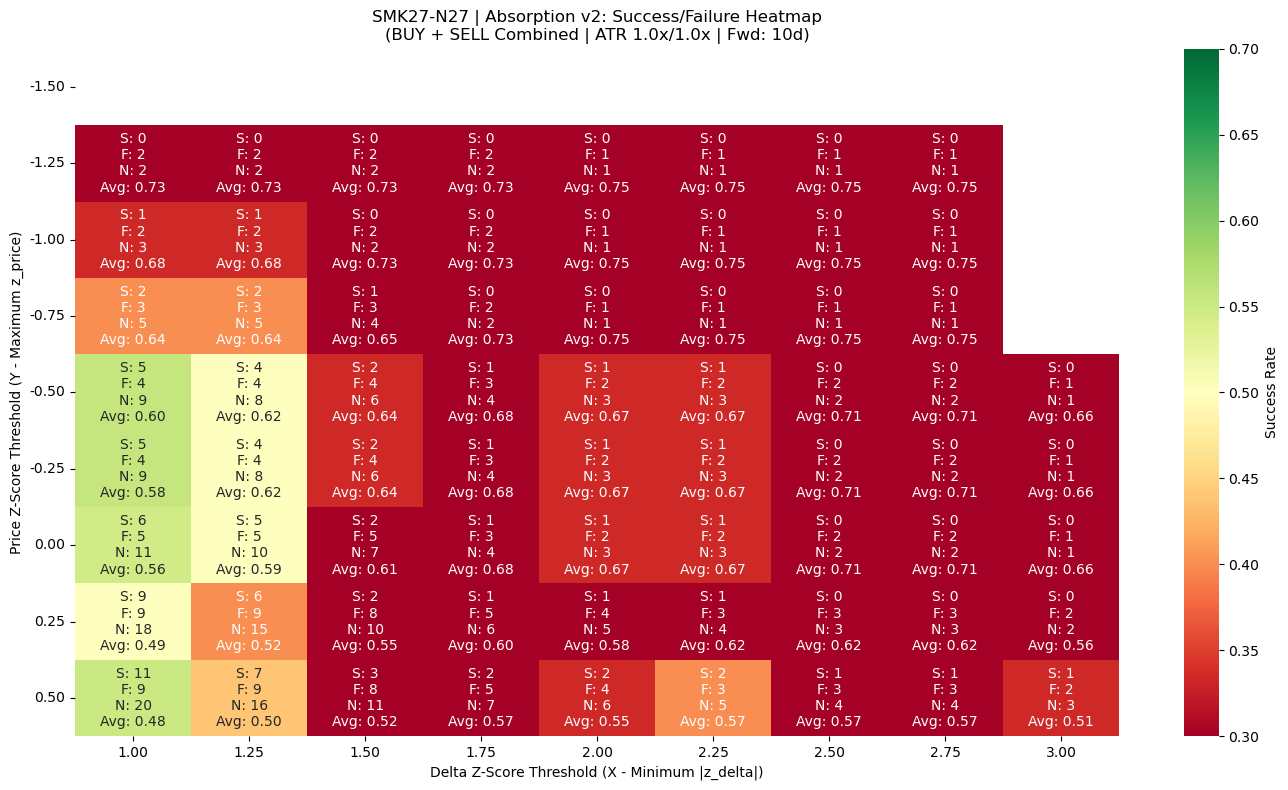

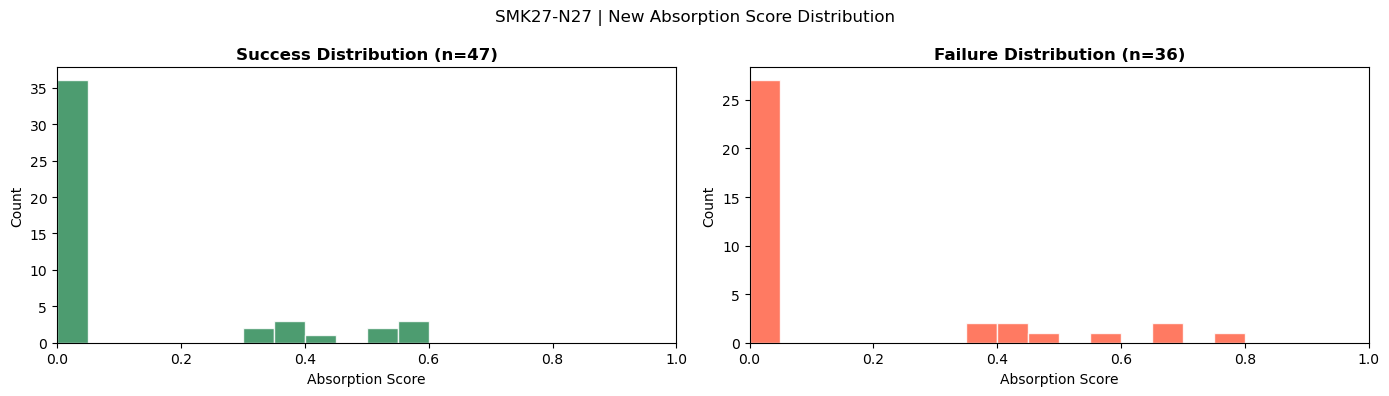


Score summary:
Successful signals : 47
Failed signals     : 36
Mean success score : 0.106
Mean failure score : 0.132


Processing SMV26-F27...


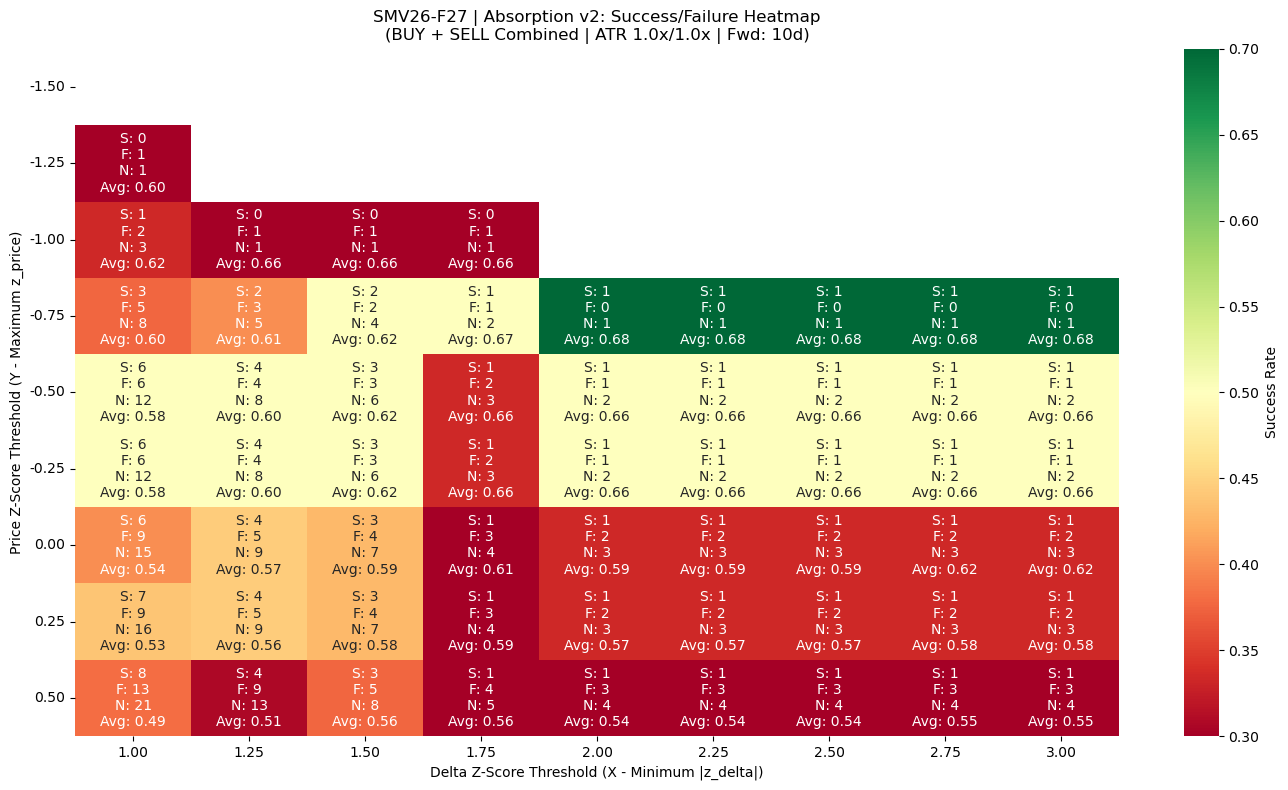

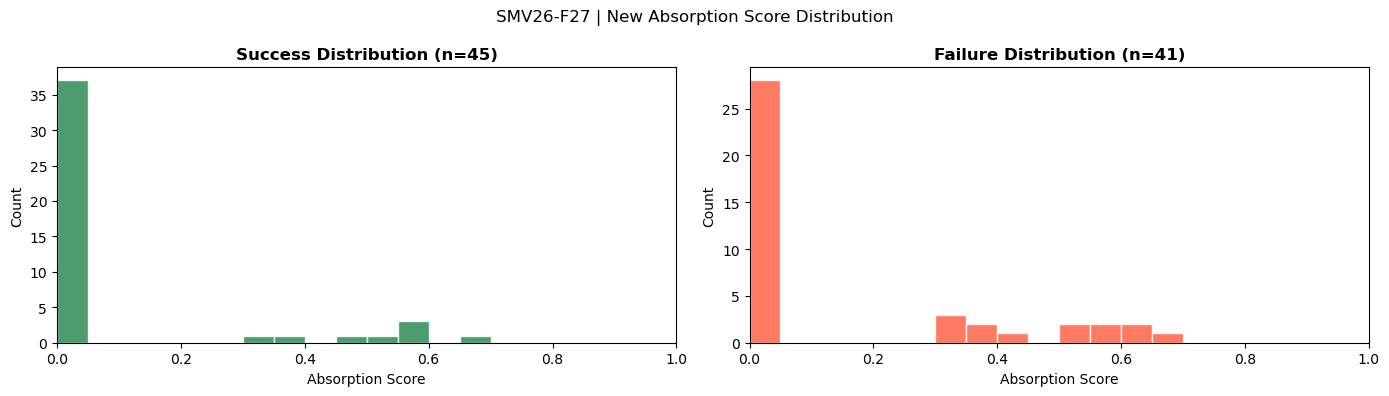


Score summary:
Successful signals : 45
Failed signals     : 41
Mean success score : 0.090
Mean failure score : 0.153


Processing SMV26-H27...


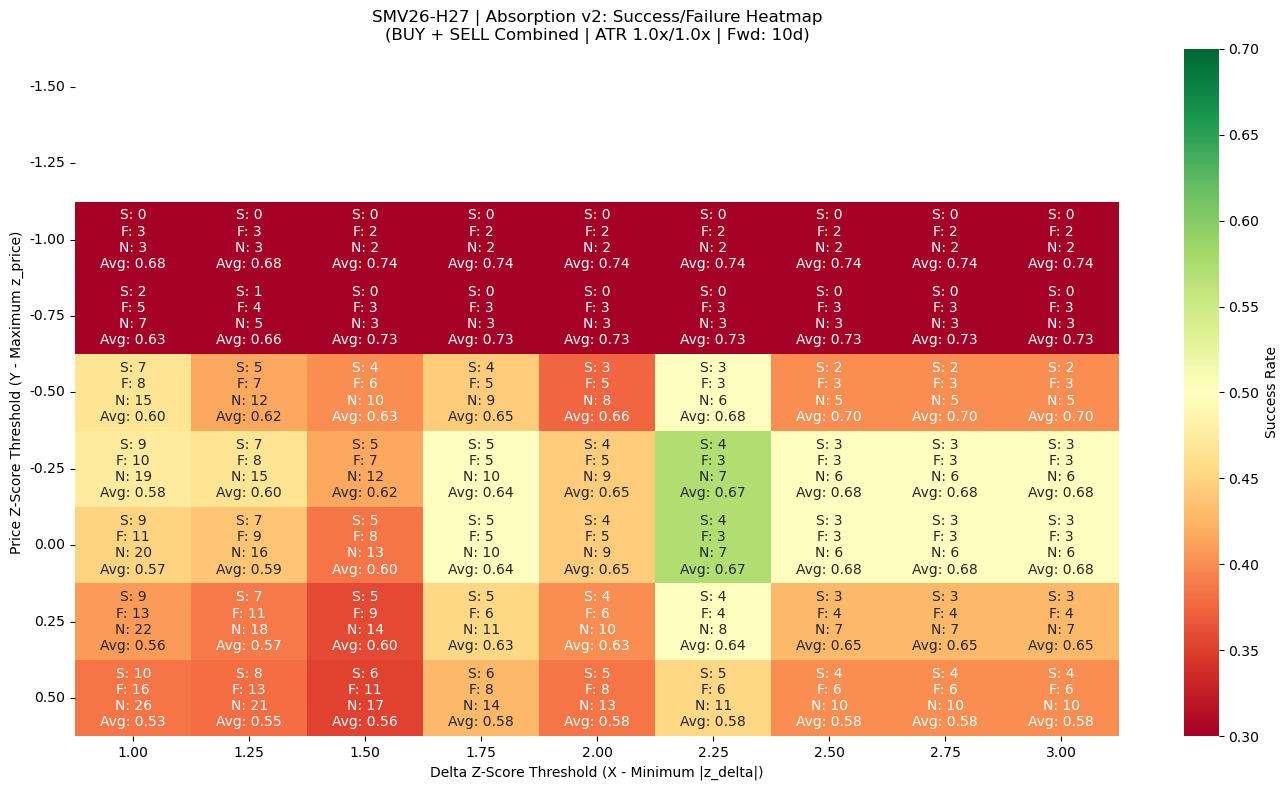

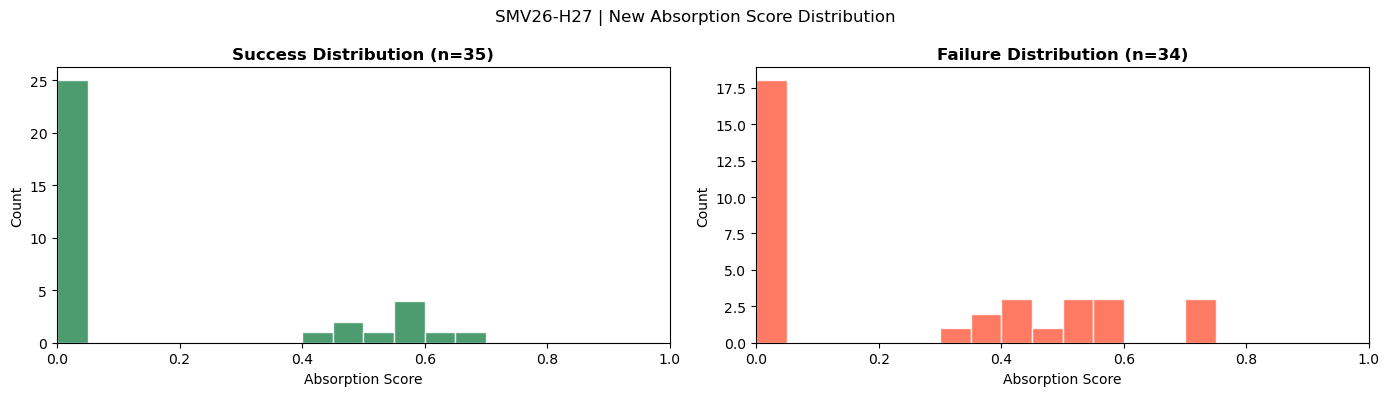


Score summary:
Successful signals : 35
Failed signals     : 34
Mean success score : 0.158
Mean failure score : 0.246


Processing SMZ26-H27...


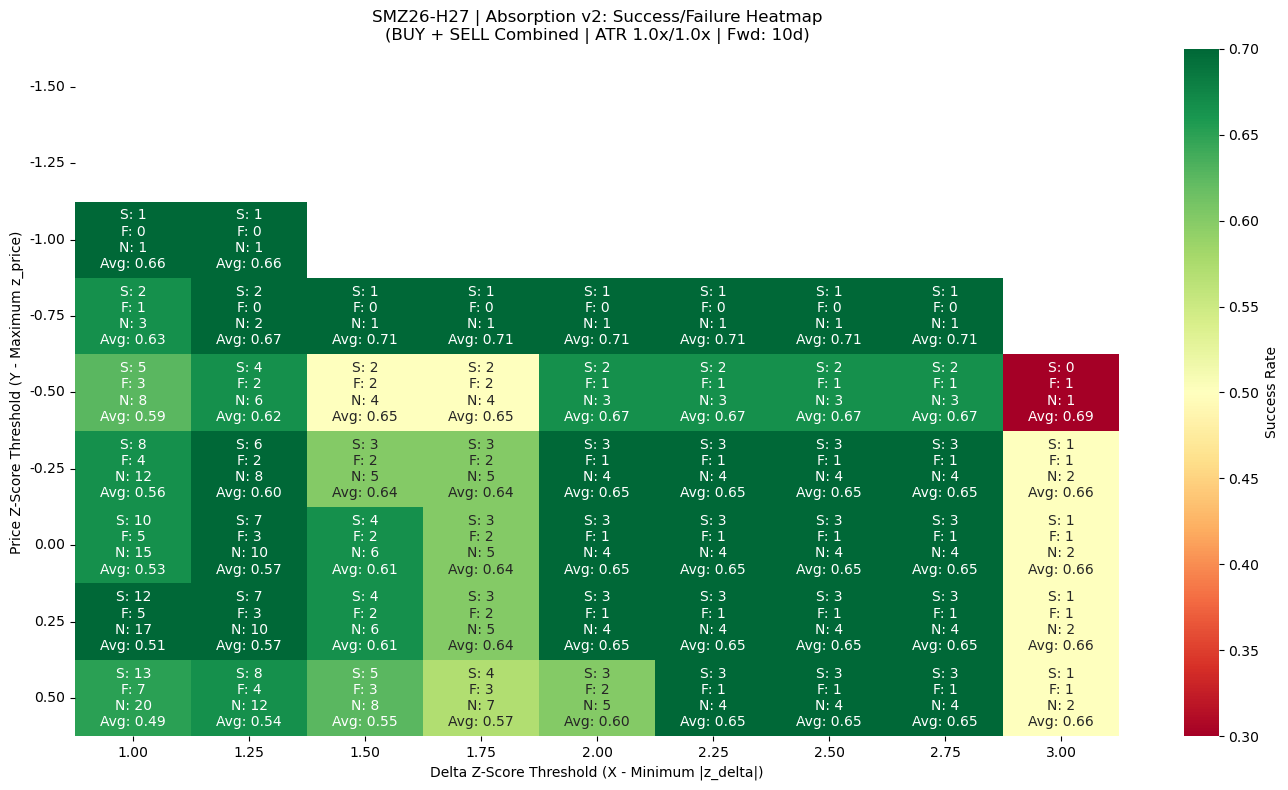

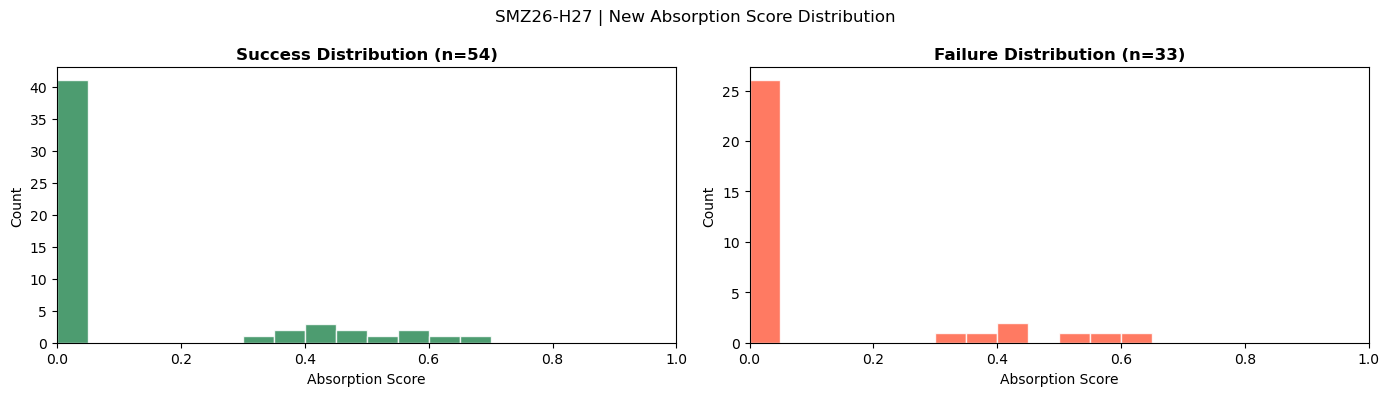


Score summary:
Successful signals : 54
Failed signals     : 33
Mean success score : 0.117
Mean failure score : 0.099


Processing SMZ26-K27...


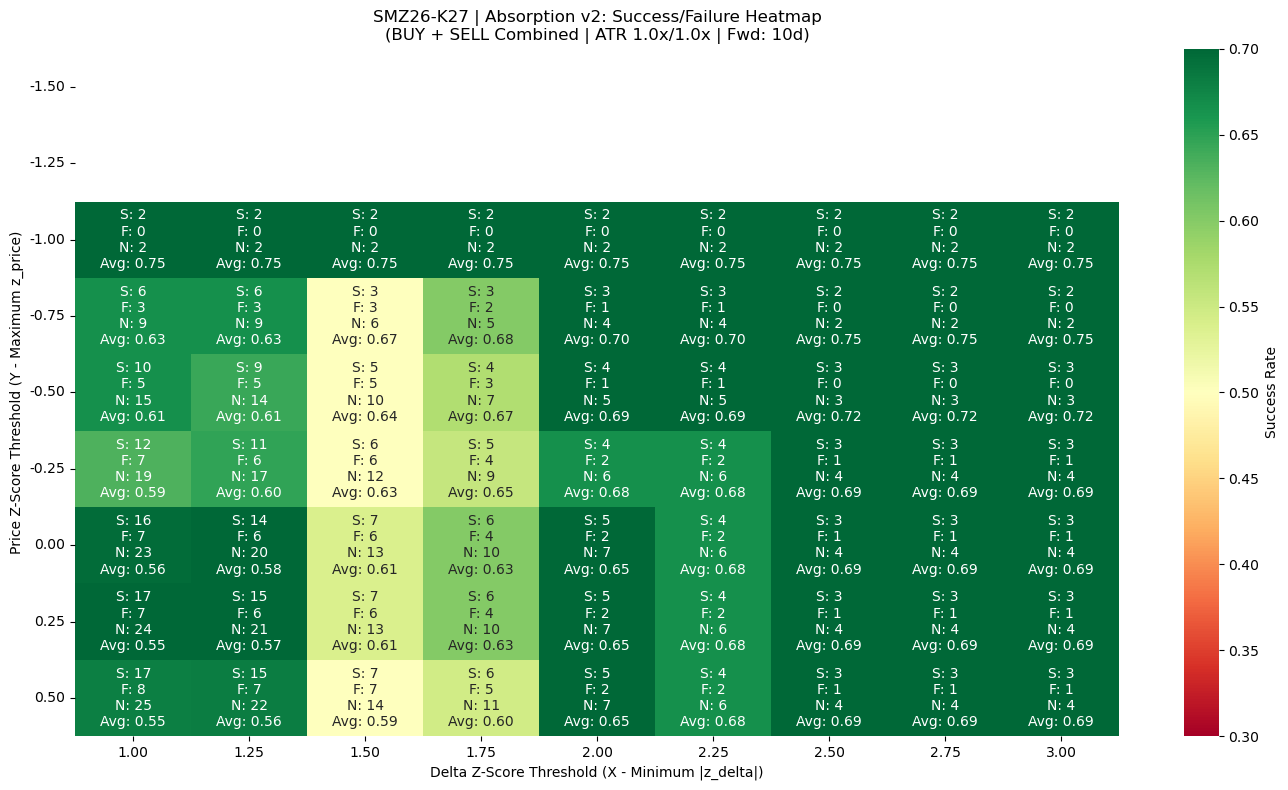

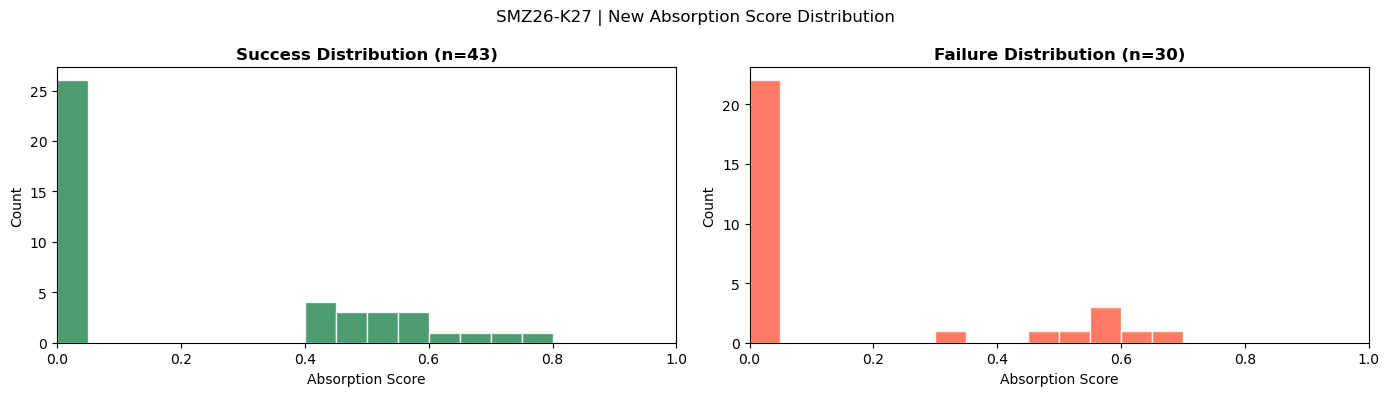


Score summary:
Successful signals : 43
Failed signals     : 30
Mean success score : 0.214
Mean failure score : 0.147


Processing SMF27-K27...


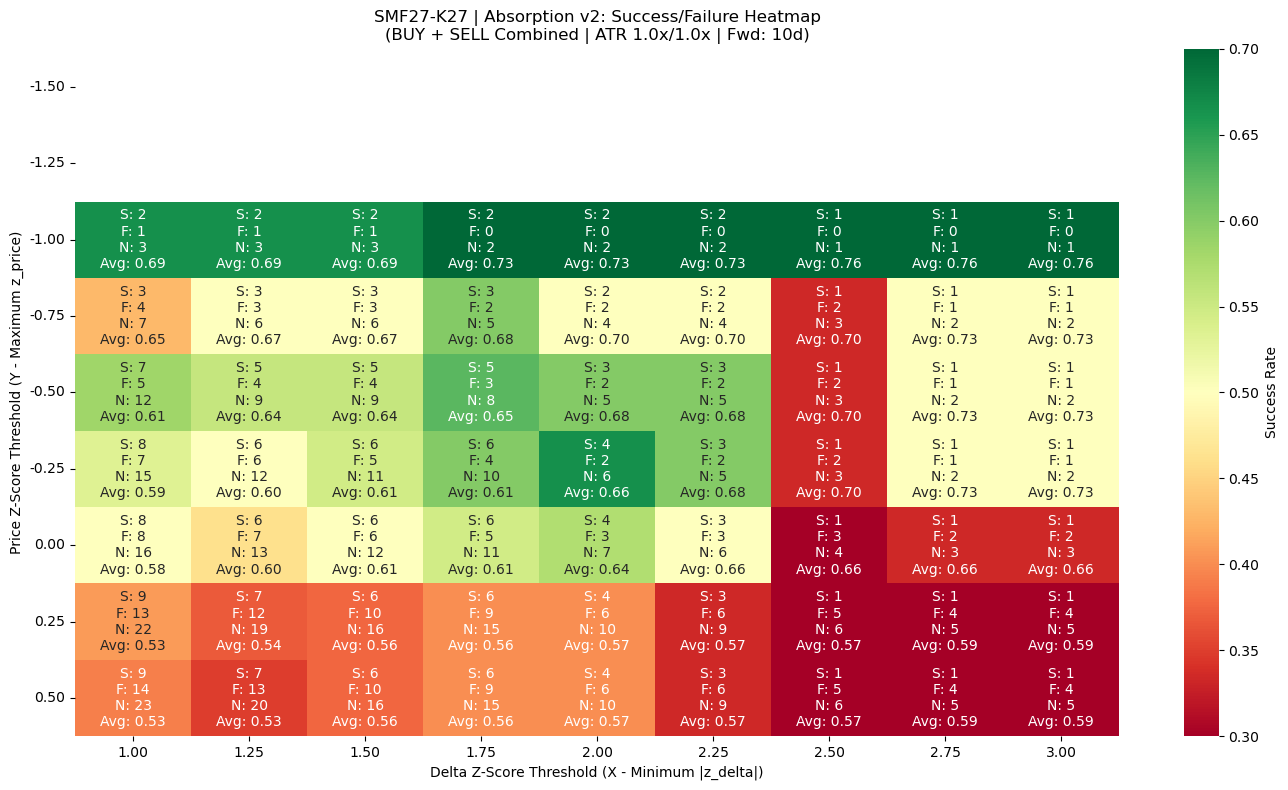

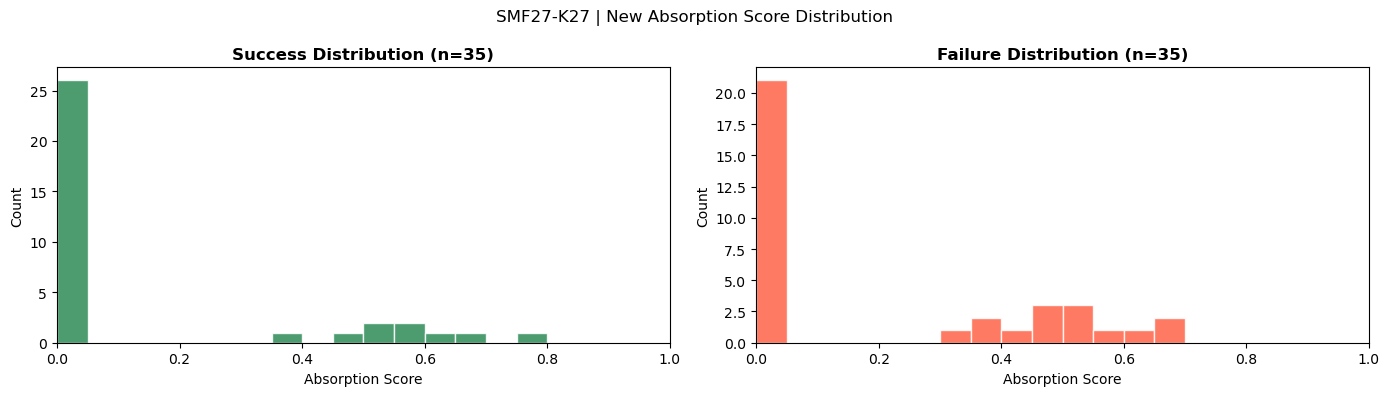


Score summary:
Successful signals : 35
Failed signals     : 35
Mean success score : 0.147
Mean failure score : 0.202




In [8]:
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import project modules
from market_analysis.data.ohlc import fetch_ohlc_1d, getData_OHLC_v2
from market_analysis.utils.contracts import get_all_front_instruments
from market_analysis.signals.absorption.calculate_v2 import calculate_absorption_v2
from market_analysis.signals.absorption.label import label_absorption_atr


# ==============================================================================
# 1. PARAMETERS
# ==============================================================================

product_code = "SM"
months_back = 6
front_n = 5


# ------------------------------------------------------------------------------
# Heatmap grids
# ------------------------------------------------------------------------------
# X = minimum |z_delta| required
delta_z_grid = np.arange(1.0, 3.25, 0.25)

# Y = maximum z_price allowed
#
# IMPORTANT:
# z_price is based on ABSOLUTE price response.
#
# Therefore:
#     lower z_price = smaller-than-usual price movement
#                    = stronger absorption
#
price_z_grid = np.arange(0.5, -1.75, -0.25)


# ------------------------------------------------------------------------------
# Scorer parameters
# ------------------------------------------------------------------------------
#
# These are used only for calculating the causal z-scores and the
# continuous absorption_score.
#
v2_params = {
    "volume_window": 10,
    "atr_window": 10,
    "baseline_window": 30,
}


# ------------------------------------------------------------------------------
# ATR labeling parameters
# ------------------------------------------------------------------------------
atr_period = 10
target_atr_mult = 1.0
stop_atr_mult = 1.0
forward_days = 10


# ==============================================================================
# 2. FETCH DATE RANGE
# ==============================================================================

start_date = (
    pd.Timestamp.now() - pd.DateOffset(months=months_back)
).strftime("%Y-%m-%d")

end_date = pd.Timestamp.now().strftime("%Y-%m-%d")


# ==============================================================================
# 3. GET ALL FRONT INSTRUMENTS
# ==============================================================================

instruments = []

for insts in get_all_front_instruments(
    product_code,
    reference_date=None,
    front_n=front_n
).values():
    instruments.extend(insts)


print(
    f"Generating independent heatmaps & distributions "
    f"for {len(instruments)} instruments. Please wait...\n"
)


# ==============================================================================
# 4. PROCESS EACH INSTRUMENT
# ==============================================================================

for inst in instruments:

    print(f"Processing {inst}...")


    # --------------------------------------------------------------------------
    # 4.1 Fetch OHLC
    # --------------------------------------------------------------------------

    df = fetch_ohlc_1d(
        inst,
        product_code,
        getData_OHLC_v2,
        start_date,
        end_date
    )

    if df is None or len(df) < 30:
        print(f"Skipping {inst} (insufficient data)")
        continue


    # --------------------------------------------------------------------------
    # 4.2 Calculate absorption features + continuous score
    # --------------------------------------------------------------------------

    #
    # IMPORTANT:
    #
    # delta_z_threshold and price_z_threshold are used ONLY for defining
    # absorption_direction inside calculate_absorption_v2.
    #
    # The continuous absorption_score itself is NOT dependent on these
    # thresholds anymore.
    #
    df = calculate_absorption_v2(
        df,
        volume_window=v2_params["volume_window"],
        atr_window=v2_params["atr_window"],
        baseline_window=v2_params["baseline_window"],

        # Used only to determine the native BUY / SELL direction
        delta_z_threshold=0,
        price_z_threshold=0.5,
    )


    # --------------------------------------------------------------------------
    # 4.3 Save the real direction
    # --------------------------------------------------------------------------

    real_direction = df["absorption_direction"].copy()


    # ==========================================================================
    # 5. LABEL EVERY BAR AS BUY
    # ==========================================================================

    #
    # We deliberately force BUY so that the labeler evaluates every possible
    # BUY setup. The heatmap mask later decides which observations qualify.
    #

    df["absorption_direction"] = "BUY"

    df_buy = label_absorption_atr(
        df,
        atr_period=atr_period,
        target_atr_mult=target_atr_mult,
        stop_atr_mult=stop_atr_mult,
        forward_days=forward_days
    )


    # ==========================================================================
    # 6. LABEL EVERY BAR AS SELL
    # ==========================================================================

    df["absorption_direction"] = "SELL"

    df_sell = label_absorption_atr(
        df,
        atr_period=atr_period,
        target_atr_mult=target_atr_mult,
        stop_atr_mult=stop_atr_mult,
        forward_days=forward_days
    )


    # --------------------------------------------------------------------------
    # Restore the actual BUY / SELL / NEUTRAL direction
    # --------------------------------------------------------------------------

    df["absorption_direction"] = real_direction


    # ==========================================================================
    # 7. HEATMAP MATRICES
    # ==========================================================================

    n_price = len(price_z_grid)
    n_delta = len(delta_z_grid)

    heat_rate = np.full(
        (n_price, n_delta),
        np.nan
    )

    annot_labels = np.empty(
        (n_price, n_delta),
        dtype=object
    )


    # ==========================================================================
    # 8. TEST EVERY (DELTA Z, PRICE Z) THRESHOLD COMBINATION
    # ==========================================================================

    for i, pz in enumerate(price_z_grid):

        for j, dz in enumerate(delta_z_grid):


            # ------------------------------------------------------------------
            # BUY absorption
            #
            # Large positive delta
            # + small absolute price movement
            # ------------------------------------------------------------------

            buy_mask = (
                (df["z_delta"] >= dz) &
                (df["z_price"] <= pz)
            )


            # ------------------------------------------------------------------
            # SELL absorption
            #
            # Large negative delta
            # + small absolute price movement
            # ------------------------------------------------------------------

            sell_mask = (
                (df["z_delta"] <= -dz) &
                (df["z_price"] <= pz)
            )


            # ------------------------------------------------------------------
            # Combined mask
            # ------------------------------------------------------------------

            combined_mask = buy_mask | sell_mask


            # ------------------------------------------------------------------
            # Average NEW absorption score for this cell
            #
            # IMPORTANT:
            #
            # We do NOT recalculate the score using dz/pz.
            #
            # absorption_score is now a continuous intrinsic score:
            #
            #     delta_strength × price_suppression
            #
            # The heatmap thresholds only decide which observations belong
            # to this cell.
            # ------------------------------------------------------------------

            if combined_mask.sum() > 0:

                avg_score = df.loc[
                    combined_mask,
                    "absorption_score"
                ].mean()

            else:

                avg_score = np.nan


            # ==================================================================
            # OUTCOME CALCULATION
            # ==================================================================

            # BUY outcomes
            buy_succ = (
                df_buy.loc[
                    buy_mask,
                    "sl_success"
                ] == 1.0
            ).sum()

            buy_fail = (
                df_buy.loc[
                    buy_mask,
                    "sl_success"
                ] == 0.0
            ).sum()


            # SELL outcomes
            sell_succ = (
                df_sell.loc[
                    sell_mask,
                    "sl_success"
                ] == 1.0
            ).sum()

            sell_fail = (
                df_sell.loc[
                    sell_mask,
                    "sl_success"
                ] == 0.0
            ).sum()


            # ------------------------------------------------------------------
            # Combine BUY + SELL
            # ------------------------------------------------------------------

            tot_succ = buy_succ + sell_succ
            tot_fail = buy_fail + sell_fail

            tot_valid = tot_succ + tot_fail


            # ------------------------------------------------------------------
            # Success rate + annotation
            # ------------------------------------------------------------------

            if tot_valid > 0:

                heat_rate[i, j] = (
                    tot_succ / tot_valid
                )

                annot_labels[i, j] = (
                    f"S: {tot_succ}\n"
                    f"F: {tot_fail}\n"
                    f"N: {tot_valid}\n"
                    f"Avg: {avg_score:.2f}"
                )

            else:

                heat_rate[i, j] = np.nan

                annot_labels[i, j] = "N/A"


    # ==========================================================================
    # 9. PLOT HEATMAP
    # ==========================================================================

    plt.figure(figsize=(14, 8))

    ax = sns.heatmap(
        heat_rate,
        annot=annot_labels,
        fmt="",
        cmap="RdYlGn",
        vmin=0.30,
        vmax=0.70,
        cbar_kws={
            "label": "Success Rate"
        }
    )


    ax.set_xticklabels(
        [f"{dz:.2f}" for dz in delta_z_grid]
    )

    ax.set_yticklabels(
        [f"{pz:.2f}" for pz in price_z_grid],
        rotation=0
    )


    # Keep smaller price threshold at bottom
    ax.invert_yaxis()


    plt.xlabel(
        "Delta Z-Score Threshold (X - Minimum |z_delta|)"
    )

    plt.ylabel(
        "Price Z-Score Threshold (Y - Maximum z_price)"
    )

    plt.title(
        f"{inst} | Absorption v2: Success/Failure Heatmap\n"
        f"(BUY + SELL Combined | "
        f"ATR {target_atr_mult}x/{stop_atr_mult}x | "
        f"Fwd: {forward_days}d)"
    )

    plt.tight_layout()
    plt.show()


    # ==========================================================================
    # 10. SCORE DISTRIBUTION
    # ==========================================================================

    #
    # Use the REAL direction generated by calculate_absorption_v2.
    #
    # BUY bars get BUY outcomes.
    # SELL bars get SELL outcomes.
    #
    # NEUTRAL bars are ignored.
    #

    dist_buy_mask = (
        df["absorption_direction"] == "BUY"
    )

    dist_sell_mask = (
        df["absorption_direction"] == "SELL"
    )


    # --------------------------------------------------------------------------
    # Create final outcome column
    # --------------------------------------------------------------------------

    df["final_success"] = np.nan


    df.loc[
        dist_buy_mask,
        "final_success"
    ] = df_buy.loc[
        dist_buy_mask,
        "sl_success"
    ]


    df.loc[
        dist_sell_mask,
        "final_success"
    ] = df_sell.loc[
        dist_sell_mask,
        "sl_success"
    ]


    # Only observations where an outcome is available
    valid_dist = df.dropna(
        subset=["final_success"]
    )


    # ==========================================================================
    # 11. PLOT SUCCESS VS FAILURE SCORE DISTRIBUTION
    # ==========================================================================

    if len(valid_dist) > 0:

        s_scores = valid_dist.loc[
            valid_dist["final_success"] == 1.0,
            "absorption_score"
        ]

        f_scores = valid_dist.loc[
            valid_dist["final_success"] == 0.0,
            "absorption_score"
        ]


        # Score is [0,1]
        bins = np.arange(
            0,
            1.05,
            0.05
        )


        fig, (ax1, ax2) = plt.subplots(
            1,
            2,
            figsize=(14, 4)
        )


        # ----------------------------------------------------------------------
        # SUCCESS
        # ----------------------------------------------------------------------

        ax1.hist(
            s_scores,
            bins=bins,
            color="seagreen",
            edgecolor="white",
            alpha=0.85
        )

        ax1.set_title(
            f"Success Distribution (n={len(s_scores)})",
            fontweight="bold"
        )

        ax1.set_xlabel(
            "Absorption Score"
        )

        ax1.set_ylabel(
            "Count"
        )

        ax1.set_xlim(
            [0, 1]
        )


        # ----------------------------------------------------------------------
        # FAILURE
        # ----------------------------------------------------------------------

        ax2.hist(
            f_scores,
            bins=bins,
            color="tomato",
            edgecolor="white",
            alpha=0.85
        )

        ax2.set_title(
            f"Failure Distribution (n={len(f_scores)})",
            fontweight="bold"
        )

        ax2.set_xlabel(
            "Absorption Score"
        )

        ax2.set_ylabel(
            "Count"
        )

        ax2.set_xlim(
            [0, 1]
        )


        plt.suptitle(
            f"{inst} | New Absorption Score Distribution"
        )

        plt.tight_layout()
        plt.show()


        # ======================================================================
        # 12. OPTIONAL: SCORE SUMMARY
        # ======================================================================

        print("\nScore summary:")

        print(
            f"Successful signals : {len(s_scores)}"
        )

        print(
            f"Failed signals     : {len(f_scores)}"
        )

        if len(s_scores) > 0:
            print(
                f"Mean success score : {s_scores.mean():.3f}"
            )

        if len(f_scores) > 0:
            print(
                f"Mean failure score : {f_scores.mean():.3f}"
            )


    else:

        print(
            f"No valid BUY/SELL outcomes for {inst}."
        )


    print(
        "\n" + "=" * 80 + "\n"
    )